In [1]:
import sys

print(sys.version)
print(sys.executable)

3.12.13 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:26:47) [MSC v.1942 64 bit (AMD64)]
D:\Anaconda\envs\isomorph\python.exe


In [2]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(r"D:\ISOMORPH\data\output_item50")

print(DATA_DIR.exists())
print(list(DATA_DIR.iterdir()))

True
[WindowsPath('D:/ISOMORPH/data/output_item50/backlog_history.csv'), WindowsPath('D:/ISOMORPH/data/output_item50/daily_records.csv'), WindowsPath('D:/ISOMORPH/data/output_item50/demand_signals.npy'), WindowsPath('D:/ISOMORPH/data/output_item50/demand_signals_cols.txt'), WindowsPath('D:/ISOMORPH/data/output_item50/intransit_history.csv'), WindowsPath('D:/ISOMORPH/data/output_item50/inventory_history.csv'), WindowsPath('D:/ISOMORPH/data/output_item50/scenario.json'), WindowsPath('D:/ISOMORPH/data/output_item50/service_summary.csv'), WindowsPath('D:/ISOMORPH/data/output_item50/shipments.csv')]


In [3]:
inventory = pd.read_csv(DATA_DIR / "inventory_history.csv")
backlog = pd.read_csv(DATA_DIR / "backlog_history.csv")
intransit = pd.read_csv(DATA_DIR / "intransit_history.csv")
daily = pd.read_csv(DATA_DIR / "daily_records.csv")
service = pd.read_csv(DATA_DIR / "service_summary.csv")

print("inventory:", inventory.shape)
print("backlog:", backlog.shape)
print("intransit:", intransit.shape)
print("daily:", daily.shape)
print("service:", service.shape)

inventory: (4745000, 4)
backlog: (4745000, 4)
intransit: (365000, 4)
daily: (365000, 7)
service: (50, 5)


In [4]:
print("INVENTORY")
display(inventory.head())
print("\nBACKLOG")
display(backlog.head())
print("\nIN-TRANSIT")
display(intransit.head())
print("\nDAILY")
display(daily.head())
print("\nSERVICE")
display(service.head())

INVENTORY


,day,node,item,on_hand
0,0,NewYork,I01,403
1,0,NewYork,I02,491
2,0,NewYork,I03,440
3,0,NewYork,I04,445
4,0,NewYork,I05,369



BACKLOG


,day,node,item,backlog
0,0,NewYork,I01,0
1,0,NewYork,I02,0
2,0,NewYork,I03,0
3,0,NewYork,I04,0
4,0,NewYork,I05,0



IN-TRANSIT


,day,node,item,in_transit
0,0,NewYork,I01,764
1,0,NewYork,I02,645
2,0,NewYork,I03,714
3,0,NewYork,I04,707
4,0,NewYork,I05,810



DAILY


,day,item,demand,served_from_stock,new_backlog_today,dest_on_hand_end_before_ship,dest_backlog_end_before_ship
0,0,I01,197,197,0,403,0
1,0,I02,109,109,0,491,0
2,0,I03,160,160,0,440,0
3,0,I04,155,155,0,445,0
4,0,I05,231,231,0,369,0



SERVICE


,item,total_demand,served_from_stock,new_backlog_added,fill_rate_stock_only
0,I01,1423779,1303579,120200,0.915577
1,I02,1470324,1300593,169731,0.884562
2,I03,1293770,1195516,98254,0.924056
3,I04,1053819,968731,85088,0.919257
4,I05,1476045,1344774,131271,0.911066


In [5]:
print("Inventory columns:")
print(inventory.columns.tolist())

print("\nBacklog columns:")
print(backlog.columns.tolist())

print("\nIn-transit columns:")
print(intransit.columns.tolist())

print("\nDaily columns:")
print(daily.columns.tolist())

print("\nService columns:")
print(service.columns.tolist())

Inventory columns:
['day', 'node', 'item', 'on_hand']

Backlog columns:
['day', 'node', 'item', 'backlog']

In-transit columns:
['day', 'node', 'item', 'in_transit']

Daily columns:
['day', 'item', 'demand', 'served_from_stock', 'new_backlog_today', 'dest_on_hand_end_before_ship', 'dest_backlog_end_before_ship']

Service columns:
['item', 'total_demand', 'served_from_stock', 'new_backlog_added', 'fill_rate_stock_only']


In [6]:
scenario = __import__("json").load(open(DATA_DIR / "scenario.json"))
scenario

{'name': 'baseline',
 'phi_lo': 0.999,
 'phi_hi': 0.9996,
 'shock_count_scale': 1.0,
 'shock_height_scale': 1.0,
 'seasonal_scale': 1.0,
 'containers_scale': 1.0,
 'ss_scale': 1.0,
 'leadtime_scale': 1.0,
 'burst_rate_scale': 1.0,
 'burst_height_scale': 1.0,
 'base_lambda_lo': 80.0,
 'base_lambda_hi': 250.0,
 'seed': 2025,
 'days': 7300}

In [7]:
print("Number of nodes:", inventory["node"].nunique())
print("Nodes:", inventory["node"].unique())

print("\nNumber of items:", inventory["item"].nunique())
print("Items:", inventory["item"].unique()[:10])

Number of nodes: 13
Nodes: <StringArray>
[     'NewYork', 'SanFrancisco',      'StLouis',      'Orlando',
    'Nashville',      'Atlanta',      'Chicago',    'Charlotte',
      'Memphis',     'Columbus',     'Richmond', 'Philadelphia',
    'Baltimore']
Length: 13, dtype: str

Number of items: 50
Items: <StringArray>
['I01', 'I02', 'I03', 'I04', 'I05', 'I06', 'I07', 'I08', 'I09', 'I10']
Length: 10, dtype: str


In [8]:
print("Inventory days:", inventory["day"].min(), "to", inventory["day"].max())
print("Daily days:", daily["day"].min(), "to", daily["day"].max())

Inventory days: 0 to 7299
Daily days: 0 to 7299


In [9]:
print("Missing inventory values:")
print(inventory.isna().sum())

print("\nMissing backlog values:")
print(backlog.isna().sum())

print("\nMissing in-transit values:")
print(intransit.isna().sum())

Missing inventory values:
day        0
node       0
item       0
on_hand    0
dtype: int64

Missing backlog values:
day        0
node       0
item       0
backlog    0
dtype: int64

Missing in-transit values:
day           0
node          0
item          0
in_transit    0
dtype: int64


In [10]:
display(service.head(10))
print(service.describe())

,item,total_demand,served_from_stock,new_backlog_added,fill_rate_stock_only
0,I01,1423779,1303579,120200,0.915577
1,I02,1470324,1300593,169731,0.884562
2,I03,1293770,1195516,98254,0.924056
3,I04,1053819,968731,85088,0.919257
4,I05,1476045,1344774,131271,0.911066
5,I06,939747,868381,71366,0.924058
6,I07,1994184,1796398,197786,0.900819
7,I08,1128111,1035884,92227,0.918247
8,I09,2062954,1857574,205380,0.900444
9,I10,1389229,1302513,86716,0.937580


       total_demand  served_from_stock  new_backlog_added  \
count  5.000000e+01       5.000000e+01          50.000000   
mean   1.505253e+06       1.376839e+06      128414.560000   
std    4.536905e+05       3.998755e+05       59882.620976   
min    6.243730e+05       5.712260e+05       51188.000000   
25%    1.150759e+06       1.069516e+06       85495.000000   
50%    1.447052e+06       1.303046e+06      111789.000000   
75%    1.704199e+06       1.548168e+06      173724.000000   
max    2.626613e+06       2.374814e+06      281298.000000   

       fill_rate_stock_only  
count             50.000000  
mean               0.917515  
std                0.018724  
min                0.873368  
25%                0.904548  
50%                0.917701  
75%                0.930058  
max                0.951672  


In [11]:
item0 = inventory["item"].iloc[0]

display(
    inventory[inventory["item"] == item0]
    .sort_values(["day", "node"])
    .head(30)
)

,day,node,item,on_hand
250,0,Atlanta,I01,5760
600,0,Baltimore,I01,2755
350,0,Charlotte,I01,4693
300,0,Chicago,I01,4649
450,0,Columbus,I01,3843
400,0,Memphis,I01,3276
200,0,Nashville,I01,7463
0,0,NewYork,I01,403
150,0,Orlando,I01,3754
550,0,Philadelphia,I01,2100


In [12]:
display(
    daily[daily["item"] == item0]
    .sort_values("day")
    .head(20)
)

,day,item,demand,served_from_stock,new_backlog_today,dest_on_hand_end_before_ship,dest_backlog_end_before_ship
0,0,I01,197,197,0,403,0
50,1,I01,168,168,0,999,0
100,2,I01,176,176,0,823,0
150,3,I01,182,182,0,641,0
200,4,I01,188,188,0,453,0
250,5,I01,211,211,0,242,0
300,6,I01,221,221,0,22,0
350,7,I01,183,23,160,0,160
400,8,I01,183,183,0,849,0
450,9,I01,180,180,0,855,0


In [14]:
# ============================================================
# THESIS VALIDATION — STEP 1
# Structural + logical + temporal validation
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("ISOMORPH DATA VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. BASIC DIMENSIONS
# ------------------------------------------------------------

print("\n[1] BASIC DIMENSIONS")

datasets = {
    "inventory": inventory,
    "backlog": backlog,
    "intransit": intransit,
    "daily": daily,
    "service": service
}

for name, df in datasets.items():
    print(f"{name:12s}: {df.shape}")


# ------------------------------------------------------------
# 2. UNIQUE ENTITIES
# ------------------------------------------------------------

print("\n[2] UNIQUE ENTITIES")

for name, df in {
    "inventory": inventory,
    "backlog": backlog,
    "intransit": intransit
}.items():

    print(f"\n{name}")

    for col in ["day", "node", "item"]:
        if col in df.columns:
            print(
                f"  {col:10s}: "
                f"{df[col].nunique():,} unique"
            )


# ------------------------------------------------------------
# 3. DATE / DAY COVERAGE
# ------------------------------------------------------------

print("\n[3] DAY COVERAGE")

for name, df in datasets.items():

    if "day" in df.columns:
        print(
            f"{name:12s}: "
            f"{df['day'].min()} → {df['day'].max()} "
            f"({df['day'].nunique():,} unique days)"
        )


# ------------------------------------------------------------
# 4. MISSING VALUES
# ------------------------------------------------------------

print("\n[4] MISSING VALUES")

for name, df in datasets.items():

    total_missing = int(df.isna().sum().sum())

    print(
        f"{name:12s}: "
        f"{total_missing:,} missing cells"
    )

    if total_missing > 0:
        print(
            df.isna()
              .sum()
              .loc[lambda x: x > 0]
              .sort_values(ascending=False)
        )


# ------------------------------------------------------------
# 5. DUPLICATES
# ------------------------------------------------------------

print("\n[5] DUPLICATE ROWS")

for name, df in datasets.items():

    duplicates = int(df.duplicated().sum())

    print(
        f"{name:12s}: "
        f"{duplicates:,} duplicate rows"
    )


# ------------------------------------------------------------
# 6. NUMERIC NEGATIVE VALUES
# ------------------------------------------------------------

print("\n[6] NEGATIVE VALUES")

for name, df in datasets.items():

    numeric_cols = df.select_dtypes(
        include=np.number
    ).columns

    negative_summary = {}

    for col in numeric_cols:

        count = int((df[col] < 0).sum())

        if count > 0:
            negative_summary[col] = count

    if negative_summary:
        print(f"\n{name}:")
        for col, count in negative_summary.items():
            print(f"  {col}: {count:,}")
    else:
        print(f"{name:12s}: none")


# ------------------------------------------------------------
# 7. KEY LOGICAL CHECKS
# ------------------------------------------------------------

print("\n[7] LOGICAL CHECKS")

if "demand" in daily.columns:

    demand_negative = int(
        (daily["demand"] < 0).sum()
    )

    print(
        "Negative demand:",
        demand_negative
    )

if "served_from_stock" in daily.columns:

    served_negative = int(
        (daily["served_from_stock"] < 0).sum()
    )

    print(
        "Negative served_from_stock:",
        served_negative
    )

if {
    "demand",
    "served_from_stock"
}.issubset(daily.columns):

    served_gt_demand = int(
        (
            daily["served_from_stock"]
            > daily["demand"]
        ).sum()
    )

    print(
        "served_from_stock > demand:",
        served_gt_demand
    )


# ------------------------------------------------------------
# 8. INVENTORY DISTRIBUTION
# ------------------------------------------------------------

print("\n[8] INVENTORY DISTRIBUTION")

numeric_inventory = inventory.select_dtypes(
    include=np.number
)

print(
    numeric_inventory.describe()
)


# ------------------------------------------------------------
# 9. DEMAND DISTRIBUTION
# ------------------------------------------------------------

if "demand" in daily.columns:

    print("\n[9] DEMAND DISTRIBUTION")

    print(
        daily["demand"].describe(
            percentiles=[
                0.50,
                0.75,
                0.90,
                0.95,
                0.99
            ]
        )
    )


# ------------------------------------------------------------
# 10. SCENARIO CONFIGURATION
# ------------------------------------------------------------

print("\n[10] SCENARIO CONFIGURATION")

for key, value in scenario.items():
    print(f"{key}: {value}")


print("\n" + "=" * 70)
print("VALIDATION STEP COMPLETE")
print("=" * 70)

ISOMORPH DATA VALIDATION

[1] BASIC DIMENSIONS
inventory   : (4745000, 4)
backlog     : (4745000, 4)
intransit   : (365000, 4)
daily       : (365000, 7)
service     : (50, 5)

[2] UNIQUE ENTITIES

inventory
  day       : 7,300 unique
  node      : 13 unique
  item      : 50 unique

backlog
  day       : 7,300 unique
  node      : 13 unique
  item      : 50 unique

intransit
  day       : 7,300 unique
  node      : 1 unique
  item      : 50 unique

[3] DAY COVERAGE
inventory   : 0 → 7299 (7,300 unique days)
backlog     : 0 → 7299 (7,300 unique days)
intransit   : 0 → 7299 (7,300 unique days)
daily       : 0 → 7299 (7,300 unique days)

[4] MISSING VALUES
inventory   : 0 missing cells
backlog     : 0 missing cells
intransit   : 0 missing cells
daily       : 0 missing cells
service     : 0 missing cells

[5] DUPLICATE ROWS
inventory   : 0 duplicate rows
backlog     : 0 duplicate rows
intransit   : 0 duplicate rows
daily       : 0 duplicate rows
service     : 0 duplicate rows

[6] NEGATIVE 

In [15]:
print("\nDAILY DATA SAMPLE")
display(daily.head())

print("\nDAILY DATA INFO")
daily.info()

print("\nUNIQUE VALUES OF IMPORTANT COLUMNS")

for col in [
    "node",
    "item",
    "day",
    "demand",
    "served_from_stock",
    "new_backlog_today",
    "destination_on_hand",
    "destination_backlog"
]:
    if col in daily.columns:
        print(
            f"\n{col}:",
            daily[col].nunique()
        )

        if daily[col].nunique() <= 20:
            print(
                daily[col].unique()
            )


DAILY DATA SAMPLE


,day,item,demand,served_from_stock,new_backlog_today,dest_on_hand_end_before_ship,dest_backlog_end_before_ship
0,0,I01,197,197,0,403,0
1,0,I02,109,109,0,491,0
2,0,I03,160,160,0,440,0
3,0,I04,155,155,0,445,0
4,0,I05,231,231,0,369,0



DAILY DATA INFO
<class 'pandas.DataFrame'>
RangeIndex: 365000 entries, 0 to 364999
Data columns (total 7 columns):
 #   Column                        Non-Null Count   Dtype
---  ------                        --------------   -----
 0   day                           365000 non-null  int64
 1   item                          365000 non-null  str  
 2   demand                        365000 non-null  int64
 3   served_from_stock             365000 non-null  int64
 4   new_backlog_today             365000 non-null  int64
 5   dest_on_hand_end_before_ship  365000 non-null  int64
 6   dest_backlog_end_before_ship  365000 non-null  int64
dtypes: int64(6), str(1)
memory usage: 19.5 MB

UNIQUE VALUES OF IMPORTANT COLUMNS

item: 50

day: 7300

demand: 651

served_from_stock: 629

new_backlog_today: 615


In [16]:
daily.info()

for col in [
    "node",
    "item",
    "day",
    "demand",
    "served_from_stock",
    "new_backlog_today",
    "destination_on_hand",
    "destination_backlog"
]:
    if col in daily.columns:
        print("\n", col)
        print("unique:", daily[col].nunique())
        if daily[col].nunique() <= 20:
            print(daily[col].unique())

<class 'pandas.DataFrame'>
RangeIndex: 365000 entries, 0 to 364999
Data columns (total 7 columns):
 #   Column                        Non-Null Count   Dtype
---  ------                        --------------   -----
 0   day                           365000 non-null  int64
 1   item                          365000 non-null  str  
 2   demand                        365000 non-null  int64
 3   served_from_stock             365000 non-null  int64
 4   new_backlog_today             365000 non-null  int64
 5   dest_on_hand_end_before_ship  365000 non-null  int64
 6   dest_backlog_end_before_ship  365000 non-null  int64
dtypes: int64(6), str(1)
memory usage: 19.5 MB

 item
unique: 50

 day
unique: 7300

 demand
unique: 651

 served_from_stock
unique: 629

 new_backlog_today
unique: 615


In [17]:
# ============================================================
# STEP 3 — FORECASTING TARGET & TEMPORAL STRUCTURE
# ============================================================

print("=" * 70)
print("FORECASTING TARGET DIAGNOSTICS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check uniqueness of day-item combinations
# ------------------------------------------------------------

duplicates = daily.duplicated(
    subset=["day", "item"]
).sum()

print("\n[1] DAY × ITEM UNIQUENESS")
print("Duplicate day-item rows:", duplicates)

expected_rows = (
    daily["day"].nunique()
    * daily["item"].nunique()
)

print("Expected rows:", expected_rows)
print("Actual rows:  ", len(daily))


# ------------------------------------------------------------
# 2. Observations per item
# ------------------------------------------------------------

print("\n[2] OBSERVATIONS PER ITEM")

obs_per_item = daily.groupby("item")["day"].nunique()

print(obs_per_item.describe())

print(
    "\nItems with unexpected number of days:"
)

print(
    obs_per_item[
        obs_per_item
        != daily["day"].nunique()
    ]
)


# ------------------------------------------------------------
# 3. Demand statistics by item
# ------------------------------------------------------------

print("\n[3] DEMAND STATISTICS BY ITEM")

item_stats = (
    daily
    .groupby("item")["demand"]
    .agg(
        mean="mean",
        std="std",
        minimum="min",
        median="median",
        maximum="max",
        zero_fraction=lambda x: (x == 0).mean()
    )
)

item_stats["cv"] = (
    item_stats["std"]
    / item_stats["mean"]
)

display(
    item_stats
    .sort_values("cv", ascending=False)
    .head(15)
)


# ------------------------------------------------------------
# 4. Overall demand statistics
# ------------------------------------------------------------

print("\n[4] OVERALL DEMAND")

print(
    daily["demand"].describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)


# ------------------------------------------------------------
# 5. Demand by day — aggregate across items
# ------------------------------------------------------------

daily_total = (
    daily
    .groupby("day", as_index=False)["demand"]
    .sum()
)

print("\n[5] AGGREGATE DAILY DEMAND")

display(daily_total.head(10))

print(
    daily_total["demand"].describe()
)


# ------------------------------------------------------------
# 6. Check whether demand is actually seasonal
# ------------------------------------------------------------

print("\n[6] AUTOCORRELATION / SEASONALITY CHECK")

# Aggregate demand across all items first
series = (
    daily
    .groupby("day")["demand"]
    .sum()
    .sort_index()
)

for lag in [1, 7, 14, 28, 30, 365]:

    if lag < len(series):

        corr = series.autocorr(lag=lag)

        print(
            f"Lag {lag:3d}: "
            f"autocorrelation = {corr:.4f}"
        )


# ------------------------------------------------------------
# 7. Temporal continuity
# ------------------------------------------------------------

print("\n[7] TEMPORAL CONTINUITY")

unique_days = (
    np.sort(
        daily["day"]
        .unique()
    )
)

day_differences = np.diff(unique_days)

print(
    "Minimum day gap:",
    day_differences.min()
)

print(
    "Maximum day gap:",
    day_differences.max()
)

print(
    "Number of gaps > 1:",
    np.sum(day_differences > 1)
)


# ------------------------------------------------------------
# 8. Demand-service relationship
# ------------------------------------------------------------

print("\n[8] SERVICE RELATIONSHIP")

daily["unserved_today"] = (
    daily["demand"]
    - daily["served_from_stock"]
)

print(
    "Negative unserved values:",
    (daily["unserved_today"] < 0).sum()
)

print(
    "Total demand:",
    daily["demand"].sum()
)

print(
    "Total served:",
    daily["served_from_stock"].sum()
)

print(
    "Total unserved:",
    daily["unserved_today"].sum()
)

print(
    "Overall fill rate:",
    daily["served_from_stock"].sum()
    / daily["demand"].sum()
)


print("\n" + "=" * 70)
print("STEP 3 COMPLETE")
print("=" * 70)

FORECASTING TARGET DIAGNOSTICS

[1] DAY × ITEM UNIQUENESS
Duplicate day-item rows: 0
Expected rows: 365000
Actual rows:   365000

[2] OBSERVATIONS PER ITEM
count      50.0
mean     7300.0
std         0.0
min      7300.0
25%      7300.0
50%      7300.0
75%      7300.0
max      7300.0
Name: day, dtype: float64

Items with unexpected number of days:
Series([], Name: day, dtype: int64)

[3] DEMAND STATISTICS BY ITEM


,mean,std,minimum,median,maximum,zero_fraction,cv
item,,,,,,,
I29,85.530548,45.849199,2,81.0,312,0.0,0.536056
I41,169.342329,88.417397,9,163.0,496,0.0,0.522122
I24,187.922740,88.807015,15,190.0,403,0.0,0.472572
I21,165.110548,77.218736,24,150.0,477,0.0,0.467679
I05,202.197945,89.891522,19,196.0,469,0.0,0.444572
I06,128.732466,56.179769,4,127.0,348,0.0,0.436407
I45,134.140959,56.101199,18,129.0,332,0.0,0.418226
I16,123.123562,48.271931,24,113.0,344,0.0,0.392061
I12,185.755616,72.498905,24,192.0,417,0.0,0.390292



[4] OVERALL DEMAND
count    365000.000000
mean        206.199099
std          89.920186
min           2.000000
50%         195.000000
75%         261.000000
90%         329.000000
95%         372.000000
99%         450.000000
max         706.000000
Name: demand, dtype: float64

[5] AGGREGATE DAILY DEMAND


,day,demand
0,0,8603
1,1,8748
2,2,8755
3,3,8671
4,4,8649
5,5,8623
6,6,8473
7,7,8510
8,8,8689
9,9,8682


count     7300.000000
mean     10309.954932
std       1590.916259
min       7765.000000
25%       8998.000000
50%       9825.500000
75%      11410.000000
max      14771.000000
Name: demand, dtype: float64

[6] AUTOCORRELATION / SEASONALITY CHECK
Lag   1: autocorrelation = 0.9954
Lag   7: autocorrelation = 0.9939
Lag  14: autocorrelation = 0.9890
Lag  28: autocorrelation = 0.9719
Lag  30: autocorrelation = 0.9671
Lag 365: autocorrelation = 0.3410

[7] TEMPORAL CONTINUITY
Minimum day gap: 1
Maximum day gap: 1
Number of gaps > 1: 0

[8] SERVICE RELATIONSHIP
Negative unserved values: 0
Total demand: 75262671
Total served: 68841943
Total unserved: 6420728
Overall fill rate: 0.9146890760759739

STEP 3 COMPLETE


Matplotlib is building the font cache; this may take a moment.


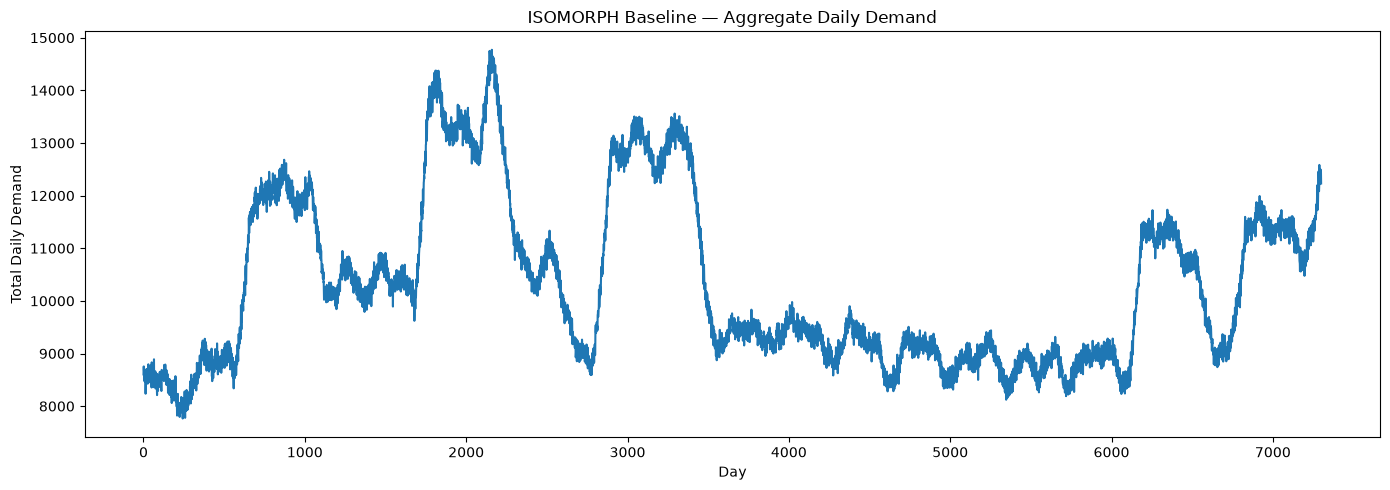

In [21]:
import matplotlib.pyplot as plt

# Aggregate demand across all 50 items
daily_total = (
    daily
    .groupby("day")["demand"]
    .sum()
)

plt.figure(figsize=(14, 5))
plt.plot(daily_total.index, daily_total.values)
plt.xlabel("Day")
plt.ylabel("Total Daily Demand")
plt.title("ISOMORPH Baseline — Aggregate Daily Demand")
plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# STEP 4 — ITEM-LEVEL SEASONALITY CHECK
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("ITEM-LEVEL SEASONALITY CHECK")
print("=" * 70)

# ------------------------------------------------------------
# Build item x day matrix
# ------------------------------------------------------------

demand_matrix = (
    daily
    .pivot(index="day", columns="item", values="demand")
    .sort_index()
)

print("\nMatrix shape:", demand_matrix.shape)

# ------------------------------------------------------------
# Autocorrelation by item
# ------------------------------------------------------------

lags = [1, 7, 14, 28, 365]

seasonality_results = []

for item in demand_matrix.columns:

    series = demand_matrix[item]

    row = {"item": item}

    for lag in lags:
        row[f"acf_{lag}"] = series.autocorr(lag=lag)

    seasonality_results.append(row)

seasonality_df = pd.DataFrame(
    seasonality_results
).set_index("item")

print("\nItem-level autocorrelation:")
display(seasonality_df.describe())

print("\nItems with strongest lag-7 autocorrelation:")
display(
    seasonality_df
    .sort_values("acf_7", ascending=False)
    .head(10)
)

print("\nItems with weakest lag-7 autocorrelation:")
display(
    seasonality_df
    .sort_values("acf_7", ascending=True)
    .head(10)
)

# ------------------------------------------------------------
# Compare candidate seasonal lags
# ------------------------------------------------------------

mean_acf = seasonality_df[
    ["acf_1", "acf_7", "acf_14", "acf_28", "acf_365"]
].mean()

print("\nMean item-level autocorrelation:")
print(mean_acf)

print("\nMedian item-level autocorrelation:")
print(
    seasonality_df[
        ["acf_1", "acf_7", "acf_14", "acf_28", "acf_365"]
    ].median()
)

print("\n" + "=" * 70)
print("STEP 4 COMPLETE")
print("=" * 70)

ITEM-LEVEL SEASONALITY CHECK

Matrix shape: (7300, 50)

Item-level autocorrelation:


,acf_1,acf_7,acf_14,acf_28,acf_365
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,0.933722,0.934612,0.918936,0.874858,0.505682
std,0.025607,0.024442,0.027736,0.039705,0.151595
min,0.860166,0.855749,0.830861,0.768349,0.206091
25%,0.920049,0.920422,0.903801,0.845019,0.407624
50%,0.937482,0.936771,0.916734,0.878200,0.488775
75%,0.952108,0.952384,0.939427,0.905756,0.629378
max,0.972665,0.972914,0.966613,0.950511,0.827147



Items with strongest lag-7 autocorrelation:


,acf_1,acf_7,acf_14,acf_28,acf_365
item,,,,,
I41,0.971513,0.972914,0.963080,0.934197,0.669716
I24,0.970515,0.972436,0.966613,0.950511,0.591875
I32,0.972665,0.968837,0.956314,0.922322,0.653558
I21,0.968172,0.967015,0.957933,0.931333,0.738274
I30,0.967237,0.966849,0.956304,0.931058,0.789472
I05,0.970547,0.966576,0.952911,0.916178,0.621560
I28,0.965304,0.962773,0.947406,0.905263,0.582716
I50,0.958739,0.959324,0.952962,0.936164,0.713025
I12,0.961430,0.958142,0.946267,0.916948,0.827147



Items with weakest lag-7 autocorrelation:


,acf_1,acf_7,acf_14,acf_28,acf_365
item,,,,,
I31,0.860166,0.855749,0.830861,0.768349,0.334510
I26,0.869752,0.884669,0.872784,0.827923,0.611895
I34,0.886055,0.888510,0.872587,0.818436,0.404728
I10,0.896840,0.897956,0.880280,0.828840,0.349076
I23,0.897856,0.899280,0.872721,0.812710,0.494761
I39,0.906322,0.912223,0.888971,0.829533,0.229187
I38,0.913544,0.912619,0.904316,0.880041,0.451844
I46,0.910289,0.913100,0.899149,0.868615,0.355256
I20,0.918490,0.913942,0.889902,0.820348,0.397676



Mean item-level autocorrelation:
acf_1      0.933722
acf_7      0.934612
acf_14     0.918936
acf_28     0.874858
acf_365    0.505682
dtype: float64

Median item-level autocorrelation:
acf_1      0.937482
acf_7      0.936771
acf_14     0.916734
acf_28     0.878200
acf_365    0.488775
dtype: float64

STEP 4 COMPLETE


In [20]:
!pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 8.5 MB/s eta 0:00:02
   ---- ----------------------------------- 1.0/9.3 MB 3.1 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.3 MB 3.9 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.3 MB 4.8 MB/s eta 0:00:02
   --------------------- ------------------ 5.0/9.3 MB 5.3 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.3 MB 5.5 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.3 MB 5.5 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.3 MB 5.5 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.3 MB 5.5 MB/s eta 0:00:01
   ----------------------------- -------

In [22]:
# ============================================================
# STEP 5 — CREATE FORECASTING MASTER DATASET
# ============================================================

import pandas as pd
import numpy as np

forecast_df = (
    daily[["day", "item", "demand"]]
    .copy()
    .sort_values(["item", "day"])
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Verify the panel structure
# ------------------------------------------------------------

print("=" * 70)
print("FORECASTING MASTER DATASET")
print("=" * 70)

print("\nShape:", forecast_df.shape)

print(
    "Unique items:",
    forecast_df["item"].nunique()
)

print(
    "Unique days:",
    forecast_df["day"].nunique()
)

print(
    "Duplicate day-item combinations:",
    forecast_df.duplicated(
        ["day", "item"]
    ).sum()
)

# ------------------------------------------------------------
# Define experimental periods
# ------------------------------------------------------------

TRAIN_END = 5099
VALIDATION_END = 6199
TEST_END = 7299

forecast_df["period"] = np.select(
    [
        forecast_df["day"] <= TRAIN_END,
        forecast_df["day"] <= VALIDATION_END,
        forecast_df["day"] <= TEST_END
    ],
    [
        "train",
        "validation",
        "test"
    ],
    default="outside"
)

print("\nPeriod counts:")
print(
    forecast_df
    .groupby("period")["day"]
    .agg(
        min_day="min",
        max_day="max",
        observations="size"
    )
)

# ------------------------------------------------------------
# Verify every item has complete periods
# ------------------------------------------------------------

print("\nObservations per item and period:")

period_counts = (
    forecast_df
    .groupby(["item", "period"])
    .size()
    .unstack(fill_value=0)
)

display(period_counts)

print("\nExpected:")
print("Train:       5100 observations per item")
print("Validation:  1100 observations per item")
print("Test:        1100 observations per item")

print("\n" + "=" * 70)
print("MASTER DATASET READY")
print("=" * 70)

FORECASTING MASTER DATASET

Shape: (365000, 3)
Unique items: 50
Unique days: 7300
Duplicate day-item combinations: 0

Period counts:
            min_day  max_day  observations
period                                    
test           6200     7299         55000
train             0     5099        255000
validation     5100     6199         55000

Observations per item and period:


period,test,train,validation
item,,,
I01,1100,5100,1100
I02,1100,5100,1100
I03,1100,5100,1100
I04,1100,5100,1100
I05,1100,5100,1100
I06,1100,5100,1100
I07,1100,5100,1100
I08,1100,5100,1100
I09,1100,5100,1100



Expected:
Train:       5100 observations per item
Validation:  1100 observations per item
Test:        1100 observations per item

MASTER DATASET READY


In [23]:
# ============================================================
# STEP 6 — TEMPORAL LEAKAGE CHECK
# ============================================================

print("=" * 70)
print("TEMPORAL LEAKAGE CHECK")
print("=" * 70)

for item in forecast_df["item"].unique():

    item_data = (
        forecast_df[
            forecast_df["item"] == item
        ]
        .sort_values("day")
    )

    train_max = (
        item_data.loc[
            item_data["period"] == "train",
            "day"
        ].max()
    )

    val_min = (
        item_data.loc[
            item_data["period"] == "validation",
            "day"
        ].min()
    )

    val_max = (
        item_data.loc[
            item_data["period"] == "validation",
            "day"
        ].max()
    )

    test_min = (
        item_data.loc[
            item_data["period"] == "test",
            "day"
        ].min()
    )

    if not train_max < val_min:
        raise AssertionError(
            f"Leakage detected for {item}: "
            f"train ends {train_max}, "
            f"validation starts {val_min}"
        )

    if not val_max < test_min:
        raise AssertionError(
            f"Leakage detected for {item}: "
            f"validation ends {val_max}, "
            f"test starts {test_min}"
        )

print("PASS — chronological ordering is valid.")

TEMPORAL LEAKAGE CHECK
PASS — chronological ordering is valid.


In [24]:
# ============================================================
# STEP 7 — LEAKAGE-SAFE FORECASTING FEATURES
# ============================================================

def create_lag_features(df):
    """
    Create forecasting features using only information
    available before the forecast date.
    """

    result = (
        df
        .sort_values(["item", "day"])
        .copy()
    )

    grouped = result.groupby("item")["demand"]

    # Lag features
    for lag in [1, 7, 14, 28]:
        result[f"lag_{lag}"] = grouped.shift(lag)

    # Rolling historical features
    result["rolling_mean_7"] = (
        grouped
        .shift(1)
        .rolling(7)
        .mean()
        .reset_index(level=0, drop=True)
    )

    result["rolling_mean_28"] = (
        grouped
        .shift(1)
        .rolling(28)
        .mean()
        .reset_index(level=0, drop=True)
    )

    result["rolling_std_28"] = (
        grouped
        .shift(1)
        .rolling(28)
        .std()
        .reset_index(level=0, drop=True)
    )

    # Calendar features
    result["day_of_week"] = (
        result["day"] % 7
    )

    result["week_of_year"] = (
        (result["day"] // 7) % 52
    )

    return result


model_df = create_lag_features(
    forecast_df[["day", "item", "demand"]]
)

# Restore experimental period
model_df["period"] = np.select(
    [
        model_df["day"] <= TRAIN_END,
        model_df["day"] <= VALIDATION_END,
        model_df["day"] <= TEST_END
    ],
    [
        "train",
        "validation",
        "test"
    ],
    default="outside"
)

print("=" * 70)
print("FEATURE DATASET")
print("=" * 70)

print("\nShape:", model_df.shape)

print("\nColumns:")
print(model_df.columns.tolist())

print("\nMissing values:")
print(
    model_df.isna().sum()
)

print("\nRows from first complete feature window:")
display(
    model_df[
        model_df["day"] >= 28
    ].head(10)
)

FEATURE DATASET

Shape: (365000, 13)

Columns:
['day', 'item', 'demand', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'rolling_std_28', 'day_of_week', 'week_of_year', 'period']

Missing values:
day                   0
item                  0
demand                0
lag_1                50
lag_7               350
lag_14              700
lag_28             1400
rolling_mean_7      350
rolling_mean_28    1400
rolling_std_28     1400
day_of_week           0
week_of_year          0
period                0
dtype: int64

Rows from first complete feature window:


,day,item,demand,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28,rolling_std_28,day_of_week,week_of_year,period
28,28,I01,168,198.0,190.0,191.0,197.0,183.142857,188.214286,13.411872,0,4,train
29,29,I01,169,168.0,166.0,172.0,168.0,180.000000,187.178571,13.821758,1,4,train
30,30,I01,198,169.0,175.0,194.0,176.0,180.428571,187.214286,13.771568,2,4,train
31,31,I01,168,198.0,188.0,185.0,182.0,183.714286,188.000000,13.735599,3,4,train
32,32,I01,197,168.0,186.0,180.0,188.0,180.857143,187.500000,14.208761,4,4,train
33,33,I01,203,197.0,179.0,211.0,211.0,182.428571,187.821429,14.321839,5,4,train
34,34,I01,217,203.0,198.0,209.0,221.0,185.857143,187.535714,13.916370,6,4,train
35,35,I01,177,217.0,168.0,190.0,183.0,188.571429,187.392857,13.576503,0,5,train
36,36,I01,178,177.0,169.0,166.0,183.0,189.857143,187.178571,13.695237,1,5,train
37,37,I01,192,178.0,198.0,175.0,180.0,191.142857,187.000000,13.784049,2,5,train


In [25]:
# ============================================================
# STEP 8 — FINAL DATASET SUMMARY
# ============================================================

feature_cols = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28",
    "day_of_week",
    "week_of_year"
]

print("=" * 70)
print("FINAL FORECASTING FEATURE SET")
print("=" * 70)

for feature in feature_cols:
    print(f"{feature:20s} : {model_df[feature].dtype}")

print("\nTarget:")
print("demand")

print("\nForecast horizon:")
print("7 days")

print("\nTraining:")
print("days 0–5099")

print("\nValidation:")
print("days 5100–6199")

print("\nTest:")
print("days 6200–7299")

print("\nFeature count:", len(feature_cols))

FINAL FORECASTING FEATURE SET
lag_1                : float64
lag_7                : float64
lag_14               : float64
lag_28               : float64
rolling_mean_7       : float64
rolling_mean_28      : float64
rolling_std_28       : float64
day_of_week          : int64
week_of_year         : int64

Target:
demand

Forecast horizon:
7 days

Training:
days 0–5099

Validation:
days 5100–6199

Test:
days 6200–7299

Feature count: 9


In [26]:
from pathlib import Path
import pandas as pd
import json

ROOT = Path(r"D:\ISOMORPH\thesis_outputs")

scenarios = [
    "normal",
    "demand_disruption",
    "supply_disruption",
    "combined_disruption",
]

for name in scenarios:

    path = ROOT / name

    print("\n" + "=" * 80)
    print(name.upper())
    print("=" * 80)

    files = sorted(p.name for p in path.iterdir())

    print("\nFiles:")
    for f in files:
        print(" ", f)

    # Scenario metadata
    scenario_path = path / "scenario.json"

    if scenario_path.exists():
        with open(scenario_path, "r", encoding="utf-8") as f:
            sc = json.load(f)

        print("\nScenario metadata:")
        for k, v in sc.items():
            print(f"  {k}: {v}")

    # Main daily data
    daily_path = path / "daily_records.csv"

    if daily_path.exists():
        df = pd.read_csv(daily_path)

        print("\nDaily records:")
        print(" shape:", df.shape)
        print(" days:", df["day"].min(), "->", df["day"].max())
        print(" items:", df["item"].nunique())

        print(
            " demand total:",
            df["demand"].sum()
        )

        print(
            " served total:",
            df["served_from_stock"].sum()
        )

        print(
            " backlog created:",
            df["new_backlog_today"].sum()
        )

        print(
            " fill rate:",
            df["served_from_stock"].sum()
            / df["demand"].sum()
        )

    # Supply-specific evidence
    availability_path = path / "source_availability.csv"

    if availability_path.exists():

        avail = pd.read_csv(
            availability_path
        )

        print("\nSource availability:")
        print(avail.head())

        print(
            "Total unavailable source-days:",
            int((avail["available"] == 0).sum())
        )

        print(
            "Sources affected:",
            avail.loc[
                avail["available"] == 0,
                "node"
            ].nunique()
        )


NORMAL

Files:
  backlog_history.csv
  daily_records.csv
  demand_signals.npy
  demand_signals_cols.txt
  intransit_history.csv
  inventory_history.csv
  reservoir_history.csv
  scenario.json
  service_summary.csv
  shipments.csv
  source_availability.csv

Scenario metadata:
  name: normal
  phi_lo: 0.999
  phi_hi: 0.9996
  shock_count_scale: 1.0
  shock_height_scale: 1.0
  seasonal_scale: 1.0
  containers_scale: 1.0
  ss_scale: 1.0
  leadtime_scale: 1.0
  burst_rate_scale: 1.0
  burst_height_scale: 1.0
  base_lambda_lo: 80.0
  base_lambda_hi: 250.0
  seed: 2025
  days: 7300
  n_items: 50
  disable_edges: []
  disable_from_day: -1
  disable_days: 0
  restore_ramp_days: 0
  prod_rate_per_item: None
  reservoir_cap_per_item: None
  init_frac: 1.0
  warehouse_cap_scale: None
  disruption_p_onset: 0.0
  disruption_length_days: 0
  edge_tt_std_frac: 0.0

Daily records:
 shape: (365000, 7)
 days: 0 -> 7299
 items: 50
 demand total: 75262671
 served total: 68841943
 backlog created: 6420728


In [27]:
# ============================================================
# DEMAND DISRUPTION TIMING ANALYSIS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path(r"D:\ISOMORPH\thesis_outputs")

normal = pd.read_csv(
    ROOT / "normal" / "daily_records.csv"
)

demand_disruption = pd.read_csv(
    ROOT / "demand_disruption" / "daily_records.csv"
)

# Aggregate demand by day
normal_daily = (
    normal
    .groupby("day")["demand"]
    .sum()
)

disrupted_daily = (
    demand_disruption
    .groupby("day")["demand"]
    .sum()
)

comparison = pd.DataFrame({
    "normal": normal_daily,
    "demand_disruption": disrupted_daily
})

comparison["absolute_change"] = (
    comparison["demand_disruption"]
    - comparison["normal"]
)

comparison["relative_change"] = (
    comparison["demand_disruption"]
    / comparison["normal"]
)

print("=" * 70)
print("DEMAND DISRUPTION TIMING")
print("=" * 70)

print("\nLargest demand days:")
display(
    comparison
    .sort_values(
        "absolute_change",
        ascending=False
    )
    .head(20)
)

print("\nDays with >50% demand increase:")
large_change = comparison[
    comparison["relative_change"] > 1.5
]

print(
    "Number of days:",
    len(large_change)
)

print(
    "First:",
    large_change.index.min()
)

print(
    "Last:",
    large_change.index.max()
)

print("\nDemand increase distribution:")

print(
    comparison["relative_change"].describe(
        percentiles=[
            .50,
            .75,
            .90,
            .95,
            .99
        ]
    )
)

DEMAND DISRUPTION TIMING

Largest demand days:


,normal,demand_disruption,absolute_change,relative_change
day,,,,
3687,9404,31341,21937,3.332731
3749,9273,31056,21783,3.349078
3694,9313,31059,21746,3.335016
3721,9255,30985,21730,3.347920
3750,9505,31226,21721,3.285218
3693,9450,31162,21712,3.297566
3707,9431,31141,21710,3.301983
3754,9371,31080,21709,3.316615
3684,9588,31261,21673,3.260430



Days with >50% demand increase:
Number of days: 1938
First: 1577
Last: 7299

Demand increase distribution:
count    7300.000000
mean        1.347620
std         0.437966
min         0.887373
50%         1.244369
75%         1.517985
90%         1.690382
95%         2.239059
99%         3.238395
max         3.349078
Name: relative_change, dtype: float64


In [28]:
# ============================================================
# SUPPLY DISRUPTION TIMING
# ============================================================

supply_availability = pd.read_csv(
    ROOT
    / "supply_disruption"
    / "source_availability.csv"
)

supply_availability["unavailable"] = (
    supply_availability["available"] == 0
)

daily_outage = (
    supply_availability
    .groupby("day")["unavailable"]
    .sum()
)

print("=" * 70)
print("SUPPLY DISRUPTION TIMING")
print("=" * 70)

print("\nDays with at least one source unavailable:")
print(
    (daily_outage > 0).sum()
)

print("\nDays with all three sources unavailable:")
print(
    (daily_outage == 3).sum()
)

print("\nOutage count by source:")
print(
    supply_availability
    .groupby("node")["unavailable"]
    .sum()
)

print("\nFirst outage day:")
print(
    daily_outage[daily_outage > 0].index.min()
)

print("\nLast outage day:")
print(
    daily_outage[daily_outage > 0].index.max()
)

print("\nOutage days:")
display(
    daily_outage[
        daily_outage > 0
    ].head(50)
)

SUPPLY DISRUPTION TIMING

Days with at least one source unavailable:
961

Days with all three sources unavailable:
0

Outage count by source:
node
Orlando         330
SanFrancisco    330
StLouis         330
Name: unavailable, dtype: int64

First outage day:
4

Last outage day:
6234

Outage days:


day
4      1
5      1
6      1
7      1
8      1
9      1
10     1
11     1
12     1
13     1
14     1
15     1
16     1
17     1
18     1
19     1
20     1
21     1
22     1
23     1
24     1
25     1
26     1
27     1
28     1
29     1
30     1
31     1
32     1
33     1
222    1
223    1
224    1
225    1
226    1
227    1
228    1
229    1
230    1
231    1
232    1
233    1
234    1
235    1
236    1
237    1
238    1
239    1
240    1
241    1
Name: unavailable, dtype: int64

In [29]:
# ============================================================
# SUPPLY DISRUPTION — DOWNSTREAM EFFECT
# ============================================================

normal = pd.read_csv(
    ROOT / "normal" / "daily_records.csv"
)

supply = pd.read_csv(
    ROOT / "supply_disruption" / "daily_records.csv"
)

normal_daily = (
    normal
    .groupby("day")
    .agg(
        demand=("demand", "sum"),
        served=("served_from_stock", "sum"),
        backlog=("new_backlog_today", "sum")
    )
)

supply_daily = (
    supply
    .groupby("day")
    .agg(
        demand=("demand", "sum"),
        served=("served_from_stock", "sum"),
        backlog=("new_backlog_today", "sum")
    )
)

supply_compare = pd.DataFrame({
    "normal_demand": normal_daily["demand"],
    "supply_demand": supply_daily["demand"],
    "normal_served": normal_daily["served"],
    "supply_served": supply_daily["served"],
    "normal_backlog": normal_daily["backlog"],
    "supply_backlog": supply_daily["backlog"],
})

supply_compare["served_change"] = (
    supply_compare["supply_served"]
    - supply_compare["normal_served"]
)

supply_compare["backlog_change"] = (
    supply_compare["supply_backlog"]
    - supply_compare["normal_backlog"]
)

print("=" * 70)
print("SUPPLY DISRUPTION DOWNSTREAM EFFECT")
print("=" * 70)

print("\nTotal served:")
print(
    "Normal:",
    supply_compare["normal_served"].sum()
)

print(
    "Supply disruption:",
    supply_compare["supply_served"].sum()
)

print("\nTotal newly created backlog:")
print(
    "Normal:",
    supply_compare["normal_backlog"].sum()
)

print(
    "Supply disruption:",
    supply_compare["supply_backlog"].sum()
)

print("\nLargest daily service deterioration:")
display(
    supply_compare
    .sort_values("served_change")
    .head(20)
)

print("\nLargest daily backlog increase:")
display(
    supply_compare
    .sort_values("backlog_change", ascending=False)
    .head(20)
)

SUPPLY DISRUPTION DOWNSTREAM EFFECT

Total served:
Normal: 68841943
Supply disruption: 68818521

Total newly created backlog:
Normal: 6420728
Supply disruption: 6444150

Largest daily service deterioration:


,normal_demand,supply_demand,normal_served,supply_served,normal_backlog,supply_backlog,served_change,backlog_change
day,,,,,,,,
3339,13122,13122,10544,8958,2578,4164,-1586,1586
3348,13211,13211,10671,9141,2540,4070,-1530,1530
3329,13297,13297,9678,8211,3619,5086,-1467,1467
2145,14749,14749,2602,1151,12147,13598,-1451,1451
3266,13196,13196,13122,11692,74,1504,-1430,1430
1889,13051,13051,5225,3795,7826,9256,-1430,1430
2335,10993,10993,2737,1359,8256,9634,-1378,1378
1883,13325,13325,5922,4556,7403,8769,-1366,1366
3327,13229,13229,10070,8714,3159,4515,-1356,1356



Largest daily backlog increase:


,normal_demand,supply_demand,normal_served,supply_served,normal_backlog,supply_backlog,served_change,backlog_change
day,,,,,,,,
3339,13122,13122,10544,8958,2578,4164,-1586,1586
3348,13211,13211,10671,9141,2540,4070,-1530,1530
3329,13297,13297,9678,8211,3619,5086,-1467,1467
2145,14749,14749,2602,1151,12147,13598,-1451,1451
1889,13051,13051,5225,3795,7826,9256,-1430,1430
3266,13196,13196,13122,11692,74,1504,-1430,1430
2335,10993,10993,2737,1359,8256,9634,-1378,1378
1883,13325,13325,5922,4556,7403,8769,-1366,1366
3327,13229,13229,10070,8714,3159,4515,-1356,1356


In [30]:
FROZEN_DIR = Path(r"D:\ISOMORPH\thesis_frozen\normal")

In [31]:
forecast_data = pd.read_csv(
    FROZEN_DIR / "daily_records.csv"
)

In [32]:
# ============================================================
# STEP 9 — FORECASTING EXPERIMENT CONFIGURATION
# ============================================================

FORECAST_HORIZON = 7

TRAIN_END = 5099
VALIDATION_END = 6199
TEST_END = 7299

SEASONAL_PERIOD = 7

print("=" * 70)
print("FORECASTING EXPERIMENT")
print("=" * 70)

print("Forecast horizon :", FORECAST_HORIZON)
print("Seasonal period  :", SEASONAL_PERIOD)
print("Training days    :", f"0-{TRAIN_END}")
print("Validation days  :", f"{TRAIN_END + 1}-{VALIDATION_END}")
print("Test days        :", f"{VALIDATION_END + 1}-{TEST_END}")

FORECASTING EXPERIMENT
Forecast horizon : 7
Seasonal period  : 7
Training days    : 0-5099
Validation days  : 5100-6199
Test days        : 6200-7299


In [33]:
# ============================================================
# STEP 10 — CLEAN FORECASTING PANEL
# ============================================================

forecast_panel = (
    forecast_data[
        ["day", "item", "demand"]
    ]
    .copy()
    .sort_values(["item", "day"])
    .reset_index(drop=True)
)

# Basic checks
assert forecast_panel["day"].min() == 0
assert forecast_panel["day"].max() == 7299
assert forecast_panel["item"].nunique() == 50

assert (
    forecast_panel
    .duplicated(["day", "item"])
    .sum()
    == 0
)

print("=" * 70)
print("FORECASTING PANEL")
print("=" * 70)

print("Shape:", forecast_panel.shape)
print("Items:", forecast_panel["item"].nunique())
print("Days:", forecast_panel["day"].nunique())

display(forecast_panel.head(10))

FORECASTING PANEL
Shape: (365000, 3)
Items: 50
Days: 7300


,day,item,demand
0,0,I01,197
1,1,I01,168
2,2,I01,176
3,3,I01,182
4,4,I01,188
5,5,I01,211
6,6,I01,221
7,7,I01,183
8,8,I01,183
9,9,I01,180


# Seasonal Naive Forecast - NORMAL

In [34]:
# ============================================================
# STEP 11 — SEASONAL NAÏVE FORECAST
# ============================================================

def seasonal_naive_forecast(
    series: pd.Series,
    forecast_horizon: int = 7,
    seasonal_period: int = 7
) -> np.ndarray:
    """
    Seasonal Naïve forecast.

    For horizon h:
        forecast[t+h] = observed[t+h-seasonal_period]

    The function assumes the series is ordered chronologically.
    """

    if len(series) < seasonal_period:
        raise ValueError(
            "Series is shorter than the seasonal period."
        )

    history = series.to_numpy(dtype=float)

    forecast = np.empty(forecast_horizon)

    for h in range(forecast_horizon):
        forecast[h] = history[
            -seasonal_period + h
        ]

    return forecast


# Example using one item and the end of the training period

example_item = "I01"

example_series = (
    forecast_panel[
        (forecast_panel["item"] == example_item)
        & (forecast_panel["day"] <= TRAIN_END)
    ]
    .sort_values("day")["demand"]
)

example_forecast = seasonal_naive_forecast(
    example_series,
    forecast_horizon=FORECAST_HORIZON,
    seasonal_period=SEASONAL_PERIOD
)

print("=" * 70)
print("SEASONAL NAÏVE EXAMPLE")
print("=" * 70)

print("Item:", example_item)
print("Forecast:", example_forecast)

SEASONAL NAÏVE EXAMPLE
Item: I01
Forecast: [141. 159. 152. 144. 148. 122. 162.]


In [35]:
# ============================================================
# STEP 12 — ROLLING SEASONAL NAÏVE EVALUATION
# ============================================================

import numpy as np
import pandas as pd


TEST_START = 6200
TEST_END = 7299
HORIZON = 7
SEASONAL_PERIOD = 7


def evaluate_seasonal_naive_item(
    item_data,
    test_start,
    test_end,
    horizon=7,
    seasonal_period=7
):
    """
    Evaluate Seasonal Naïve using rolling 7-day forecast origins.

    Each forecast uses only observations available before the
    forecast origin.
    """

    item_data = (
        item_data
        .sort_values("day")
        .reset_index(drop=True)
    )

    results = []

    # Forecast origins are spaced by the forecast horizon
    origins = range(
        test_start,
        test_end + 1,
        horizon
    )

    for origin in origins:

        forecast_days = list(
            range(
                origin,
                min(origin + horizon, test_end + 1)
            )
        )

        # Need the complete seasonal history before origin
        history = item_data[
            item_data["day"] < origin
        ]["demand"]

        if len(history) < seasonal_period:
            continue

        forecast = seasonal_naive_forecast(
            history,
            forecast_horizon=len(forecast_days),
            seasonal_period=seasonal_period
        )

        actual = (
            item_data[
                item_data["day"].isin(forecast_days)
            ]
            .sort_values("day")["demand"]
            .to_numpy(dtype=float)
        )

        if len(actual) != len(forecast):
            continue

        for day, pred, obs in zip(
            forecast_days,
            forecast,
            actual
        ):

            results.append({
                "item": item_data["item"].iloc[0],
                "forecast_origin": origin,
                "day": day,
                "forecast": float(pred),
                "actual": float(obs)
            })

    return pd.DataFrame(results)


# ------------------------------------------------------------
# Run for all 50 items
# ------------------------------------------------------------

naive_results = []

for item in forecast_panel["item"].unique():

    item_data = forecast_panel[
        forecast_panel["item"] == item
    ]

    item_result = evaluate_seasonal_naive_item(
        item_data,
        test_start=TEST_START,
        test_end=TEST_END,
        horizon=HORIZON,
        seasonal_period=SEASONAL_PERIOD
    )

    naive_results.append(item_result)

naive_results = pd.concat(
    naive_results,
    ignore_index=True
)


print("=" * 70)
print("SEASONAL NAÏVE TEST RESULTS")
print("=" * 70)

print("\nResult shape:")
print(naive_results.shape)

print("\nItems:")
print(naive_results["item"].nunique())

print("\nForecast days:")
print(
    naive_results["day"].min(),
    "→",
    naive_results["day"].max()
)

print("\nForecast sample:")
display(
    naive_results.head(15)
)

SEASONAL NAÏVE TEST RESULTS

Result shape:
(55000, 5)

Items:
50

Forecast days:
6200 → 7299

Forecast sample:


,item,forecast_origin,day,forecast,actual
0,I01,6200,6200,258.0,249.0
1,I01,6200,6201,224.0,234.0
2,I01,6200,6202,239.0,244.0
3,I01,6200,6203,237.0,257.0
4,I01,6200,6204,227.0,262.0
5,I01,6200,6205,252.0,277.0
6,I01,6200,6206,276.0,277.0
7,I01,6207,6207,249.0,280.0
8,I01,6207,6208,234.0,280.0
9,I01,6207,6209,244.0,293.0


In [36]:
# ============================================================
# STEP 13 — FORECAST ACCURACY METRICS
# ============================================================

def mae(y_true, y_pred):
    return np.mean(
        np.abs(
            np.asarray(y_true)
            - np.asarray(y_pred)
        )
    )


def rmse(y_true, y_pred):
    return np.sqrt(
        np.mean(
            (
                np.asarray(y_true)
                - np.asarray(y_pred)
            ) ** 2
        )
    )


def mase(
    y_true,
    y_pred,
    training_series,
    seasonal_period=7
):
    """
    Mean Absolute Scaled Error.

    Scale = mean absolute seasonal-naïve error
    calculated on the training history.
    """

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    training_series = np.asarray(training_series)

    if len(training_series) <= seasonal_period:
        return np.nan

    scale = np.mean(
        np.abs(
            training_series[seasonal_period:]
            - training_series[:-seasonal_period]
        )
    )

    if scale == 0:
        return np.nan

    return np.mean(
        np.abs(y_true - y_pred)
    ) / scale


# ------------------------------------------------------------
# Calculate metrics per item
# ------------------------------------------------------------

metric_rows = []

for item in naive_results["item"].unique():

    item_results = naive_results[
        naive_results["item"] == item
    ]

    y_true = item_results["actual"].to_numpy()
    y_pred = item_results["forecast"].to_numpy()

    training_series = (
        forecast_panel[
            (forecast_panel["item"] == item)
            & (forecast_panel["day"] <= TRAIN_END)
        ]
        .sort_values("day")["demand"]
        .to_numpy()
    )

    metric_rows.append({
        "item": item,
        "MAE": mae(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "MASE": mase(
            y_true,
            y_pred,
            training_series,
            seasonal_period=SEASONAL_PERIOD
        )
    })


naive_metrics = pd.DataFrame(metric_rows)


print("=" * 70)
print("SEASONAL NAÏVE METRICS")
print("=" * 70)

display(naive_metrics.head(10))

print("\nMean across items:")
print(
    naive_metrics[
        ["MAE", "RMSE", "MASE"]
    ].mean()
)

print("\nMedian across items:")
print(
    naive_metrics[
        ["MAE", "RMSE", "MASE"]
    ].median()
)

SEASONAL NAÏVE METRICS


,item,MAE,RMSE,MASE
0,I01,17.597273,22.495313,1.073650
1,I02,14.682727,18.521609,0.852981
2,I03,18.865455,24.507698,1.224986
3,I04,14.533636,18.508843,0.984673
4,I05,16.366364,21.628580,0.848127
5,I06,15.783636,19.905915,1.217675
6,I07,19.590000,24.620409,0.913252
7,I08,15.581818,19.439089,1.066815
8,I09,20.881818,27.010537,1.031944
9,I10,17.308182,21.603219,1.047429



Mean across items:
MAE     17.382436
RMSE    22.015008
MASE     1.024262
dtype: float64

Median across items:
MAE     17.042727
RMSE    21.471949
MASE     1.016109
dtype: float64


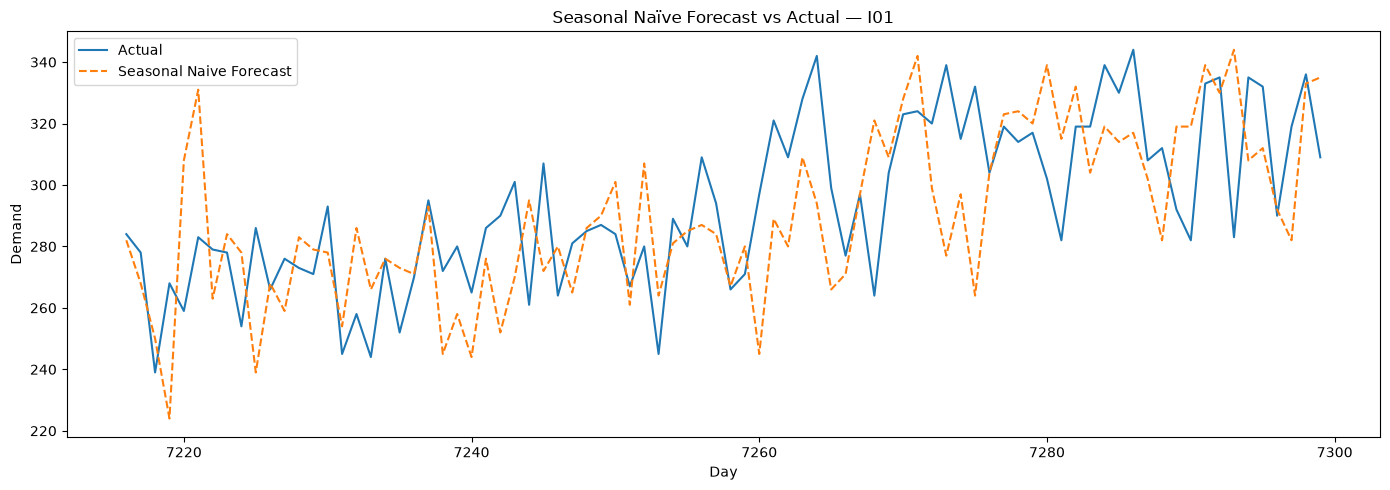

In [54]:
# ============================================================
# SEASONAL NAIVE — ACTUAL VS FORECAST
# ============================================================

import matplotlib.pyplot as plt

plot_item = "I01"

plot_data = (
    naive_results[
        naive_results["item"] == plot_item
    ]
    .sort_values("day")
    .tail(84)   # last 12 weeks of the test period
)

plt.figure(figsize=(14, 5))

plt.plot(
    plot_data["day"],
    plot_data["actual"],
    label="Actual"
)

plt.plot(
    plot_data["day"],
    plot_data["forecast"],
    label="Seasonal Naive Forecast",
    linestyle="--"
)

plt.xlabel("Day")
plt.ylabel("Demand")
plt.title(
    f"Seasonal Naïve Forecast vs Actual — {plot_item}"
)

plt.legend()
plt.tight_layout()
plt.show()


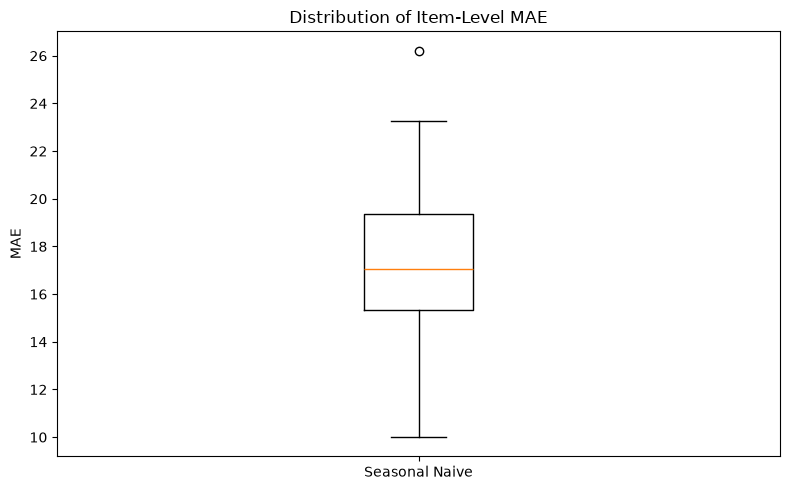

In [55]:
# ============================================================
# ITEM-LEVEL MAE DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

plt.boxplot(
    naive_metrics["MAE"],
    tick_labels=["Seasonal Naive"]
)

plt.ylabel("MAE")
plt.title("Distribution of Item-Level MAE")

plt.tight_layout()
plt.show()

# ETS Model - NORMAL

In [39]:
import sys
!{sys.executable} -m pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ----------------------------- ---------- 8.4/11.3 MB 52.1 MB/s eta 0:00:01
   ----------------------------- ---------- 8.4/11.3 MB 52.1 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 18.6 MB/s  0:00:00
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   ----------------- ---------------------- 16.3/36.7 MB 78.8 MB/s eta 0:00:01
   -------------------------------------- - 35.7/36.7 MB 87.2 MB/s eta 0:00:01
   ---------------------------------------- 36.7/36.7 MB 66.5 MB/s  0:00:00

   ---------------------------------------- 0/7 [wrapt]
   ---------------------------------------- 0/7 [wrapt]
   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [scipy]
 

In [40]:
import statsmodels

print("statsmodels version:", statsmodels.__version__)
print("Python:", sys.executable)

statsmodels version: 0.15.0
Python: D:\Anaconda\envs\isomorph\python.exe


In [41]:
# ============================================================
# STEP 14 — ETS SINGLE-ITEM VALIDATION TEST
# ============================================================

from statsmodels.tsa.holtwinters import ExponentialSmoothing

TEST_ITEM = "I01"

# Historical data available up to the end of training
item_history = (
    forecast_panel[
        (forecast_panel["item"] == TEST_ITEM)
        & (forecast_panel["day"] <= TRAIN_END)
    ]
    .sort_values("day")
)

y_train = item_history["demand"].astype(float).to_numpy()

# First validation window: forecast days 5100-5106
validation_actual = (
    forecast_panel[
        (forecast_panel["item"] == TEST_ITEM)
        & (forecast_panel["day"].between(
            TRAIN_END + 1,
            TRAIN_END + FORECAST_HORIZON
        ))
    ]
    .sort_values("day")["demand"]
    .astype(float)
    .to_numpy()
)

print("Training observations:", len(y_train))
print("Validation observations:", len(validation_actual))

# ------------------------------------------------------------
# Fit ETS
# ------------------------------------------------------------

ets_model = ExponentialSmoothing(
    y_train,
    trend=None,
    seasonal=None,
    initialization_method="estimated"
)

ets_fit = ets_model.fit(
    optimized=True
)

ets_forecast = ets_fit.forecast(
    FORECAST_HORIZON
)

print("\nETS forecast:")
print(np.round(ets_forecast, 2))

print("\nActual:")
print(validation_actual)

print("\nForecast errors:")
print(
    np.round(
        validation_actual - ets_forecast,
        2
    )
)

Training observations: 5100
Validation observations: 7

ETS forecast:
[145.75 145.75 145.75 145.75 145.75 145.75 145.75]

Actual:
[145. 143. 141. 132. 133. 160. 165.]

Forecast errors:
[ -0.75  -2.75  -4.75 -13.75 -12.75  14.25  19.25]


In [42]:
# ============================================================
# STEP 15 — ETS SPECIFICATION COMPARISON ON VALIDATION
# ============================================================

from statsmodels.tsa.holtwinters import ExponentialSmoothing

item = "I01"

train = (
    forecast_panel[
        (forecast_panel["item"] == item)
        & (forecast_panel["day"] <= TRAIN_END)
    ]
    .sort_values("day")
)

validation = (
    forecast_panel[
        (forecast_panel["item"] == item)
        & (forecast_panel["day"].between(
            TRAIN_END + 1,
            VALIDATION_END
        ))
    ]
    .sort_values("day")
)

y_train = train["demand"].astype(float).to_numpy()
y_val = validation["demand"].astype(float).to_numpy()

models = {
    "ETS_level": {
        "trend": None,
        "seasonal": None,
        "seasonal_periods": None
    },

    "ETS_trend": {
        "trend": "add",
        "seasonal": None,
        "seasonal_periods": None
    },

    "ETS_trend_weekly": {
        "trend": "add",
        "seasonal": "add",
        "seasonal_periods": 7
    }
}

validation_results = []

for name, config in models.items():

    try:

        model_kwargs = {
            "trend": config["trend"],
            "seasonal": config["seasonal"],
            "initialization_method": "estimated"
        }

        if config["seasonal_periods"] is not None:
            model_kwargs["seasonal_periods"] = (
                config["seasonal_periods"]
            )

        model = ExponentialSmoothing(
            y_train,
            **model_kwargs
        )

        fit = model.fit(
            optimized=True
        )

        forecast = fit.forecast(
            len(y_val)
        )

        validation_results.append({
            "model": name,
            "MAE": mae(y_val, forecast),
            "RMSE": rmse(y_val, forecast)
        })

    except Exception as e:

        validation_results.append({
            "model": name,
            "MAE": np.nan,
            "RMSE": np.nan,
            "error": str(e)
        })

ets_validation = pd.DataFrame(
    validation_results
)

print("=" * 70)
print("ETS VALIDATION COMPARISON — I01")
print("=" * 70)

display(
    ets_validation.sort_values("MAE")
)

ETS VALIDATION COMPARISON — I01


,model,MAE,RMSE
0,ETS_level,32.602154,41.574439
1,ETS_trend,148.490424,171.304147
2,ETS_trend_weekly,206.103552,236.292949


In [43]:
# ============================================================
# STEP 16 — ETS SPECIFICATION SELECTION ACROSS ALL ITEMS
# ============================================================

from statsmodels.tsa.holtwinters import ExponentialSmoothing
import numpy as np
import pandas as pd

ETS_SPECS = {
    "ETS_level": {
        "trend": None,
        "seasonal": None,
        "seasonal_periods": None
    },

    "ETS_trend": {
        "trend": "add",
        "seasonal": None,
        "seasonal_periods": None
    },

    "ETS_trend_weekly": {
        "trend": "add",
        "seasonal": "add",
        "seasonal_periods": 7
    }
}

ets_item_results = []

items = sorted(
    forecast_panel["item"].unique()
)

for item_idx, item in enumerate(items, start=1):

    train = (
        forecast_panel[
            (forecast_panel["item"] == item)
            & (forecast_panel["day"] <= TRAIN_END)
        ]
        .sort_values("day")
    )

    validation = (
        forecast_panel[
            (forecast_panel["item"] == item)
            & (
                forecast_panel["day"].between(
                    TRAIN_END + 1,
                    VALIDATION_END
                )
            )
        ]
        .sort_values("day")
    )

    y_train = train["demand"].astype(float).to_numpy()
    y_val = validation["demand"].astype(float).to_numpy()

    for spec_name, config in ETS_SPECS.items():

        try:

            kwargs = {
                "trend": config["trend"],
                "seasonal": config["seasonal"],
                "initialization_method": "estimated"
            }

            if config["seasonal_periods"] is not None:
                kwargs["seasonal_periods"] = (
                    config["seasonal_periods"]
                )

            model = ExponentialSmoothing(
                y_train,
                **kwargs
            )

            fitted = model.fit(
                optimized=True
            )

            prediction = fitted.forecast(
                len(y_val)
            )

            ets_item_results.append({
                "item": item,
                "model": spec_name,
                "MAE": mae(y_val, prediction),
                "RMSE": rmse(y_val, prediction)
            })

        except Exception as exc:

            ets_item_results.append({
                "item": item,
                "model": spec_name,
                "MAE": np.nan,
                "RMSE": np.nan,
                "error": str(exc)
            })

    if item_idx % 5 == 0:
        print(
            f"Completed {item_idx}/{len(items)} items"
        )


ets_item_results = pd.DataFrame(
    ets_item_results
)

print("\n" + "=" * 70)
print("ETS VALIDATION — ALL ITEMS")
print("=" * 70)

summary = (
    ets_item_results
    .groupby("model")
    [["MAE", "RMSE"]]
    .agg(["mean", "median"])
)

display(summary)

print("\nNumber of successful item fits:")
print(
    ets_item_results
    .groupby("model")["MAE"]
    .apply(lambda x: x.notna().sum())
)

print("\nMedian item MAE ranking:")
display(
    ets_item_results
    .groupby("model")["MAE"]
    .median()
    .sort_values()
)

Completed 5/50 items
Completed 10/50 items
Completed 15/50 items
Completed 20/50 items
Completed 25/50 items
Completed 30/50 items
Completed 35/50 items
Completed 40/50 items
Completed 45/50 items
Completed 50/50 items

ETS VALIDATION — ALL ITEMS


MAE                    RMSE            
                        mean      median        mean      median
model                                                           
ETS_level          53.491078   53.411250   63.641043   64.459158
ETS_trend         239.055330  152.739459  273.746672  169.155405
ETS_trend_weekly  250.647368  171.994440  286.807007  202.046268


Number of successful item fits:
model
ETS_level           50
ETS_trend           50
ETS_trend_weekly    50
Name: MAE, dtype: int64

Median item MAE ranking:


model
ETS_level            53.411250
ETS_trend           152.739459
ETS_trend_weekly    171.994440
Name: MAE, dtype: float64

In [44]:
# ============================================================
# LOCKED ETS SPECIFICATION
# ============================================================

ETS_CONFIG = {
    "trend": None,
    "seasonal": None,
    "seasonal_periods": None,
    "selection_basis": "50-item validation performance"
}

print("ETS specification LOCKED:")
print(ETS_CONFIG)

ETS specification LOCKED:
{'trend': None, 'seasonal': None, 'seasonal_periods': None, 'selection_basis': '50-item validation performance'}


In [48]:
# ============================================================
# STEP 17 — ETS TEST EVALUATION — NORMAL CONDITION
# ============================================================

from statsmodels.tsa.holtwinters import ExponentialSmoothing
import numpy as np
import pandas as pd

TEST_START = 6200
TEST_END = 7299
HORIZON = 7

ets_test_results = []

items = sorted(
    forecast_panel["item"].unique()
)

for item_idx, item in enumerate(items, start=1):

    item_data = (
        forecast_panel[
            forecast_panel["item"] == item
        ]
        .sort_values("day")
    )

    origins = range(
        TEST_START,
        TEST_END + 1,
        HORIZON
    )

    for origin in origins:

        forecast_days = list(
            range(
                origin,
                min(origin + HORIZON, TEST_END + 1)
            )
        )

        # Only data available BEFORE the forecast origin
        history = item_data[
            item_data["day"] < origin
        ]["demand"].astype(float).to_numpy()

        actual = (
            item_data[
                item_data["day"].isin(forecast_days)
            ]
            .sort_values("day")["demand"]
            .astype(float)
            .to_numpy()
        )

        if len(actual) != len(forecast_days):
            continue

        if len(history) < 30:
            continue

        # Locked ETS specification:
        # level only, no trend, no seasonality
        model = ExponentialSmoothing(
            history,
            trend=None,
            seasonal=None,
            initialization_method="estimated"
        )

        fitted = model.fit(
            optimized=True
        )

        prediction = fitted.forecast(
            len(forecast_days)
        )

        for day, pred, obs in zip(
            forecast_days,
            prediction,
            actual
        ):
            ets_test_results.append({
                "item": item,
                "forecast_origin": origin,
                "day": day,
                "forecast": float(pred),
                "actual": float(obs)
            })

    if item_idx % 5 == 0:
        print(
            f"Completed {item_idx}/{len(items)} items"
        )

ets_test_results = pd.DataFrame(
    ets_test_results
)

print("\n" + "=" * 70)
print("ETS TEST RESULTS — NORMAL CONDITION")
print("=" * 70)

print("\nShape:", ets_test_results.shape)
print("Items:", ets_test_results["item"].nunique())
print(
    "Days:",
    ets_test_results["day"].min(),
    "→",
    ets_test_results["day"].max()
)

display(
    ets_test_results.head(15)
)

Completed 5/50 items
Completed 10/50 items
Completed 15/50 items
Completed 20/50 items
Completed 25/50 items
Completed 30/50 items
Completed 35/50 items
Completed 40/50 items
Completed 45/50 items
Completed 50/50 items

ETS TEST RESULTS — NORMAL CONDITION

Shape: (55000, 5)
Items: 50
Days: 6200 → 7299


,item,forecast_origin,day,forecast,actual
0,I01,6200,6200,249.929930,249.0
1,I01,6200,6201,249.929930,234.0
2,I01,6200,6202,249.929930,244.0
3,I01,6200,6203,249.929930,257.0
4,I01,6200,6204,249.929930,262.0
5,I01,6200,6205,249.929930,277.0
6,I01,6200,6206,249.929930,277.0
7,I01,6207,6207,261.592651,280.0
8,I01,6207,6208,261.592651,280.0
9,I01,6207,6209,261.592651,293.0


In [49]:
# ============================================================
# STEP 18 — ETS TEST METRICS
# ============================================================

ets_metric_rows = []

for item in ets_test_results["item"].unique():

    item_results = ets_test_results[
        ets_test_results["item"] == item
    ]

    y_true = item_results["actual"].to_numpy()
    y_pred = item_results["forecast"].to_numpy()

    training_series = (
        forecast_panel[
            (forecast_panel["item"] == item)
            & (forecast_panel["day"] <= TRAIN_END)
        ]
        .sort_values("day")["demand"]
        .astype(float)
        .to_numpy()
    )

    ets_metric_rows.append({
        "item": item,
        "MAE": mae(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "MASE": mase(
            y_true,
            y_pred,
            training_series,
            seasonal_period=SEASONAL_PERIOD
        )
    })

ets_metrics = pd.DataFrame(
    ets_metric_rows
)

print("=" * 70)
print("ETS TEST METRICS — NORMAL")
print("=" * 70)

print("\nMean across items:")
display(
    ets_metrics[
        ["MAE", "RMSE", "MASE"]
    ].mean()
)

print("\nMedian across items:")
display(
    ets_metrics[
        ["MAE", "RMSE", "MASE"]
    ].median()
)

print("\nPer-item results:")
display(
    ets_metrics.head(10)
)

ETS TEST METRICS — NORMAL

Mean across items:


MAE     15.714992
RMSE    19.762601
MASE     0.922967
dtype: float64


Median across items:


MAE     15.493123
RMSE    19.275373
MASE     0.895569
dtype: float64


Per-item results:


,item,MAE,RMSE,MASE
0,I01,15.380938,19.227166,0.938426
1,I02,12.837573,16.130922,0.745788
2,I03,17.889310,22.887648,1.161602
3,I04,11.592824,14.788476,0.785429
4,I05,15.673017,20.246793,0.812197
5,I06,13.378182,16.893203,1.032099
6,I07,19.459724,24.604545,0.907179
7,I08,13.006844,16.184875,0.890518
8,I09,18.872990,23.746621,0.932671
9,I10,14.417358,17.957838,0.872487


# Light GBM - NORMAL

In [51]:
!pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 13.9 MB/s  0:00:00


In [52]:
import lightgbm as lgb
print("LightGBM version:", lgb.__version__)

LightGBM version: 4.7.0


In [53]:
import pandas as pd
import numpy as np

DATA_PATH = r"D:\ISOMORPH\thesis_frozen\normal\daily_records.csv"

df = pd.read_csv(DATA_PATH)

forecast_panel = df[["day", "item", "demand"]].copy()
forecast_panel = forecast_panel.sort_values(["item", "day"]).reset_index(drop=True)

print("Shape:", forecast_panel.shape)
print("Items:", forecast_panel["item"].nunique())
print("Days:", forecast_panel["day"].min(), "→", forecast_panel["day"].max())

Shape: (365000, 3)
Items: 50
Days: 0 → 7299


In [56]:
data = forecast_panel.copy()

g = data.groupby("item")["demand"]

data["lag_1"] = g.shift(1)
data["lag_7"] = g.shift(7)
data["lag_14"] = g.shift(14)
data["lag_28"] = g.shift(28)

data["rolling_mean_7"] = g.shift(1).rolling(7).mean().reset_index(level=0, drop=True)
data["rolling_mean_28"] = g.shift(1).rolling(28).mean().reset_index(level=0, drop=True)
data["rolling_std_28"] = g.shift(1).rolling(28).std().reset_index(level=0, drop=True)

data["day_of_week"] = data["day"] % 7
data["week_of_year"] = (data["day"] // 7) % 52

features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28",
    "day_of_week",
    "week_of_year",
]

data = data.dropna(subset=features + ["demand"]).reset_index(drop=True)

print("Feature data shape:", data.shape)
print(data[["item", "day"] + features].head())

Feature data shape: (363600, 12)
  item  day  lag_1  lag_7  lag_14  lag_28  rolling_mean_7  rolling_mean_28  \
0  I01   28  198.0  190.0   191.0   197.0      183.142857       188.214286   
1  I01   29  168.0  166.0   172.0   168.0      180.000000       187.178571   
2  I01   30  169.0  175.0   194.0   176.0      180.428571       187.214286   
3  I01   31  198.0  188.0   185.0   182.0      183.714286       188.000000   
4  I01   32  168.0  186.0   180.0   188.0      180.857143       187.500000   

   rolling_std_28  day_of_week  week_of_year  
0       13.411872            0             4  
1       13.821758            1             4  
2       13.771568            2             4  
3       13.735599            3             4  
4       14.208761            4             4  


In [57]:
g.shift(1)

0           NaN
1         197.0
2         168.0
3         176.0
4         182.0
          ...  
364995    287.0
364996    292.0
364997    294.0
364998    301.0
364999    315.0
Name: demand, Length: 365000, dtype: float64

In [2]:
import sklearn
import lightgbm as lgb

print("scikit-learn:", sklearn.__version__)
print("LightGBM:", lgb.__version__)

import pandas as pd
import numpy as np

DATA_PATH = r"D:\ISOMORPH\thesis_frozen\normal\daily_records.csv"

df = pd.read_csv(DATA_PATH)

forecast_panel = df[["day", "item", "demand"]].copy()
forecast_panel = forecast_panel.sort_values(
    ["item", "day"]
).reset_index(drop=True)

g = forecast_panel.groupby("item")["demand"]

data = forecast_panel.copy()

data["lag_1"] = g.shift(1)
data["lag_7"] = g.shift(7)
data["lag_14"] = g.shift(14)
data["lag_28"] = g.shift(28)

data["rolling_mean_7"] = (
    g.shift(1).rolling(7).mean()
    .reset_index(level=0, drop=True)
)

data["rolling_mean_28"] = (
    g.shift(1).rolling(28).mean()
    .reset_index(level=0, drop=True)
)

data["rolling_std_28"] = (
    g.shift(1).rolling(28).std()
    .reset_index(level=0, drop=True)
)

data["day_of_week"] = data["day"] % 7
data["week_of_year"] = (data["day"] // 7) % 52

feature_cols = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28",
    "day_of_week",
    "week_of_year",
]

data = data.dropna(
    subset=feature_cols + ["demand"]
).reset_index(drop=True)

print("Feature data shape:", data.shape)
print("Items:", data["item"].nunique())

scikit-learn: 1.9.1
LightGBM: 4.7.0
Feature data shape: (363600, 12)
Items: 50


In [3]:
import lightgbm as lgb
import pandas as pd
import numpy as np

TRAIN_END = 5099
VAL_START = 5100
VAL_END = 6199

params = {
    "objective": "regression",
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 2025,
    "verbosity": -1,
}

feature_cols = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28",
    "day_of_week",
    "week_of_year",
]

all_val_results = []

for item in sorted(data["item"].unique()):

    item_data = data[data["item"] == item].copy()

    train = item_data[item_data["day"] <= TRAIN_END]
    val = item_data[
        (item_data["day"] >= VAL_START) &
        (item_data["day"] <= VAL_END)
    ]

    X_train = train[feature_cols]
    y_train = train["demand"]

    X_val = val[feature_cols]
    y_val = val["demand"]

    model = lgb.LGBMRegressor(**params)
    model.fit(X_train, y_train)

    pred = model.predict(X_val)

    result = pd.DataFrame({
        "item": item,
        "day": val["day"].values,
        "forecast": pred,
        "actual": y_val.values
    })

    all_val_results.append(result)

lightgbm_val = pd.concat(all_val_results, ignore_index=True)

print("=" * 70)
print("LIGHTGBM VALIDATION RESULTS — NORMAL")
print("=" * 70)
print("Shape:", lightgbm_val.shape)
print("Items:", lightgbm_val["item"].nunique())
print("Days:", lightgbm_val["day"].min(), "→", lightgbm_val["day"].max())

LIGHTGBM VALIDATION RESULTS — NORMAL
Shape: (55000, 4)
Items: 50
Days: 5100 → 6199


In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def mase(actual, forecast, training_values, seasonality=1):
    actual = np.asarray(actual)
    forecast = np.asarray(forecast)
    training_values = np.asarray(training_values)

    naive_errors = np.abs(
        training_values[seasonality:] -
        training_values[:-seasonality]
    )

    scale = np.mean(naive_errors)

    return np.mean(np.abs(actual - forecast)) / scale


item_metrics = []

for item in sorted(lightgbm_val["item"].unique()):

    val_item = lightgbm_val[
        lightgbm_val["item"] == item
    ]

    actual = val_item["actual"].values
    forecast = val_item["forecast"].values

    training_values = forecast_panel[
        (forecast_panel["item"] == item) &
        (forecast_panel["day"] <= TRAIN_END)
    ]["demand"].values

    mae = mean_absolute_error(actual, forecast)

    rmse = np.sqrt(
        mean_squared_error(actual, forecast)
    )

    item_mase = mase(
        actual,
        forecast,
        training_values,
        seasonality=7
    )

    item_metrics.append({
        "item": item,
        "MAE": mae,
        "RMSE": rmse,
        "MASE": item_mase
    })

lightgbm_val_metrics = pd.DataFrame(item_metrics)

print("=" * 70)
print("LIGHTGBM VALIDATION METRICS — NORMAL")
print("=" * 70)

print("\nMean across items:\n")
print(lightgbm_val_metrics[["MAE", "RMSE", "MASE"]].mean())

print("\nMedian across items:\n")
print(lightgbm_val_metrics[["MAE", "RMSE", "MASE"]].median())

LIGHTGBM VALIDATION METRICS — NORMAL

Mean across items:

MAE     12.622222
RMSE    16.232635
MASE     0.744098
dtype: float64

Median across items:

MAE     12.485998
RMSE    15.936315
MASE     0.723005
dtype: float64


In [5]:
TEST_START = 6200
TEST_END = 7299

all_test_results = []

for item in sorted(data["item"].unique()):

    item_data = data[data["item"] == item].copy()

    train = item_data[item_data["day"] <= TRAIN_END]

    test = item_data[
        (item_data["day"] >= TEST_START) &
        (item_data["day"] <= TEST_END)
    ]

    X_train = train[feature_cols]
    y_train = train["demand"]

    X_test = test[feature_cols]

    model = lgb.LGBMRegressor(**params)
    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    result = pd.DataFrame({
        "item": item,
        "day": test["day"].values,
        "forecast": pred,
        "actual": test["demand"].values
    })

    all_test_results.append(result)

lightgbm_test = pd.concat(
    all_test_results,
    ignore_index=True
)

print("=" * 70)
print("LIGHTGBM TEST RESULTS — NORMAL")
print("=" * 70)
print("Shape:", lightgbm_test.shape)
print("Items:", lightgbm_test["item"].nunique())
print(
    "Days:",
    lightgbm_test["day"].min(),
    "→",
    lightgbm_test["day"].max()
)

LIGHTGBM TEST RESULTS — NORMAL
Shape: (55000, 4)
Items: 50
Days: 6200 → 7299


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

def mase(actual, forecast, training_values, seasonality=7):
    actual = np.asarray(actual)
    forecast = np.asarray(forecast)
    training_values = np.asarray(training_values)

    naive_errors = np.abs(
        training_values[seasonality:] -
        training_values[:-seasonality]
    )

    scale = np.mean(naive_errors)

    return np.mean(np.abs(actual - forecast)) / scale


item_metrics = []

for item in sorted(lightgbm_test["item"].unique()):

    test_item = lightgbm_test[
        lightgbm_test["item"] == item
    ]

    actual = test_item["actual"].values
    forecast = test_item["forecast"].values

    training_values = forecast_panel[
        (forecast_panel["item"] == item) &
        (forecast_panel["day"] <= TRAIN_END)
    ]["demand"].values

    mae = mean_absolute_error(actual, forecast)

    rmse = np.sqrt(
        mean_squared_error(actual, forecast)
    )

    item_mase = mase(
        actual,
        forecast,
        training_values,
        seasonality=7
    )

    item_metrics.append({
        "item": item,
        "MAE": mae,
        "RMSE": rmse,
        "MASE": item_mase
    })

lightgbm_test_metrics = pd.DataFrame(item_metrics)

print("=" * 70)
print("LIGHTGBM TEST METRICS — NORMAL")
print("=" * 70)

print("\nMean across items:\n")
print(
    lightgbm_test_metrics[
        ["MAE", "RMSE", "MASE"]
    ].mean()
)

print("\nMedian across items:\n")
print(
    lightgbm_test_metrics[
        ["MAE", "RMSE", "MASE"]
    ].median()
)

print("\nPer-item results:\n")
print(lightgbm_test_metrics)

LIGHTGBM TEST METRICS — NORMAL

Mean across items:

MAE     15.761615
RMSE    20.108145
MASE     0.944904
dtype: float64

Median across items:

MAE     14.070929
RMSE    17.969237
MASE     0.801045
dtype: float64

Per-item results:

   item        MAE       RMSE      MASE
0   I01  14.346915  18.114907  0.875338
1   I02  11.334762  14.145362  0.658484
2   I03  20.502572  31.878876  1.331288
3   I04  10.826830  13.898367  0.733532
4   I05  12.365974  16.062789  0.640821
5   I06  12.199317  15.396703  0.941152
6   I07  15.237844  19.302636  0.710362
7   I08  12.467856  15.525893  0.853616
8   I09  16.742770  21.172478  0.827399
9   I10  13.024605  16.450435  0.788202
10  I11  12.730551  16.106844  0.778361
11  I12  10.464953  13.258682  0.586027
12  I13  13.567946  17.332671  0.748371
13  I14  12.942243  18.047043  0.827806
14  I15  14.866871  18.935145  0.707225
15  I16   9.031944  11.482965  0.664255
16  I17   9.770007  12.307664  0.761511
17  I18  13.595259  16.889343  0.773293
18  I19

In [7]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import lightgbm as lgb

# ============================================================
# SETTINGS
# ============================================================

DATA_PATH = r"D:\ISOMORPH\thesis_frozen\normal\daily_records.csv"

TRAIN_END = 5099
TEST_START = 6200
TEST_END = 7299
HORIZON = 7
SEASONAL_PERIOD = 7

# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(DATA_PATH)

panel = (
    df[["day", "item", "demand"]]
    .sort_values(["item", "day"])
    .reset_index(drop=True)
)

items = sorted(panel["item"].unique())

# ============================================================
# MASE FUNCTION
# ============================================================

def calculate_mase(actual, forecast, training, seasonality=7):
    actual = np.asarray(actual)
    forecast = np.asarray(forecast)
    training = np.asarray(training)

    scale = np.mean(
        np.abs(training[seasonality:] - training[:-seasonality])
    )

    return np.mean(np.abs(actual - forecast)) / scale


# ============================================================
# 1. SEASONAL NAIVE — 7-DAY BLOCK FORECAST
# ============================================================

seasonal_rows = []

for item in items:

    item_series = (
        panel[panel["item"] == item]
        .set_index("day")["demand"]
    )

    train = item_series.loc[:TRAIN_END]

    for origin in range(TEST_START, TEST_END + 1, HORIZON):

        horizon_days = np.arange(
            origin,
            min(origin + HORIZON, TEST_END + 1)
        )

        forecasts = [
            item_series.loc[day - SEASONAL_PERIOD]
            for day in horizon_days
        ]

        actuals = [
            item_series.loc[day]
            for day in horizon_days
        ]

        for day, forecast, actual in zip(
            horizon_days, forecasts, actuals
        ):
            seasonal_rows.append({
                "item": item,
                "day": day,
                "forecast": forecast,
                "actual": actual
            })

seasonal_test = pd.DataFrame(seasonal_rows)


# ============================================================
# 2. ETS LEVEL — 7-DAY BLOCK FORECAST
# ============================================================

ets_rows = []

for item in items:

    item_series = (
        panel[panel["item"] == item]
        .set_index("day")["demand"]
    )

    train = item_series.loc[:TRAIN_END]

    for origin in range(TEST_START, TEST_END + 1, HORIZON):

        horizon_days = np.arange(
            origin,
            min(origin + HORIZON, TEST_END + 1)
        )

        model = ExponentialSmoothing(
            train,
            trend=None,
            seasonal=None
        ).fit(optimized=True)

        forecast_values = model.forecast(len(horizon_days))

        actuals = item_series.loc[horizon_days].values

        for day, forecast, actual in zip(
            horizon_days,
            forecast_values,
            actuals
        ):
            ets_rows.append({
                "item": item,
                "day": day,
                "forecast": float(forecast),
                "actual": float(actual)
            })

        # Expand training window for next weekly origin
        train = item_series.loc[
            :min(origin + HORIZON - 1, TEST_END)
        ]

ets_test = pd.DataFrame(ets_rows)


# ============================================================
# 3. LIGHTGBM — TRUE 7-DAY RECURSIVE FORECAST
# ============================================================

feature_cols = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28",
    "day_of_week",
    "week_of_year",
]

params = {
    "objective": "regression",
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 2025,
    "verbosity": -1,
}

lgb_rows = []

for item in items:

    item_series = (
        panel[panel["item"] == item]
        .set_index("day")["demand"]
        .astype(float)
    )

    history = list(item_series.loc[:TRAIN_END].values)

    # Train one model using training data only
    train_df = pd.DataFrame({
        "demand": history
    })

    g = train_df["demand"]

    X = pd.DataFrame({
        "lag_1": g.shift(1),
        "lag_7": g.shift(7),
        "lag_14": g.shift(14),
        "lag_28": g.shift(28),
        "rolling_mean_7": g.shift(1).rolling(7).mean(),
        "rolling_mean_28": g.shift(1).rolling(28).mean(),
        "rolling_std_28": g.shift(1).rolling(28).std(),
    })

    X["day_of_week"] = np.arange(len(train_df)) % 7
    X["week_of_year"] = (np.arange(len(train_df)) // 7) % 52

    valid = X.notna().all(axis=1)

    X_train = X.loc[valid, feature_cols]
    y_train = train_df.loc[valid, "demand"]

    model = lgb.LGBMRegressor(**params)
    model.fit(X_train, y_train)

    # Recursive 7-day blocks
    for origin in range(TEST_START, TEST_END + 1, HORIZON):

        block_end = min(origin + HORIZON - 1, TEST_END)

        for day in range(origin, block_end + 1):

            h = np.asarray(history, dtype=float)

            row = pd.DataFrame([{
                "lag_1": h[-1],
                "lag_7": h[-7],
                "lag_14": h[-14],
                "lag_28": h[-28],
                "rolling_mean_7": np.mean(h[-7:]),
                "rolling_mean_28": np.mean(h[-28:]),
                "rolling_std_28": np.std(h[-28:], ddof=1),
                "day_of_week": day % 7,
                "week_of_year": (day // 7) % 52
            }])

            prediction = float(model.predict(row[feature_cols])[0])

            actual = float(item_series.loc[day])

            lgb_rows.append({
                "item": item,
                "day": day,
                "forecast": prediction,
                "actual": actual
            })

            # Recursive: prediction becomes history
            history.append(prediction)

        # IMPORTANT:
        # Reset history to actual observations at the next forecast origin.
        # This keeps each 7-day forecast independently anchored
        # to information available at that forecast origin.
        history = list(
            item_series.loc[:block_end].values
        )

lgb_test = pd.DataFrame(lgb_rows)


# ============================================================
# AGGREGATE METRICS — SAME CALCULATION FOR ALL 3
# ============================================================

def model_metrics(result_df):

    results = []

    for item in items:

        r = result_df[result_df["item"] == item]

        actual = r["actual"].values
        forecast = r["forecast"].values

        training = panel[
            (panel["item"] == item) &
            (panel["day"] <= TRAIN_END)
        ]["demand"].values

        mae = mean_absolute_error(actual, forecast)

        rmse = np.sqrt(
            mean_squared_error(actual, forecast)
        )

        mase = calculate_mase(
            actual,
            forecast,
            training,
            seasonality=7
        )

        results.append({
            "item": item,
            "MAE": mae,
            "RMSE": rmse,
            "MASE": mase
        })

    return pd.DataFrame(results)


seasonal_metrics = model_metrics(seasonal_test)
ets_metrics = model_metrics(ets_test)
lgb_metrics = model_metrics(lgb_test)


# ============================================================
# FINAL OVERALL TABLE
# ============================================================

final_forecast_metrics = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "ETS Level",
        "LightGBM"
    ],
    "Mean MAE": [
        seasonal_metrics["MAE"].mean(),
        ets_metrics["MAE"].mean(),
        lgb_metrics["MAE"].mean()
    ],
    "Mean RMSE": [
        seasonal_metrics["RMSE"].mean(),
        ets_metrics["RMSE"].mean(),
        lgb_metrics["RMSE"].mean()
    ],
    "Mean MASE": [
        seasonal_metrics["MASE"].mean(),
        ets_metrics["MASE"].mean(),
        lgb_metrics["MASE"].mean()
    ],
    "Median MAE": [
        seasonal_metrics["MAE"].median(),
        ets_metrics["MAE"].median(),
        lgb_metrics["MAE"].median()
    ],
    "Median RMSE": [
        seasonal_metrics["RMSE"].median(),
        ets_metrics["RMSE"].median(),
        lgb_metrics["RMSE"].median()
    ],
    "Median MASE": [
        seasonal_metrics["MASE"].median(),
        ets_metrics["MASE"].median(),
        lgb_metrics["MASE"].median()
    ]
})

print("=" * 90)
print("FINAL FORECAST METRICS — NORMAL CONDITION")
print("=" * 90)
print(final_forecast_metrics.round(4).to_string(index=False))

FINAL FORECAST METRICS — NORMAL CONDITION
         Model  Mean MAE  Mean RMSE  Mean MASE  Median MAE  Median RMSE  Median MASE
Seasonal Naive   17.3824    22.0150     1.0243     17.0427      21.4719       1.0161
     ETS Level   16.0561    20.7973     0.9438     15.7783      19.7109       0.9078
      LightGBM   16.9355    21.9865     1.0141     14.7410      19.3165       0.8494


In [8]:
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing


# ============================================================
# SETTINGS
# ============================================================

TRAIN_FINAL_END = 6199
TEST_START = 6200
TEST_END = 7299
HORIZON = 7
SEASONALITY = 7

items = sorted(panel["item"].unique())


# ============================================================
# MASE
# ============================================================

def calculate_mase(actual, forecast, training, seasonality=7):
    actual = np.asarray(actual)
    forecast = np.asarray(forecast)
    training = np.asarray(training)

    scale = np.mean(
        np.abs(training[seasonality:] - training[:-seasonality])
    )

    return np.mean(np.abs(actual - forecast)) / scale


# ============================================================
# 1. SEASONAL NAIVE
# ============================================================

seasonal_rows = []

for item in items:

    series = (
        panel[panel["item"] == item]
        .set_index("day")["demand"]
    )

    training = series.loc[:TRAIN_FINAL_END]

    for origin in range(TEST_START, TEST_END + 1, HORIZON):

        days = np.arange(
            origin,
            min(origin + HORIZON, TEST_END + 1)
        )

        for day in days:

            forecast = float(series.loc[day - SEASONALITY])
            actual = float(series.loc[day])

            seasonal_rows.append({
                "item": item,
                "day": day,
                "forecast": forecast,
                "actual": actual
            })

seasonal_test_final = pd.DataFrame(seasonal_rows)


# ============================================================
# 2. ETS LEVEL
#    FIT USING ALL DATA AVAILABLE THROUGH DAY 6199
# ============================================================

ets_rows = []

for item in items:

    series = (
        panel[panel["item"] == item]
        .set_index("day")["demand"]
    )

    # Information available before test begins
    history = series.loc[:TRAIN_FINAL_END]

    for origin in range(TEST_START, TEST_END + 1, HORIZON):

        days = np.arange(
            origin,
            min(origin + HORIZON, TEST_END + 1)
        )

        model = ExponentialSmoothing(
            history,
            trend=None,
            seasonal=None
        ).fit(optimized=True)

        forecasts = model.forecast(len(days))

        for day, forecast in zip(days, forecasts):

            ets_rows.append({
                "item": item,
                "day": day,
                "forecast": float(forecast),
                "actual": float(series.loc[day])
            })

        # At the next forecast origin, the preceding
        # 7 observed days become available.
        history = series.loc[:days[-1]]

ets_test_final = pd.DataFrame(ets_rows)


# ============================================================
# 3. LIGHTGBM
#    FEATURES ARE ALWAYS BUILT FROM INFORMATION AVAILABLE
#    AT THE FORECAST ORIGIN
# ============================================================

feature_cols = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28",
    "day_of_week",
    "week_of_year",
]

params = {
    "objective": "regression",
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 2025,
    "verbosity": -1,
}

lgb_rows = []

for item in items:

    series = (
        panel[panel["item"] == item]
        .set_index("day")["demand"]
        .astype(float)
    )

    # --------------------------------------------------------
    # Train model using ALL observations through day 6199
    # --------------------------------------------------------

    train_series = series.loc[:TRAIN_FINAL_END]

    train_df = pd.DataFrame({
        "demand": train_series.values
    })

    g = train_df["demand"]

    X_train = pd.DataFrame({
        "lag_1": g.shift(1),
        "lag_7": g.shift(7),
        "lag_14": g.shift(14),
        "lag_28": g.shift(28),
        "rolling_mean_7": g.shift(1).rolling(7).mean(),
        "rolling_mean_28": g.shift(1).rolling(28).mean(),
        "rolling_std_28": g.shift(1).rolling(28).std(),
    })

    days_train = train_series.index.values

    X_train["day_of_week"] = days_train % 7
    X_train["week_of_year"] = (days_train // 7) % 52

    valid = X_train.notna().all(axis=1)

    X_fit = X_train.loc[valid, feature_cols]
    y_fit = train_df.loc[valid, "demand"]

    model = lgb.LGBMRegressor(**params)
    model.fit(X_fit, y_fit)

    # --------------------------------------------------------
    # Rolling 7-day forecasts
    # --------------------------------------------------------

    for origin in range(TEST_START, TEST_END + 1, HORIZON):

        block_end = min(origin + HORIZON - 1, TEST_END)

        # At forecast origin, use only observed history
        history = list(series.loc[:origin - 1].values)

        for day in range(origin, block_end + 1):

            h = np.asarray(history, dtype=float)

            row = pd.DataFrame([{
                "lag_1": h[-1],
                "lag_7": h[-7],
                "lag_14": h[-14],
                "lag_28": h[-28],
                "rolling_mean_7": np.mean(h[-7:]),
                "rolling_mean_28": np.mean(h[-28:]),
                "rolling_std_28": np.std(h[-28:], ddof=1),
                "day_of_week": day % 7,
                "week_of_year": (day // 7) % 52
            }])

            prediction = float(
                model.predict(row[feature_cols])[0]
            )

            actual = float(series.loc[day])

            lgb_rows.append({
                "item": item,
                "day": day,
                "forecast": prediction,
                "actual": actual
            })

            # Recursive forecast within the 7-day horizon
            history.append(prediction)

lgb_test_final = pd.DataFrame(lgb_rows)


# ============================================================
# METRICS
# ============================================================

def calculate_item_metrics(result_df):

    rows = []

    for item in items:

        r = result_df[result_df["item"] == item]

        actual = r["actual"].values
        forecast = r["forecast"].values

        training = panel[
            (panel["item"] == item) &
            (panel["day"] <= TRAIN_FINAL_END)
        ]["demand"].values

        mae = mean_absolute_error(actual, forecast)

        rmse = np.sqrt(
            mean_squared_error(actual, forecast)
        )

        mase = calculate_mase(
            actual,
            forecast,
            training,
            seasonality=SEASONALITY
        )

        rows.append({
            "item": item,
            "MAE": mae,
            "RMSE": rmse,
            "MASE": mase
        })

    return pd.DataFrame(rows)


seasonal_metrics_final = calculate_item_metrics(
    seasonal_test_final
)

ets_metrics_final = calculate_item_metrics(
    ets_test_final
)

lgb_metrics_final = calculate_item_metrics(
    lgb_test_final
)


# ============================================================
# FINAL TABLE
# ============================================================

final_forecast_metrics = pd.DataFrame({

    "Model": [
        "Seasonal Naive",
        "ETS Level",
        "LightGBM"
    ],

    "Mean MAE": [
        seasonal_metrics_final["MAE"].mean(),
        ets_metrics_final["MAE"].mean(),
        lgb_metrics_final["MAE"].mean()
    ],

    "Mean RMSE": [
        seasonal_metrics_final["RMSE"].mean(),
        ets_metrics_final["RMSE"].mean(),
        lgb_metrics_final["RMSE"].mean()
    ],

    "Mean MASE": [
        seasonal_metrics_final["MASE"].mean(),
        ets_metrics_final["MASE"].mean(),
        lgb_metrics_final["MASE"].mean()
    ],

    "Median MAE": [
        seasonal_metrics_final["MAE"].median(),
        ets_metrics_final["MAE"].median(),
        lgb_metrics_final["MAE"].median()
    ],

    "Median RMSE": [
        seasonal_metrics_final["RMSE"].median(),
        ets_metrics_final["RMSE"].median(),
        lgb_metrics_final["RMSE"].median()
    ],

    "Median MASE": [
        seasonal_metrics_final["MASE"].median(),
        ets_metrics_final["MASE"].median(),
        lgb_metrics_final["MASE"].median()
    ]
})


print("=" * 95)
print("FINAL FORECAST METRICS — NORMAL CONDITION")
print("=" * 95)

print(
    final_forecast_metrics.round(4).to_string(index=False)
)


# ============================================================
# VERIFICATION CHECKS
# ============================================================

print("\n" + "=" * 95)
print("VERIFICATION")
print("=" * 95)

print(
    "Seasonal Naive:",
    seasonal_test_final.shape,
    "items =", seasonal_test_final["item"].nunique(),
    "days =", seasonal_test_final["day"].min(),
    "→", seasonal_test_final["day"].max()
)

print(
    "ETS:",
    ets_test_final.shape,
    "items =", ets_test_final["item"].nunique(),
    "days =", ets_test_final["day"].min(),
    "→", ets_test_final["day"].max()
)

print(
    "LightGBM:",
    lgb_test_final.shape,
    "items =", lgb_test_final["item"].nunique(),
    "days =", lgb_test_final["day"].min(),
    "→", lgb_test_final["day"].max()
)

FINAL FORECAST METRICS — NORMAL CONDITION
         Model  Mean MAE  Mean RMSE  Mean MASE  Median MAE  Median RMSE  Median MASE
Seasonal Naive   17.3824    22.0150     1.0363     17.0427      21.4719       1.0387
     ETS Level   15.7150    19.7626     0.9338     15.4931      19.2754       0.9127
      LightGBM   15.0352    19.4331     0.8974     14.2888      18.8403       0.8328

VERIFICATION
Seasonal Naive: (55000, 4) items = 50 days = 6200 → 7299
ETS: (55000, 4) items = 50 days = 6200 → 7299
LightGBM: (55000, 4) items = 50 days = 6200 → 7299


In [9]:
final_forecast_metrics.to_csv(
    r"D:\ISOMORPH\thesis_frozen\final_forecast_metrics_normal.csv",
    index=False
)

seasonal_metrics_final.to_csv(
    r"D:\ISOMORPH\thesis_frozen\seasonal_naive_item_metrics_normal.csv",
    index=False
)

ets_metrics_final.to_csv(
    r"D:\ISOMORPH\thesis_frozen\ets_item_metrics_normal.csv",
    index=False
)

lgb_metrics_final.to_csv(
    r"D:\ISOMORPH\thesis_frozen\lightgbm_item_metrics_normal.csv",
    index=False
)

print("Forecast results saved successfully.")

Forecast results saved successfully.


# Inventory Rankings - NORMAL

In [10]:
def forecast_driven_ship_target(
    backlog,
    forecast_next_7_days,
    in_transit,
    on_hand
):
    forecast_target = sum(forecast_next_7_days)

    order_qty = max(
        0,
        int(np.ceil(
            backlog
            + forecast_target
            - in_transit
            - on_hand
        ))
    )

    return forecast_target, order_qty


# ------------------------------------------------------------
# TEST CASE
# Same inventory state, different forecasts
# ------------------------------------------------------------

backlog = 100
in_transit = 200
on_hand = 500

forecast_A = [100, 100, 100, 100, 100, 100, 100]
forecast_B = [150, 150, 150, 150, 150, 150, 150]

target_A, order_A = forecast_driven_ship_target(
    backlog,
    forecast_A,
    in_transit,
    on_hand
)

target_B, order_B = forecast_driven_ship_target(
    backlog,
    forecast_B,
    in_transit,
    on_hand
)

print("=" * 70)
print("GATE 5 — FORECAST → INVENTORY DECISION TEST")
print("=" * 70)

print("Forecast A total:", target_A)
print("Order A:", order_A)

print("Forecast B total:", target_B)
print("Order B:", order_B)

print("\nVerification:")

if order_B > order_A:
    print("PASS ✅ Different forecasts produce different order quantities.")
else:
    print("FAIL ❌ Forecast is not influencing the decision.")

GATE 5 — FORECAST → INVENTORY DECISION TEST
Forecast A total: 700
Order A: 100
Forecast B total: 1050
Order B: 450

Verification:
PASS ✅ Different forecasts produce different order quantities.


In [14]:
import os
import numpy as np
import pandas as pd

from Supplychaingeo_item50_v2 import build_example_simulation_extended

# ============================================================
# SETTINGS
# ============================================================

SEED = 2025
PIPELINE_MULT = 7.0

RUN_DAYS = 6270
TEST_START = 6200
TEST_END = 6269

BASE_OUT = r"D:\ISOMORPH\gate6_control_6270"
ETS_OUT = r"D:\ISOMORPH\gate6_ets_6270"

os.makedirs(BASE_OUT, exist_ok=True)
os.makedirs(ETS_OUT, exist_ok=True)

# ============================================================
# PREPARE OBSERVED DEMAND
# ============================================================

observed = (
    panel[
        (panel["day"] >= 0) &
        (panel["day"] < RUN_DAYS)
    ]
    .pivot(index="day", columns="item", values="demand")
    .sort_index()
)

# ============================================================
# PREPARE ETS 7-DAY FORECAST TARGETS
#
# Our ETS forecasts are organised in 7-day blocks.
# For each day, use the total forecast for its forecast block.
# ============================================================

ets_forecasts = ets_test_final.copy()

ets_forecasts["block_start"] = (
    TEST_START
    + ((ets_forecasts["day"] - TEST_START) // 7) * 7
)

block_targets = (
    ets_forecasts
    .groupby(["item", "block_start"])["forecast"]
    .sum()
    .to_dict()
)

# ============================================================
# HELPER
# ============================================================

def build_sim(output_dir):

    sim, net, items_dict, dsig = build_example_simulation_extended(
        seed=SEED,
        horizon_days=RUN_DAYS,
        pipeline_multiplier=PIPELINE_MULT,
        streaming_out_dir=output_dir,
        packing="greedy",
        scenario={
            "name": "gate6_normal",
            "seed": SEED,
            "days": RUN_DAYS,
            "n_items": len(items_dict) if isinstance(items_dict, dict) else 50,
        }
    )

    return sim


# ============================================================
# RUN 1 — NATIVE CONTROL
# ============================================================

print("=" * 70)
print("GATE 6A — NATIVE ISOMORPH CONTROL")
print("=" * 70)

control_sim, _, control_items, _ = build_example_simulation_extended(
    seed=SEED,
    horizon_days=RUN_DAYS,
    pipeline_multiplier=PIPELINE_MULT,
    streaming_out_dir=BASE_OUT,
    packing="greedy",
    scenario={
        "name": "gate6_control",
        "seed": SEED,
        "days": RUN_DAYS,
        "n_items": 50,
    }
)

control_sim.run()

print("\nControl simulation complete.")


# ============================================================
# RUN 2 — ETS FORECAST-DRIVEN
#
# We set the pre-update EMA so that after today's actual-demand
# EMA update, 7 * EMA equals the ETS 7-day forecast total.
#
# This preserves the simulator's native shipment formula while
# replacing its demand target with the external forecast.
# ============================================================

print("\n" + "=" * 70)
print("GATE 6B — ETS FORECAST-DRIVEN")
print("=" * 70)

ets_sim, _, ets_items, _ = build_example_simulation_extended(
    seed=SEED,
    horizon_days=RUN_DAYS,
    pipeline_multiplier=PIPELINE_MULT,
    streaming_out_dir=ETS_OUT,
    packing="greedy",
    scenario={
        "name": "gate6_ets",
        "seed": SEED,
        "days": RUN_DAYS,
        "n_items": 50,
    }
)

original_step = ets_sim.step

def forecast_driven_step(day):

    if TEST_START <= day <= TEST_END:

        block_start = (
            TEST_START
            + ((day - TEST_START) // 7) * 7
        )

        for iid in ets_items:

            target = block_targets.get(
                (iid, block_start),
                None
            )

            if target is None:
                continue

            # Actual demand for today's EMA update
            dq = float(observed.loc[day, iid])

            # Native simulator:
            #
            # EMA_new =
            #     0.05*demand
            #     + 0.95*EMA_old
            #
            # Native shipment target:
            #
            # 7 * EMA_new
            #
            # We want:
            #
            # 7 * EMA_new = ETS 7-day forecast total
            #
            desired_ema = target / PIPELINE_MULT

            required_previous_ema = (
                desired_ema
                - 0.05 * dq
            ) / 0.95

            ets_sim.demand_ema[iid] = required_previous_ema

    original_step(day)


ets_sim.step = forecast_driven_step

ets_sim.run()

print("\nETS forecast-driven simulation complete.")


# ============================================================
# LOAD TEST-WINDOW OUTPUTS
# ============================================================

control_daily = pd.read_csv(
    os.path.join(BASE_OUT, "daily_records.csv")
)

ets_daily = pd.read_csv(
    os.path.join(ETS_OUT, "daily_records.csv")
)

control_daily = control_daily[
    (control_daily["day"] >= TEST_START) &
    (control_daily["day"] <= TEST_END)
].copy()

ets_daily = ets_daily[
    (ets_daily["day"] >= TEST_START) &
    (ets_daily["day"] <= TEST_END)
].copy()


# ============================================================
# TEST-WINDOW COMPARISON
# ============================================================

control_demand = control_daily["demand"].sum()
ets_demand = ets_daily["demand"].sum()

control_served = control_daily["served_from_stock"].sum()
ets_served = ets_daily["served_from_stock"].sum()

control_backlog = control_daily["new_backlog_today"].sum()
ets_backlog = ets_daily["new_backlog_today"].sum()

control_fill = control_served / control_demand
ets_fill = ets_served / ets_demand

comparison = pd.DataFrame({
    "Metric": [
        "Demand",
        "Served",
        "New backlog",
        "Fill rate"
    ],
    "Native Control": [
        control_demand,
        control_served,
        control_backlog,
        control_fill
    ],
    "ETS Forecast": [
        ets_demand,
        ets_served,
        ets_backlog,
        ets_fill
    ]
})

print("\n" + "=" * 70)
print("GATE 6 — OPERATIONAL COMPARISON")
print("=" * 70)

print(comparison.to_string(index=False))


# ============================================================
# SHIPMENT COMPARISON
# ============================================================

control_ship = pd.read_csv(
    os.path.join(BASE_OUT, "shipments.csv")
)

ets_ship = pd.read_csv(
    os.path.join(ETS_OUT, "shipments.csv")
)

control_ship_test = control_ship[
    (control_ship["day"] >= TEST_START) &
    (control_ship["day"] <= TEST_END)
]

ets_ship_test = ets_ship[
    (ets_ship["day"] >= TEST_START) &
    (ets_ship["day"] <= TEST_END)
]

control_units = control_ship_test["units"].sum()
ets_units = ets_ship_test["units"].sum()

print("\nShipment units during test window:")
print("Native Control:", control_units)
print("ETS Forecast:  ", ets_units)


# ============================================================
# PASS / FAIL
# ============================================================

print("\n" + "=" * 70)
print("GATE 6 VERIFICATION")
print("=" * 70)

operational_change = (
    control_served != ets_served
    or control_backlog != ets_backlog
    or control_units != ets_units
)

if operational_change:
    print(
        "PASS ✅ Forecast-driven decisions changed "
        "the actual simulated operation."
    )
else:
    print(
        "FAIL ❌ Forecast-driven decisions did not "
        "change the simulated operation."
    )

GATE 6A — NATIVE ISOMORPH CONTROL
Building day-level demand signals...
  Shape: (6270, 50)  (6270 days ≈ 17 years)
  Lambda: mean=195.6  min=13.1  max=662.5
  Demand vol: 24456/day  Last-mile cap: 31500/day  Ratio: 128.8%  (Philadelphia=5800 Baltimore=4700)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base magic (s,S))
  Warehouse caps: unlimited
  Disruption: p_onset=0.0 length=0d  Edge tt noise: std_frac=0.0
  Day   6270/6270 (100.0%)    8.3 days/s ETA      0s
  Simulation complete in 756.0s

Control simulation complete.

GATE 6B — ETS FORECAST-DRIVEN
Building day-level demand signals...
  Shape: (6270, 50)  (6270 days ≈ 17 years)
  Lambda: mean=195.6  min=13.1  max=662.5
  Demand vol: 24456/day  Last-mile cap: 31500/day  Ratio: 128.8%  (Philadelphia=5800 Baltimore=4700)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base magic (s,S))
  Warehouse caps: unlimited
  Disruption: p_onset=0.0 length=0d  Edge tt noise: std_frac=0.0
  Day   6270/6270 (100.0%)    8.5 days/s E

In [ ]:
import sys
import os

SIM_PATH = r"D:\ISOMORPH\simulator"

if SIM_PATH not in sys.path:
    sys.path.insert(0, SIM_PATH)

print("Simulator path exists:", os.path.exists(SIM_PATH))
print("v2 file exists:",
      os.path.exists(
          os.path.join(SIM_PATH, "Supplychaingeo_item50_v2.py")
      ))

from Supplychaingeo_item50_v2 import build_example_simulation_extended

print("v2 import: PASS ✅")

In [15]:
import pandas as pd
import numpy as np
import os

TEST_START = 6200
TEST_END = 6269

CONTROL_DIR = r"D:\ISOMORPH\gate6_control_6270"
ETS_DIR = r"D:\ISOMORPH\gate6_ets_6270"


def load_outputs(folder):

    daily = pd.read_csv(
        os.path.join(folder, "daily_records.csv")
    )

    inventory = pd.read_csv(
        os.path.join(folder, "inventory_history.csv")
    )

    backlog = pd.read_csv(
        os.path.join(folder, "backlog_history.csv")
    )

    shipments = pd.read_csv(
        os.path.join(folder, "shipments.csv")
    )

    # Restrict everything to the actual evaluation window
    daily = daily[
        (daily["day"] >= TEST_START) &
        (daily["day"] <= TEST_END)
    ].copy()

    inventory = inventory[
        (inventory["day"] >= TEST_START) &
        (inventory["day"] <= TEST_END)
    ].copy()

    backlog = backlog[
        (backlog["day"] >= TEST_START) &
        (backlog["day"] <= TEST_END)
    ].copy()

    shipments = shipments[
        (shipments["day"] >= TEST_START) &
        (shipments["day"] <= TEST_END)
    ].copy()

    return daily, inventory, backlog, shipments


def calculate_inventory_metrics(folder):

    daily, inventory, backlog, shipments = load_outputs(folder)

    # --------------------------------------------------------
    # Demand / service
    # --------------------------------------------------------

    total_demand = daily["demand"].sum()
    total_served = daily["served_from_stock"].sum()

    fill_rate = (
        total_served / total_demand
        if total_demand > 0 else np.nan
    )

    total_unfilled = daily["new_backlog_today"].sum()

    # --------------------------------------------------------
    # Destination inventory
    # --------------------------------------------------------

    destination_inv_daily = (
        inventory[inventory["node"] == "NewYork"]
        .groupby("day")["on_hand"]
        .sum()
    )

    avg_destination_inventory = (
        destination_inv_daily.mean()
    )

    max_destination_inventory = (
        destination_inv_daily.max()
    )

    # --------------------------------------------------------
    # Total network inventory
    # --------------------------------------------------------

    total_network_inv_daily = (
        inventory
        .groupby("day")["on_hand"]
        .sum()
    )

    avg_network_inventory = (
        total_network_inv_daily.mean()
    )

    max_network_inventory = (
        total_network_inv_daily.max()
    )

    # --------------------------------------------------------
    # Destination backlog
    # --------------------------------------------------------

    destination_backlog_daily = (
        backlog[backlog["node"] == "NewYork"]
        .groupby("day")["backlog"]
        .sum()
    )

    avg_destination_backlog = (
        destination_backlog_daily.mean()
    )

    final_destination_backlog = (
        destination_backlog_daily.iloc[-1]
        if len(destination_backlog_daily) > 0
        else 0
    )

    max_destination_backlog = (
        destination_backlog_daily.max()
        if len(destination_backlog_daily) > 0
        else 0
    )

    # --------------------------------------------------------
    # Shipments
    # --------------------------------------------------------

    total_shipped = shipments["units"].sum()

    return {
        "Fill rate": fill_rate,
        "Total unfilled demand": total_unfilled,
        "Average destination inventory":
            avg_destination_inventory,
        "Maximum destination inventory":
            max_destination_inventory,
        "Average total network inventory":
            avg_network_inventory,
        "Maximum total network inventory":
            max_network_inventory,
        "Average destination backlog":
            avg_destination_backlog,
        "Final destination backlog":
            final_destination_backlog,
        "Maximum destination backlog":
            max_destination_backlog,
        "Total shipment units":
            total_shipped
    }


control_metrics = calculate_inventory_metrics(CONTROL_DIR)
ets_metrics = calculate_inventory_metrics(ETS_DIR)

gate7 = pd.DataFrame({
    "Metric": list(control_metrics.keys()),
    "Native Control": list(control_metrics.values()),
    "ETS Forecast": list(ets_metrics.values())
})

print("=" * 90)
print("GATE 7 — CORRECTED INVENTORY PERFORMANCE MEASUREMENT")
print("=" * 90)

print(gate7.round(3).to_string(index=False))

GATE 7 — CORRECTED INVENTORY PERFORMANCE MEASUREMENT
                         Metric  Native Control  ETS Forecast
                      Fill rate           1.000         0.986
          Total unfilled demand           0.000     10717.000
  Average destination inventory       58053.271     63415.457
  Maximum destination inventory       59659.000     65160.000
Average total network inventory     1296316.286   1302416.586
Maximum total network inventory     1344636.000   1349210.000
    Average destination backlog           0.000       354.900
      Final destination backlog           0.000         0.000
    Maximum destination backlog           0.000      2145.000
           Total shipment units     4233712.000   4240501.000


In [17]:
import os
import numpy as np
import pandas as pd

from Supplychaingeo_item50_v2 import build_example_simulation_extended


# ============================================================
# SETTINGS
# ============================================================

SEED = 2025
PIPELINE_MULT = 7.0

RUN_DAYS = 6270
TEST_START = 6200
TEST_END = 6269

BASE_DIR = r"D:\ISOMORPH"

MODEL_DIRS = {
    "Seasonal Naive": os.path.join(
        BASE_DIR, "gate8_seasonal_naive_6270"
    ),
    "ETS": os.path.join(
        BASE_DIR, "gate8_ets_6270"
    ),
    "LightGBM": os.path.join(
        BASE_DIR, "gate8_lightgbm_6270"
    ),
}

# ============================================================
# LOAD THE SAME NORMAL DEMAND DATA
# ============================================================

DATA_PATH = (
    r"D:\ISOMORPH\thesis_frozen\normal\daily_records.csv"
)

normal_df = pd.read_csv(DATA_PATH)

panel_normal = (
    normal_df[["day", "item", "demand"]]
    .sort_values(["item", "day"])
    .reset_index(drop=True)
)

observed = (
    panel_normal
    .pivot(
        index="day",
        columns="item",
        values="demand"
    )
    .sort_index()
)

items = sorted(panel_normal["item"].unique())

print("=" * 80)
print("GATE 8 — 3-MODEL NORMAL INVENTORY TEST")
print("=" * 80)

print("Items:", len(items))
print("Test days:", TEST_START, "→", TEST_END)


# ============================================================
# PREPARE 7-DAY FORECAST TARGETS
# ============================================================

forecast_tables = {
    "Seasonal Naive": seasonal_test_final,
    "ETS": ets_test_final,
    "LightGBM": lgb_test_final,
}


def make_block_targets(forecast_df):

    x = forecast_df.copy()

    x["block_start"] = (
        TEST_START
        + ((x["day"] - TEST_START) // 7) * 7
    )

    return (
        x.groupby(
            ["item", "block_start"]
        )["forecast"]
        .sum()
        .to_dict()
    )


block_targets = {
    model: make_block_targets(forecast_df)
    for model, forecast_df in forecast_tables.items()
}


# ============================================================
# RUN ONE MODEL
# ============================================================

def run_model(model_name, block_target_dict):

    out_dir = MODEL_DIRS[model_name]
    os.makedirs(out_dir, exist_ok=True)

    print("\n" + "=" * 80)
    print(f"RUNNING: {model_name}")
    print("=" * 80)

    sim, net, sim_items, _ = (
        build_example_simulation_extended(
            seed=SEED,
            horizon_days=RUN_DAYS,
            pipeline_multiplier=PIPELINE_MULT,
            streaming_out_dir=out_dir,
            packing="greedy",
            scenario={
                "name": f"gate8_{model_name.lower()}",
                "seed": SEED,
                "days": RUN_DAYS,
                "n_items": 50,
            }
        )
    )

    original_step = sim.step

    def forecast_driven_step(day):

        if TEST_START <= day <= TEST_END:

            block_start = (
                TEST_START
                + ((day - TEST_START) // 7) * 7
            )

            for iid in sim_items:

                target = block_target_dict.get(
                    (iid, block_start),
                    None
                )

                if target is None:
                    continue

                actual_today = float(
                    observed.loc[day, iid]
                )

                # Force the simulator's post-EMA
                # 7-day pipeline target to equal
                # the model's 7-day forecast total.
                desired_ema = (
                    target / PIPELINE_MULT
                )

                required_previous_ema = (
                    desired_ema
                    - 0.05 * actual_today
                ) / 0.95

                sim.demand_ema[iid] = (
                    required_previous_ema
                )

        original_step(day)

    sim.step = forecast_driven_step

    sim.run()

    return out_dir


# ============================================================
# RUN ALL THREE
# ============================================================

for model_name, targets in block_targets.items():
    run_model(model_name, targets)


# ============================================================
# SCORECARD
# ============================================================

def calculate_scorecard(folder):

    daily = pd.read_csv(
        os.path.join(
            folder,
            "daily_records.csv"
        )
    )

    inv = pd.read_csv(
        os.path.join(
            folder,
            "inventory_history.csv"
        )
    )

    backlog = pd.read_csv(
        os.path.join(
            folder,
            "backlog_history.csv"
        )
    )

    shipments = pd.read_csv(
        os.path.join(
            folder,
            "shipments.csv"
        )
    )

    # -------------------------
    # Test window
    # -------------------------

    daily = daily[
        (daily["day"] >= TEST_START) &
        (daily["day"] <= TEST_END)
    ]

    inv = inv[
        (inv["day"] >= TEST_START) &
        (inv["day"] <= TEST_END)
    ]

    backlog = backlog[
        (backlog["day"] >= TEST_START) &
        (backlog["day"] <= TEST_END)
    ]

    shipments = shipments[
        (shipments["day"] >= TEST_START) &
        (shipments["day"] <= TEST_END)
    ]

    # -------------------------
    # Service
    # -------------------------

    demand = daily["demand"].sum()
    served = daily["served_from_stock"].sum()

    fill_rate = served / demand

    total_unfilled = (
        daily["new_backlog_today"].sum()
    )

    # -------------------------
    # Destination inventory
    # -------------------------

    dest_daily = (
        inv[inv["node"] == "NewYork"]
        .groupby("day")["on_hand"]
        .sum()
    )

    avg_dest_inventory = dest_daily.mean()

    # -------------------------
    # Total network inventory
    # -------------------------

    network_daily = (
        inv.groupby("day")["on_hand"]
        .sum()
    )

    avg_network_inventory = (
        network_daily.mean()
    )

    # -------------------------
    # Backlog
    # -------------------------

    dest_backlog_daily = (
        backlog[
            backlog["node"] == "NewYork"
        ]
        .groupby("day")["backlog"]
        .sum()
    )

    avg_backlog = dest_backlog_daily.mean()

    final_backlog = (
        dest_backlog_daily.iloc[-1]
        if len(dest_backlog_daily) > 0
        else 0
    )

    max_backlog = (
        dest_backlog_daily.max()
        if len(dest_backlog_daily) > 0
        else 0
    )

    # -------------------------
    # Shipments
    # -------------------------

    total_shipped = shipments["units"].sum()

    return {
        "Fill rate": fill_rate,
        "Total unfilled demand": total_unfilled,
        "Average destination inventory":
            avg_dest_inventory,
        "Average total network inventory":
            avg_network_inventory,
        "Average destination backlog":
            avg_backlog,
        "Final destination backlog":
            final_backlog,
        "Maximum destination backlog":
            max_backlog,
        "Total shipment units":
            total_shipped,
    }


results = []

for model_name, folder in MODEL_DIRS.items():

    metrics = calculate_scorecard(folder)

    row = {"Model": model_name}
    row.update(metrics)

    results.append(row)


gate8_results = pd.DataFrame(results)


# ============================================================
# VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("GATE 8 — NORMAL INVENTORY RESULTS")
print("=" * 80)

print(
    gate8_results
    .round(3)
    .to_string(index=False)
)

print("\n" + "=" * 80)
print("VERIFICATION")
print("=" * 80)

for model_name, folder in MODEL_DIRS.items():

    daily = pd.read_csv(
        os.path.join(
            folder,
            "daily_records.csv"
        )
    )

    print(
        f"{model_name}: "
        f"{len(daily):,} daily rows"
    )

print("\nExpected daily rows per model: 3,500")
print("(70 test days × 50 items)")

GATE 8 — 3-MODEL NORMAL INVENTORY TEST
Items: 50
Test days: 6200 → 6269

RUNNING: Seasonal Naive
Building day-level demand signals...
  Shape: (6270, 50)  (6270 days ≈ 17 years)
  Lambda: mean=195.6  min=13.1  max=662.5
  Demand vol: 24456/day  Last-mile cap: 31500/day  Ratio: 128.8%  (Philadelphia=5800 Baltimore=4700)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base magic (s,S))
  Warehouse caps: unlimited
  Disruption: p_onset=0.0 length=0d  Edge tt noise: std_frac=0.0
  Day   6270/6270 (100.0%)    8.5 days/s ETA      0s
  Simulation complete in 740.9s

RUNNING: ETS
Building day-level demand signals...
  Shape: (6270, 50)  (6270 days ≈ 17 years)
  Lambda: mean=195.6  min=13.1  max=662.5
  Demand vol: 24456/day  Last-mile cap: 31500/day  Ratio: 128.8%  (Philadelphia=5800 Baltimore=4700)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base magic (s,S))
  Warehouse caps: unlimited
  Disruption: p_onset=0.0 length=0d  Edge tt noise: std_frac=0.0
  Day   6270/6270 (100.0%)

In [18]:
# ============================================================
# GATE 8 — SAME-DEMAND VERIFICATION
# ============================================================

folders = MODEL_DIRS

demand_totals = {}
demand_by_day = {}

for model_name, folder in folders.items():

    daily = pd.read_csv(
        os.path.join(folder, "daily_records.csv")
    )

    test = daily[
        (daily["day"] >= TEST_START) &
        (daily["day"] <= TEST_END)
    ].copy()

    demand_totals[model_name] = test["demand"].sum()

    demand_by_day[model_name] = (
        test.groupby("day")["demand"].sum()
    )

print("=" * 80)
print("GATE 8 — SAME-DEMAND VERIFICATION")
print("=" * 80)

print("\nTotal demand by model:")

for model, value in demand_totals.items():
    print(f"{model}: {value:,.0f}")


same_totals = len(set(demand_totals.values())) == 1

same_daily = (
    demand_by_day["Seasonal Naive"]
    .equals(demand_by_day["ETS"])
    and
    demand_by_day["ETS"]
    .equals(demand_by_day["LightGBM"])
)

print("\nVerification:")

print(
    "Same total demand:",
    "PASS ✅" if same_totals else "FAIL ❌"
)

print(
    "Same demand every day:",
    "PASS ✅" if same_daily else "FAIL ❌"
)

if same_totals and same_daily:
    print("\nGATE 8: PASS ✅")
    print(
        "All three models experienced the same demand "
        "realization; differences are attributable to "
        "forecast-driven inventory decisions."
    )
else:
    print("\nGATE 8: FAIL ❌")

GATE 8 — SAME-DEMAND VERIFICATION

Total demand by model:
Seasonal Naive: 747,750
ETS: 747,750
LightGBM: 747,750

Verification:
Same total demand: PASS ✅
Same demand every day: PASS ✅

GATE 8: PASS ✅
All three models experienced the same demand realization; differences are attributable to forecast-driven inventory decisions.


In [ ]:
import os
import numpy as np
import pandas as pd

from Supplychaingeo_item50_v2 import build_example_simulation_extended


# ============================================================
# SETTINGS
# ============================================================

SEED = 2025
PIPELINE_MULT = 7.0

RUN_DAYS = 7300

TEST_START = 6200
TEST_END = 7299
HORIZON = 7

BASE_DIR = r"D:\ISOMORPH"

RESULT_ROOT = os.path.join(
    BASE_DIR,
    "thesis_frozen",
    "inventory_results",
    "normal"
)

os.makedirs(RESULT_ROOT, exist_ok=True)


# ============================================================
# LOAD NORMAL DEMAND
# ============================================================

DATA_PATH = (
    r"D:\ISOMORPH\thesis_frozen\normal\daily_records.csv"
)

normal_df = pd.read_csv(DATA_PATH)

panel_normal = (
    normal_df[
        ["day", "item", "demand"]
    ]
    .sort_values(["item", "day"])
    .reset_index(drop=True)
)

observed = (
    panel_normal
    .pivot(
        index="day",
        columns="item",
        values="demand"
    )
    .sort_index()
)

items = sorted(panel_normal["item"].unique())

print("=" * 90)
print("FULL NORMAL INVENTORY EXPERIMENT")
print("=" * 90)

print("Items:", len(items))
print("Simulation days:", RUN_DAYS)
print("Evaluation window:", TEST_START, "→", TEST_END)
print("Models: Seasonal Naive, ETS, LightGBM")


# ============================================================
# FORECAST TABLES ALREADY VERIFIED
# ============================================================

forecast_tables = {
    "Seasonal Naive": seasonal_test_final,
    "ETS": ets_test_final,
    "LightGBM": lgb_test_final,
}


# ============================================================
# CREATE 7-DAY BLOCK FORECAST TARGETS
# ============================================================

def make_block_targets(forecast_df):

    x = forecast_df.copy()

    x["block_start"] = (
        TEST_START
        + (
            (x["day"] - TEST_START) // HORIZON
        ) * HORIZON
    )

    return (
        x.groupby(
            ["item", "block_start"]
        )["forecast"]
        .sum()
        .to_dict()
    )


block_targets = {
    model: make_block_targets(forecast_df)
    for model, forecast_df
    in forecast_tables.items()
}


# ============================================================
# RUN ONE MODEL
# ============================================================

def run_full_model(model_name, target_dict):

    model_dir_name = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    out_dir = os.path.join(
        RESULT_ROOT,
        model_dir_name
    )

    os.makedirs(out_dir, exist_ok=True)

    print("\n" + "=" * 90)
    print(f"STARTING FULL RUN: {model_name}")
    print("=" * 90)

    sim, net, sim_items, _ = (
        build_example_simulation_extended(
            seed=SEED,
            horizon_days=RUN_DAYS,
            pipeline_multiplier=PIPELINE_MULT,
            streaming_out_dir=out_dir,
            packing="greedy",
            scenario={
                "name": f"normal_{model_dir_name}",
                "seed": SEED,
                "days": RUN_DAYS,
                "n_items": 50,
            }
        )
    )

    original_step = sim.step

    def forecast_driven_step(day):

        # Before the evaluation window:
        # leave ISOMORPH completely unchanged.
        if TEST_START <= day <= TEST_END:

            block_start = (
                TEST_START
                + (
                    (day - TEST_START) // HORIZON
                ) * HORIZON
            )

            for iid in sim_items:

                target = target_dict.get(
                    (iid, block_start),
                    None
                )

                if target is None:
                    continue

                actual_today = float(
                    observed.loc[day, iid]
                )

                # ISOMORPH uses:
                #
                # EMA_new =
                #     0.05 * actual_today
                #     + 0.95 * EMA_old
                #
                # and with pipeline_mult = 7:
                #
                # pipeline target = 7 * EMA_new
                #
                # We choose EMA_old so that the
                # resulting pipeline target equals
                # the model's 7-day forecast total.

                desired_ema = (
                    target / PIPELINE_MULT
                )

                required_previous_ema = (
                    desired_ema
                    - 0.05 * actual_today
                ) / 0.95

                sim.demand_ema[iid] = (
                    required_previous_ema
                )

        original_step(day)

    sim.step = forecast_driven_step

    sim.run()

    print(
        f"\n{model_name} FULL RUN COMPLETE ✅"
    )

    return out_dir


# ============================================================
# RUN ALL THREE MODELS
# ============================================================

result_dirs = {}

for model_name, targets in block_targets.items():

    result_dirs[model_name] = run_full_model(
        model_name,
        targets
    )


print("\n" + "=" * 90)
print("ALL THREE FULL NORMAL RUNS COMPLETE")
print("=" * 90)

for model_name, folder in result_dirs.items():
    print(f"{model_name}: {folder}")

FULL NORMAL INVENTORY EXPERIMENT
Items: 50
Simulation days: 7300
Evaluation window: 6200 → 7299
Models: Seasonal Naive, ETS, LightGBM

STARTING FULL RUN: Seasonal Naive
Building day-level demand signals...
  Shape: (7300, 50)  (7300 days ≈ 20 years)
  Lambda: mean=206.2  min=7.5  max=656.7
  Demand vol: 25777/day  Last-mile cap: 33300/day  Ratio: 129.2%  (Philadelphia=6100 Baltimore=5000)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base magic (s,S))
  Warehouse caps: unlimited
  Disruption: p_onset=0.0 length=0d  Edge tt noise: std_frac=0.0
  Day   7300/7300 (100.0%)    7.4 days/s ETA      0s
  Simulation complete in 988.0s

Seasonal Naive FULL RUN COMPLETE ✅

STARTING FULL RUN: ETS
Building day-level demand signals...
  Shape: (7300, 50)  (7300 days ≈ 20 years)
  Lambda: mean=206.2  min=7.5  max=656.7
  Demand vol: 25777/day  Last-mile cap: 33300/day  Ratio: 129.2%  (Philadelphia=6100 Baltimore=5000)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base magic (s,S))
  W

In [20]:
import os
import pandas as pd
import numpy as np

ROOT = r"D:\ISOMORPH\thesis_frozen\inventory_results\normal"

MODEL_DIRS = {
    "Seasonal Naive":
        os.path.join(ROOT, "seasonal_naive"),

    "ETS":
        os.path.join(ROOT, "ets"),

    "LightGBM":
        os.path.join(ROOT, "lightgbm"),
}

TEST_START = 6200
TEST_END = 7299


def calculate_full_inventory_metrics(folder):

    daily = pd.read_csv(
        os.path.join(folder, "daily_records.csv")
    )

    inv = pd.read_csv(
        os.path.join(folder, "inventory_history.csv")
    )

    backlog = pd.read_csv(
        os.path.join(folder, "backlog_history.csv")
    )

    shipments = pd.read_csv(
        os.path.join(folder, "shipments.csv")
    )

    # --------------------------------------------------------
    # Restrict to final evaluation window
    # --------------------------------------------------------

    daily = daily[
        (daily["day"] >= TEST_START) &
        (daily["day"] <= TEST_END)
    ]

    inv = inv[
        (inv["day"] >= TEST_START) &
        (inv["day"] <= TEST_END)
    ]

    backlog = backlog[
        (backlog["day"] >= TEST_START) &
        (backlog["day"] <= TEST_END)
    ]

    shipments = shipments[
        (shipments["day"] >= TEST_START) &
        (shipments["day"] <= TEST_END)
    ]

    # --------------------------------------------------------
    # SERVICE
    # --------------------------------------------------------

    total_demand = daily["demand"].sum()

    total_served = (
        daily["served_from_stock"].sum()
    )

    fill_rate = (
        total_served / total_demand
    )

    total_unfilled = (
        daily["new_backlog_today"].sum()
    )

    # --------------------------------------------------------
    # DESTINATION INVENTORY
    # --------------------------------------------------------

    destination_daily = (
        inv[inv["node"] == "NewYork"]
        .groupby("day")["on_hand"]
        .sum()
    )

    avg_destination_inventory = (
        destination_daily.mean()
    )

    max_destination_inventory = (
        destination_daily.max()
    )

    # --------------------------------------------------------
    # TOTAL NETWORK INVENTORY
    # --------------------------------------------------------

    network_daily = (
        inv.groupby("day")["on_hand"]
        .sum()
    )

    avg_network_inventory = (
        network_daily.mean()
    )

    max_network_inventory = (
        network_daily.max()
    )

    # --------------------------------------------------------
    # DESTINATION BACKLOG
    # --------------------------------------------------------

    destination_backlog_daily = (
        backlog[
            backlog["node"] == "NewYork"
        ]
        .groupby("day")["backlog"]
        .sum()
    )

    avg_destination_backlog = (
        destination_backlog_daily.mean()
    )

    final_destination_backlog = (
        destination_backlog_daily.iloc[-1]
        if len(destination_backlog_daily)
        else 0
    )

    max_destination_backlog = (
        destination_backlog_daily.max()
        if len(destination_backlog_daily)
        else 0
    )

    # --------------------------------------------------------
    # SHIPMENTS
    # --------------------------------------------------------

    total_shipments = shipments["units"].sum()

    return {
        "Fill rate": fill_rate,
        "Total unfilled demand": total_unfilled,
        "Average destination inventory":
            avg_destination_inventory,
        "Maximum destination inventory":
            max_destination_inventory,
        "Average total network inventory":
            avg_network_inventory,
        "Maximum total network inventory":
            max_network_inventory,
        "Average destination backlog":
            avg_destination_backlog,
        "Final destination backlog":
            final_destination_backlog,
        "Maximum destination backlog":
            max_destination_backlog,
        "Total shipment units":
            total_shipments
    }


# ============================================================
# CALCULATE ALL THREE
# ============================================================

rows = []

for model, folder in MODEL_DIRS.items():

    metrics = calculate_full_inventory_metrics(
        folder
    )

    row = {"Model": model}
    row.update(metrics)

    rows.append(row)


normal_inventory_results = pd.DataFrame(rows)


# ============================================================
# DISPLAY
# ============================================================

print("=" * 100)
print("FINAL NORMAL INVENTORY RESULTS — FULL 1,100-DAY TEST")
print("=" * 100)

print(
    normal_inventory_results
    .round(3)
    .to_string(index=False)
)


# ============================================================
# SAVE
# ============================================================

normal_inventory_results.to_csv(
    os.path.join(
        ROOT,
        "final_normal_inventory_results.csv"
    ),
    index=False
)

print(
    "\nSaved:",
    os.path.join(
        ROOT,
        "final_normal_inventory_results.csv"
    )
)

FINAL NORMAL INVENTORY RESULTS — FULL 1,100-DAY TEST
         Model  Fill rate  Total unfilled demand  Average destination inventory  Maximum destination inventory  Average total network inventory  Maximum total network inventory  Average destination backlog  Final destination backlog  Maximum destination backlog  Total shipment units
Seasonal Naive      0.999                   9410                      59995.136                          67526                      1267837.719                          1392030                       13.251                          0                         1419              68155786
           ETS      0.998                  24358                      60013.653                          68082                      1256275.088                          1363831                       32.248                          0                         1975              68176784
      LightGBM      0.999                   9608                      59968.682                

In [21]:
import os
import numpy as np
import pandas as pd

ROOT = r"D:\ISOMORPH\thesis_frozen\inventory_results\normal"

MODEL_DIRS = {
    "Seasonal Naive": os.path.join(ROOT, "seasonal_naive"),
    "ETS": os.path.join(ROOT, "ets"),
    "LightGBM": os.path.join(ROOT, "lightgbm"),
}

TEST_START = 6200
TEST_END = 7299
HORIZON = 7


# ============================================================
# 1. ACTUAL DAILY DEMAND DURING THE TEST PERIOD
# ============================================================

normal_daily = pd.read_csv(
    r"D:\ISOMORPH\thesis_frozen\normal\daily_records.csv"
)

normal_test = normal_daily[
    (normal_daily["day"] >= TEST_START) &
    (normal_daily["day"] <= TEST_END)
].copy()

daily_demand = (
    normal_test
    .groupby("day")["demand"]
    .sum()
)

avg_daily_demand = daily_demand.mean()


# ============================================================
# 2. DESTINATION INVENTORY COVERAGE
# ============================================================

rows = []

for model, folder in MODEL_DIRS.items():

    inv = pd.read_csv(
        os.path.join(folder, "inventory_history.csv")
    )

    inv_test = inv[
        (inv["day"] >= TEST_START) &
        (inv["day"] <= TEST_END)
    ].copy()

    dest_inv_daily = (
        inv_test[
            inv_test["node"] == "NewYork"
        ]
        .groupby("day")["on_hand"]
        .sum()
    )

    avg_dest_inv = dest_inv_daily.mean()

    # Approximate days of demand covered by average destination stock
    inventory_coverage_days = (
        avg_dest_inv / avg_daily_demand
    )

    rows.append({
        "Model": model,
        "Average destination inventory": avg_dest_inv,
        "Average daily demand": avg_daily_demand,
        "Inventory coverage (days)": inventory_coverage_days
    })


coverage_table = pd.DataFrame(rows)


# ============================================================
# 3. FORECAST TARGET VS ACTUAL 7-DAY DEMAND
# ============================================================

forecast_tables = {
    "Seasonal Naive": seasonal_test_final,
    "ETS": ets_test_final,
    "LightGBM": lgb_test_final,
}

target_rows = []

for model, forecast_df in forecast_tables.items():

    x = forecast_df.copy()

    x["block_start"] = (
        TEST_START
        + ((x["day"] - TEST_START) // HORIZON) * HORIZON
    )

    forecast_7d = (
        x.groupby(
            ["item", "block_start"]
        )["forecast"]
        .sum()
        .reset_index()
        .rename(
            columns={"forecast": "forecast_7d"}
        )
    )

    actual_7d = (
        normal_test.copy()
    )

    actual_7d["block_start"] = (
        TEST_START
        + ((actual_7d["day"] - TEST_START) // HORIZON) * HORIZON
    )

    actual_7d = (
        actual_7d
        .groupby(
            ["item", "block_start"]
        )["demand"]
        .sum()
        .reset_index()
        .rename(
            columns={"demand": "actual_7d"}
        )
    )

    merged = forecast_7d.merge(
        actual_7d,
        on=["item", "block_start"],
        how="inner"
    )

    merged["forecast_to_actual_ratio"] = (
        merged["forecast_7d"]
        / merged["actual_7d"].replace(0, np.nan)
    )

    target_rows.append({
        "Model": model,
        "Mean forecast 7-day demand":
            merged["forecast_7d"].mean(),
        "Mean actual 7-day demand":
            merged["actual_7d"].mean(),
        "Forecast/actual ratio":
            merged["forecast_to_actual_ratio"].median()
    })


target_table = pd.DataFrame(target_rows)


# ============================================================
# DISPLAY
# ============================================================

print("=" * 90)
print("POLICY SANITY CHECK — NORMAL CONDITION")
print("=" * 90)

print("\nAverage destination inventory and coverage:\n")
print(
    coverage_table.round(3)
    .to_string(index=False)
)

print("\n7-day forecast target vs actual demand:\n")
print(
    target_table.round(3)
    .to_string(index=False)
)


# ============================================================
# SIMPLE INTERPRETATION FLAGS
# ============================================================

print("\n" + "=" * 90)
print("SANITY CHECK")
print("=" * 90)

for _, row in coverage_table.iterrows():

    coverage = row["Inventory coverage (days)"]

    if coverage < 2:
        flag = "LOW ⚠️"
    elif coverage <= 10:
        flag = "REASONABLE ✅"
    else:
        flag = "HIGH ⚠️"

    print(
        f"{row['Model']}: "
        f"{coverage:.2f} days of average-demand coverage "
        f"→ {flag}"
    )

POLICY SANITY CHECK — NORMAL CONDITION

Average destination inventory and coverage:

         Model  Average destination inventory  Average daily demand  Inventory coverage (days)
Seasonal Naive                      59995.136             10817.662                      5.546
           ETS                      60013.653             10817.662                      5.548
      LightGBM                      59968.682             10817.662                      5.544

7-day forecast target vs actual demand:

         Model  Mean forecast 7-day demand  Mean actual 7-day demand  Forecast/actual ratio
Seasonal Naive                    1505.316                  1506.257                  0.999
           ETS                    1507.495                  1506.257                  1.000
      LightGBM                    1504.157                  1506.257                  1.002

SANITY CHECK
Seasonal Naive: 5.55 days of average-demand coverage → REASONABLE ✅
ETS: 5.55 days of average-demand coverage →

# Demand Disruption 

In [16]:
import os
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing


# ============================================================
# SETTINGS
# ============================================================

SCENARIO = "demand_disruption"

DATA_PATH = fr"D:\ISOMORPH\thesis_frozen\{SCENARIO}\daily_records.csv"
OUT_DIR = fr"D:\ISOMORPH\thesis_frozen\forecast_results\{SCENARIO}"

os.makedirs(OUT_DIR, exist_ok=True)

TRAIN_END = 5099
FINAL_TRAIN_END = 6199
TEST_START = 6200
TEST_END = 7299

HORIZON = 7
SEASONALITY = 7


# ============================================================
# LOAD SCENARIO DATA
# ============================================================

df = pd.read_csv(DATA_PATH)

panel_s = (
    df[["day", "item", "demand"]]
    .sort_values(["item", "day"])
    .reset_index(drop=True)
)

items_s = sorted(panel_s["item"].unique())

print("=" * 80)
print(f"FORECAST EXPERIMENT — {SCENARIO.upper()}")
print("=" * 80)

print("Shape:", panel_s.shape)
print("Items:", len(items_s))
print(
    "Days:",
    panel_s["day"].min(),
    "→",
    panel_s["day"].max()
)


# ============================================================
# MASE
# ============================================================

def calculate_mase(actual, forecast, training, seasonality=7):

    actual = np.asarray(actual)
    forecast = np.asarray(forecast)
    training = np.asarray(training)

    scale = np.mean(
        np.abs(
            training[seasonality:]
            - training[:-seasonality]
        )
    )

    return np.mean(
        np.abs(actual - forecast)
    ) / scale


# ============================================================
# FEATURE ENGINEERING
# ============================================================

def make_features(series):

    g = series

    X = pd.DataFrame({
        "lag_1": g.shift(1),
        "lag_7": g.shift(7),
        "lag_14": g.shift(14),
        "lag_28": g.shift(28),

        "rolling_mean_7":
            g.shift(1).rolling(7).mean(),

        "rolling_mean_28":
            g.shift(1).rolling(28).mean(),

        "rolling_std_28":
            g.shift(1).rolling(28).std(),
    })

    days = np.arange(len(series))

    X["day_of_week"] = days % 7
    X["week_of_year"] = (days // 7) % 52

    return X


feature_cols = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28",
    "day_of_week",
    "week_of_year",
]


# ============================================================
# MODEL SETTINGS — LOCKED
# ============================================================

lgb_params = {
    "objective": "regression",
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 2025,
    "verbosity": -1,
}


# ============================================================
# 1. SEASONAL NAIVE
# ============================================================

seasonal_rows = []

for item in items_s:

    series = (
        panel_s[panel_s["item"] == item]
        .set_index("day")["demand"]
    )

    for origin in range(
        TEST_START,
        TEST_END + 1,
        HORIZON
    ):

        days = np.arange(
            origin,
            min(
                origin + HORIZON,
                TEST_END + 1
            )
        )

        for day in days:

            forecast = float(
                series.loc[day - SEASONALITY]
            )

            actual = float(series.loc[day])

            seasonal_rows.append({
                "item": item,
                "day": day,
                "forecast": forecast,
                "actual": actual
            })

seasonal_test_s = pd.DataFrame(seasonal_rows)


# ============================================================
# 2. ETS LEVEL
#    LOCKED SPECIFICATION
# ============================================================

ets_rows = []

for item in items_s:

    series = (
        panel_s[panel_s["item"] == item]
        .set_index("day")["demand"]
    )

    history = series.loc[:FINAL_TRAIN_END]

    for origin in range(
        TEST_START,
        TEST_END + 1,
        HORIZON
    ):

        days = np.arange(
            origin,
            min(
                origin + HORIZON,
                TEST_END + 1
            )
        )

        model = ExponentialSmoothing(
            history,
            trend=None,
            seasonal=None
        ).fit(optimized=True)

        forecasts = model.forecast(len(days))

        for day, forecast in zip(
            days,
            forecasts
        ):

            ets_rows.append({
                "item": item,
                "day": day,
                "forecast": float(forecast),
                "actual": float(series.loc[day])
            })

        history = series.loc[:days[-1]]

ets_test_s = pd.DataFrame(ets_rows)


# ============================================================
# 3. LIGHTGBM
#    LOCKED HYPERPARAMETERS
# ============================================================

lgb_rows = []

for item in items_s:

    series = (
        panel_s[panel_s["item"] == item]
        .set_index("day")["demand"]
        .astype(float)
    )

    # --------------------------------------------------------
    # Train through day 6199
    # --------------------------------------------------------

    train_series = series.loc[:FINAL_TRAIN_END]

    X_train_full = make_features(
        train_series.reset_index(drop=True)
    )

    valid = X_train_full.notna().all(axis=1)

    X_fit = X_train_full.loc[
        valid,
        feature_cols
    ]

    y_fit = train_series.reset_index(drop=True).loc[
        valid
    ]

    model = lgb.LGBMRegressor(
        **lgb_params
    )

    model.fit(
        X_fit,
        y_fit
    )

    # --------------------------------------------------------
    # Recursive 7-day forecast blocks
    # --------------------------------------------------------

    for origin in range(
        TEST_START,
        TEST_END + 1,
        HORIZON
    ):

        block_end = min(
            origin + HORIZON - 1,
            TEST_END
        )

        # Only information available at origin
        history = list(
            series.loc[:origin - 1].values
        )

        for day in range(
            origin,
            block_end + 1
        ):

            h = np.asarray(
                history,
                dtype=float
            )

            row = pd.DataFrame([{

                "lag_1": h[-1],

                "lag_7": h[-7],

                "lag_14": h[-14],

                "lag_28": h[-28],

                "rolling_mean_7":
                    np.mean(h[-7:]),

                "rolling_mean_28":
                    np.mean(h[-28:]),

                "rolling_std_28":
                    np.std(
                        h[-28:],
                        ddof=1
                    ),

                "day_of_week":
                    day % 7,

                "week_of_year":
                    (day // 7) % 52

            }])

            prediction = float(
                model.predict(
                    row[feature_cols]
                )[0]
            )

            actual = float(
                series.loc[day]
            )

            lgb_rows.append({
                "item": item,
                "day": day,
                "forecast": prediction,
                "actual": actual
            })

            # Recursive prediction inside block
            history.append(prediction)

lgb_test_s = pd.DataFrame(lgb_rows)


# ============================================================
# METRICS
# ============================================================

def calculate_item_metrics(
    result_df
):

    rows = []

    for item in items_s:

        r = result_df[
            result_df["item"] == item
        ]

        actual = r["actual"].values
        forecast = r["forecast"].values

        training = panel_s[
            (panel_s["item"] == item) &
            (panel_s["day"] <= FINAL_TRAIN_END)
        ]["demand"].values

        mae = mean_absolute_error(
            actual,
            forecast
        )

        rmse = np.sqrt(
            mean_squared_error(
                actual,
                forecast
            )
        )

        mase = calculate_mase(
            actual,
            forecast,
            training,
            seasonality=SEASONALITY
        )

        rows.append({
            "item": item,
            "MAE": mae,
            "RMSE": rmse,
            "MASE": mase
        })

    return pd.DataFrame(rows)


seasonal_metrics_s = calculate_item_metrics(
    seasonal_test_s
)

ets_metrics_s = calculate_item_metrics(
    ets_test_s
)

lgb_metrics_s = calculate_item_metrics(
    lgb_test_s
)


# ============================================================
# FINAL SCENARIO TABLE
# ============================================================

scenario_metrics = pd.DataFrame({

    "Model": [
        "Seasonal Naive",
        "ETS Level",
        "LightGBM"
    ],

    "Mean MAE": [
        seasonal_metrics_s["MAE"].mean(),
        ets_metrics_s["MAE"].mean(),
        lgb_metrics_s["MAE"].mean()
    ],

    "Mean RMSE": [
        seasonal_metrics_s["RMSE"].mean(),
        ets_metrics_s["RMSE"].mean(),
        lgb_metrics_s["RMSE"].mean()
    ],

    "Mean MASE": [
        seasonal_metrics_s["MASE"].mean(),
        ets_metrics_s["MASE"].mean(),
        lgb_metrics_s["MASE"].mean()
    ],

    "Median MAE": [
        seasonal_metrics_s["MAE"].median(),
        ets_metrics_s["MAE"].median(),
        lgb_metrics_s["MAE"].median()
    ],

    "Median RMSE": [
        seasonal_metrics_s["RMSE"].median(),
        ets_metrics_s["RMSE"].median(),
        lgb_metrics_s["RMSE"].median()
    ],

    "Median MASE": [
        seasonal_metrics_s["MASE"].median(),
        ets_metrics_s["MASE"].median(),
        lgb_metrics_s["MASE"].median()
    ]
})


# ============================================================
# SAVE
# ============================================================

seasonal_test_s.to_csv(
    os.path.join(
        OUT_DIR,
        "seasonal_naive_test.csv"
    ),
    index=False
)

ets_test_s.to_csv(
    os.path.join(
        OUT_DIR,
        "ets_test.csv"
    ),
    index=False
)

lgb_test_s.to_csv(
    os.path.join(
        OUT_DIR,
        "lightgbm_test.csv"
    ),
    index=False
)

scenario_metrics.to_csv(
    os.path.join(
        OUT_DIR,
        "forecast_metrics.csv"
    ),
    index=False
)


# ============================================================
# VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print(f"FINAL FORECAST METRICS — {SCENARIO.upper()}")
print("=" * 80)

print(
    scenario_metrics.round(4)
    .to_string(index=False)
)

print("\n" + "=" * 80)
print("VERIFICATION")
print("=" * 80)

for name, result in [
    ("Seasonal Naive", seasonal_test_s),
    ("ETS", ets_test_s),
    ("LightGBM", lgb_test_s)
]:

    print(
        f"{name}: "
        f"{result.shape} | "
        f"items={result['item'].nunique()} | "
        f"days={result['day'].min()} → "
        f"{result['day'].max()}"
    )

print(
    "\nSaved to:",
    OUT_DIR
)

FORECAST EXPERIMENT — DEMAND_DISRUPTION
Shape: (365000, 3)
Items: 50
Days: 0 → 7299

FINAL FORECAST METRICS — DEMAND_DISRUPTION
         Model  Mean MAE  Mean RMSE  Mean MASE  Median MAE  Median RMSE  Median MASE
Seasonal Naive   20.7721    26.2474     1.0781     20.8068      26.4603       1.0741
     ETS Level   17.9130    22.5342     0.9256     17.4274      21.7946       0.9145
      LightGBM   16.9661    21.6403     0.8804     16.8803      21.3255       0.8639

VERIFICATION
Seasonal Naive: (55000, 4) | items=50 | days=6200 → 7299
ETS: (55000, 4) | items=50 | days=6200 → 7299
LightGBM: (55000, 4) | items=50 | days=6200 → 7299

Saved to: D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption


In [22]:
import os
import numpy as np
import pandas as pd

from Supplychaingeo_item50_v2 import build_example_simulation_extended


# ============================================================
# SETTINGS
# ============================================================

SEED = 2025
PIPELINE_MULT = 7.0

RUN_DAYS = 6270

TEST_START = 6200
TEST_END = 6269
HORIZON = 7

ROOT = r"D:\ISOMORPH"

RESULT_ROOT = os.path.join(
    ROOT,
    "thesis_frozen",
    "inventory_results",
    "demand_disruption_gate9"
)

os.makedirs(RESULT_ROOT, exist_ok=True)


# ============================================================
# LOAD THE SAME DEMAND-DISRUPTION DATA
# ============================================================

DATA_PATH = (
    r"D:\ISOMORPH\thesis_frozen"
    r"\demand_disruption\daily_records.csv"
)

demand_df = pd.read_csv(DATA_PATH)

panel_demand = (
    demand_df[
        ["day", "item", "demand"]
    ]
    .sort_values(["item", "day"])
    .reset_index(drop=True)
)

observed = (
    panel_demand
    .pivot(
        index="day",
        columns="item",
        values="demand"
    )
    .sort_index()
)

items = sorted(panel_demand["item"].unique())

print("=" * 90)
print("GATE 9 — DEMAND DISRUPTION, 3-MODEL INVENTORY TEST")
print("=" * 90)

print("Items:", len(items))
print("Evaluation window:", TEST_START, "→", TEST_END)
print("Demand disruption: shock_count_scale=2.0")
print("Demand disruption: shock_height_scale=2.0")


# ============================================================
# FORECAST TABLES
# ============================================================

forecast_tables = {
    "Seasonal Naive": seasonal_test_s,
    "ETS": ets_test_s,
    "LightGBM": lgb_test_s,
}


# ============================================================
# CONVERT EACH 7-DAY FORECAST INTO A BLOCK TARGET
# ============================================================

def make_block_targets(forecast_df):

    x = forecast_df.copy()

    x["block_start"] = (
        TEST_START
        + (
            (x["day"] - TEST_START) // HORIZON
        ) * HORIZON
    )

    return (
        x.groupby(
            ["item", "block_start"]
        )["forecast"]
        .sum()
        .to_dict()
    )


block_targets = {
    model: make_block_targets(forecast_df)
    for model, forecast_df in forecast_tables.items()
}


# ============================================================
# RUN ONE MODEL
# ============================================================

def run_model(model_name, target_dict):

    out_dir = os.path.join(
        RESULT_ROOT,
        model_name.lower().replace(" ", "_")
    )

    os.makedirs(out_dir, exist_ok=True)

    print("\n" + "=" * 90)
    print("RUNNING:", model_name)
    print("=" * 90)

    # --------------------------------------------------------
    # IMPORTANT:
    # Use the SAME demand-disruption scenario
    # --------------------------------------------------------

    scenario = {
        "name": f"gate9_{model_name.lower().replace(' ', '_')}",
        "phi_lo": 0.9990,
        "phi_hi": 0.9996,
        "shock_count_scale": 2.0,
        "shock_height_scale": 2.0,
        "seasonal_scale": 1.0,
        "containers_scale": 1.0,
        "ss_scale": 1.0,
        "leadtime_scale": 1.0,
        "burst_rate_scale": 1.0,
        "burst_height_scale": 1.0,
        "base_lambda_lo": 80.0,
        "base_lambda_hi": 250.0,
        "seed": SEED,
        "days": RUN_DAYS,
        "n_items": 50,
    }

    sim, net, sim_items, _ = (
        build_example_simulation_extended(
            seed=SEED,
            horizon_days=RUN_DAYS,
            pipeline_multiplier=PIPELINE_MULT,
            streaming_out_dir=out_dir,
            packing="greedy",
            scenario=scenario,
            prod_rate_per_item=None,
            reservoir_cap_per_item=None,
            warehouse_cap_scale=None,
            disruption_p_onset=0.0,
            disruption_length_days=0,
            edge_tt_std_frac=0.0,
            disable_edges=None,
            disable_from_day=0,
            disable_days=0,
            restore_ramp_days=0,
        )
    )

    original_step = sim.step

    # --------------------------------------------------------
    # Inject this model's forecast into the same destination
    # decision mechanism used for all three models.
    # --------------------------------------------------------

    def forecast_driven_step(day):

        if TEST_START <= day <= TEST_END:

            block_start = (
                TEST_START
                + (
                    (day - TEST_START) // HORIZON
                ) * HORIZON
            )

            for iid in sim_items:

                forecast_target = target_dict.get(
                    (iid, block_start),
                    None
                )

                if forecast_target is None:
                    continue

                actual_today = float(
                    observed.loc[day, iid]
                )

                # The simulator updates:
                #
                # EMA_new =
                #   0.05 * actual_today
                #   + 0.95 * EMA_old
                #
                # Then:
                #
                # pipeline_target = 7 * EMA_new
                #
                # Force pipeline_target to equal
                # this model's 7-day forecast total.

                desired_ema = (
                    forecast_target / PIPELINE_MULT
                )

                required_previous_ema = (
                    desired_ema
                    - 0.05 * actual_today
                ) / 0.95

                sim.demand_ema[iid] = (
                    required_previous_ema
                )

        original_step(day)

    sim.step = forecast_driven_step

    sim.run()

    print(model_name, "completed ✅")

    return out_dir


# ============================================================
# RUN ALL 3 MODELS
# ============================================================

result_dirs = {}

for model_name, target_dict in block_targets.items():

    result_dirs[model_name] = run_model(
        model_name,
        target_dict
    )


# ============================================================
# CALCULATE INVENTORY SCORECARD
# ============================================================

def calculate_scorecard(folder):

    daily = pd.read_csv(
        os.path.join(
            folder,
            "daily_records.csv"
        )
    )

    inv = pd.read_csv(
        os.path.join(
            folder,
            "inventory_history.csv"
        )
    )

    backlog = pd.read_csv(
        os.path.join(
            folder,
            "backlog_history.csv"
        )
    )

    shipments = pd.read_csv(
        os.path.join(
            folder,
            "shipments.csv"
        )
    )

    # --------------------------------------------------------
    # Evaluation period only
    # --------------------------------------------------------

    daily = daily[
        (daily["day"] >= TEST_START) &
        (daily["day"] <= TEST_END)
    ]

    inv = inv[
        (inv["day"] >= TEST_START) &
        (inv["day"] <= TEST_END)
    ]

    backlog = backlog[
        (backlog["day"] >= TEST_START) &
        (backlog["day"] <= TEST_END)
    ]

    shipments = shipments[
        (shipments["day"] >= TEST_START) &
        (shipments["day"] <= TEST_END)
    ]

    # --------------------------------------------------------
    # SERVICE
    # --------------------------------------------------------

    total_demand = daily["demand"].sum()

    total_served = (
        daily["served_from_stock"].sum()
    )

    fill_rate = (
        total_served / total_demand
    )

    total_unfilled = (
        daily["new_backlog_today"].sum()
    )

    # --------------------------------------------------------
    # DESTINATION INVENTORY
    # --------------------------------------------------------

    destination_inventory_daily = (
        inv[
            inv["node"] == "NewYork"
        ]
        .groupby("day")["on_hand"]
        .sum()
    )

    avg_destination_inventory = (
        destination_inventory_daily.mean()
    )

    # --------------------------------------------------------
    # TOTAL NETWORK INVENTORY
    # --------------------------------------------------------

    total_network_inventory_daily = (
        inv
        .groupby("day")["on_hand"]
        .sum()
    )

    avg_network_inventory = (
        total_network_inventory_daily.mean()
    )

    # --------------------------------------------------------
    # DESTINATION BACKLOG
    # --------------------------------------------------------

    destination_backlog_daily = (
        backlog[
            backlog["node"] == "NewYork"
        ]
        .groupby("day")["backlog"]
        .sum()
    )

    avg_destination_backlog = (
        destination_backlog_daily.mean()
    )

    final_destination_backlog = (
        destination_backlog_daily.iloc[-1]
        if len(destination_backlog_daily) > 0
        else 0
    )

    max_destination_backlog = (
        destination_backlog_daily.max()
        if len(destination_backlog_daily) > 0
        else 0
    )

    # --------------------------------------------------------
    # SHIPMENTS
    # --------------------------------------------------------

    total_shipment_units = (
        shipments["units"].sum()
    )

    return {
        "Fill rate":
            fill_rate,

        "Total unfilled demand":
            total_unfilled,

        "Average destination inventory":
            avg_destination_inventory,

        "Average total network inventory":
            avg_network_inventory,

        "Average destination backlog":
            avg_destination_backlog,

        "Final destination backlog":
            final_destination_backlog,

        "Maximum destination backlog":
            max_destination_backlog,

        "Total shipment units":
            total_shipment_units,
    }


# ============================================================
# SCORE ALL THREE
# ============================================================

rows = []

for model_name, folder in result_dirs.items():

    metrics = calculate_scorecard(folder)

    row = {
        "Model": model_name
    }

    row.update(metrics)

    rows.append(row)


gate9_results = pd.DataFrame(rows)


# ============================================================
# DISPLAY
# ============================================================

print("\n" + "=" * 100)
print("GATE 9 — DEMAND DISRUPTION INVENTORY RESULTS")
print("=" * 100)

print(
    gate9_results
    .round(3)
    .to_string(index=False)
)


# ============================================================
# SAME-DEMAND VERIFICATION
# ============================================================

print("\n" + "=" * 100)
print("SAME-DEMAND VERIFICATION")
print("=" * 100)

demand_totals = {}

for model_name, folder in result_dirs.items():

    daily = pd.read_csv(
        os.path.join(
            folder,
            "daily_records.csv"
        )
    )

    test = daily[
        (daily["day"] >= TEST_START) &
        (daily["day"] <= TEST_END)
    ]

    demand_totals[model_name] = (
        test["demand"].sum()
    )

for model_name, total in demand_totals.items():

    print(
        f"{model_name}: "
        f"{total:,.0f}"
    )

same_demand = (
    len(set(demand_totals.values())) == 1
)

if same_demand:

    print(
        "\nSame demand across all three models: "
        "PASS ✅"
    )

else:

    print(
        "\nSame demand across all three models: "
        "FAIL ❌"
    )


# ============================================================
# SAVE
# ============================================================

gate9_results.to_csv(
    os.path.join(
        RESULT_ROOT,
        "gate9_demand_disruption_inventory_results.csv"
    ),
    index=False
)

print(
    "\nResults saved to:",
    os.path.join(
        RESULT_ROOT,
        "gate9_demand_disruption_inventory_results.csv"
    )
)

GATE 9 — DEMAND DISRUPTION, 3-MODEL INVENTORY TEST
Items: 50
Evaluation window: 6200 → 6269
Demand disruption: shock_count_scale=2.0
Demand disruption: shock_height_scale=2.0

RUNNING: Seasonal Naive
Building day-level demand signals...
  Shape: (6270, 50)  (6270 days ≈ 17 years)
  Lambda: mean=276.5  min=8.1  max=1183.7
  Demand vol: 34557/day  Last-mile cap: 44700/day  Ratio: 129.3%  (Philadelphia=8200 Baltimore=6700)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base magic (s,S))
  Warehouse caps: unlimited
  Disruption: p_onset=0.0 length=0d  Edge tt noise: std_frac=0.0
  Day   6270/6270 (100.0%)    7.0 days/s ETA      0s
  Simulation complete in 891.7s
Seasonal Naive completed ✅

RUNNING: ETS
Building day-level demand signals...
  Shape: (6270, 50)  (6270 days ≈ 17 years)
  Lambda: mean=276.5  min=8.1  max=1183.7
  Demand vol: 34557/day  Last-mile cap: 44700/day  Ratio: 129.3%  (Philadelphia=8200 Baltimore=6700)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base ma

In [23]:
# ============================================================
# GATE 9 — FROZEN SCENARIO DEMAND MATCH
# ============================================================

FROZEN_PATH = (
    r"D:\ISOMORPH\thesis_frozen"
    r"\demand_disruption\daily_records.csv"
)

frozen = pd.read_csv(FROZEN_PATH)

frozen_test = frozen[
    (frozen["day"] >= TEST_START) &
    (frozen["day"] <= TEST_END)
].copy()

frozen_total = frozen_test["demand"].sum()

print("=" * 80)
print("GATE 9 — FROZEN SCENARIO DEMAND MATCH")
print("=" * 80)

print(
    "Frozen Demand Disruption total:",
    f"{frozen_total:,.0f}"
)

print(
    "Simulation total:",
    f"{demand_totals['Seasonal Naive']:,.0f}"
)

if frozen_total == demand_totals["Seasonal Naive"]:
    print("\nPASS ✅")
    print(
        "The inventory experiment used exactly "
        "the frozen Demand Disruption demand realization."
    )
else:
    print("\nFAIL ❌")
    print(
        "The simulation demand does not exactly match "
        "the frozen Demand Disruption data."
    )

GATE 9 — FROZEN SCENARIO DEMAND MATCH
Frozen Demand Disruption total: 921,013
Simulation total: 1,193,918

FAIL ❌
The simulation demand does not exactly match the frozen Demand Disruption data.


In [24]:
import json

SCENARIO_JSON = (
    r"D:\ISOMORPH\thesis_frozen\demand_disruption"
    r"\scenario.json"
)

with open(SCENARIO_JSON, "r") as f:
    frozen_scenario = json.load(f)

print("=" * 80)
print("FROZEN DEMAND DISRUPTION SCENARIO")
print("=" * 80)

for key, value in frozen_scenario.items():
    print(f"{key}: {value}")

FROZEN DEMAND DISRUPTION SCENARIO
name: demand_disruption
phi_lo: 0.999
phi_hi: 0.9996
shock_count_scale: 2.0
shock_height_scale: 2.0
seasonal_scale: 1.0
containers_scale: 1.0
ss_scale: 1.0
leadtime_scale: 1.0
burst_rate_scale: 1.0
burst_height_scale: 1.0
base_lambda_lo: 80.0
base_lambda_hi: 250.0
seed: 2025
days: 7300
n_items: 50
disable_edges: []
disable_from_day: -1
disable_days: 0
restore_ramp_days: 0
prod_rate_per_item: None
reservoir_cap_per_item: None
init_frac: 1.0
warehouse_cap_scale: None
disruption_p_onset: 0.0
disruption_length_days: 0
edge_tt_std_frac: 0.0


In [25]:
import os
import pandas as pd

from Supplychaingeo_item50_v2 import build_example_simulation_extended


# ============================================================
# FROZEN DEMAND VERIFICATION
# ============================================================

SEED = 2025
RUN_DAYS = 10

FROZEN_PATH = (
    r"D:\ISOMORPH\thesis_frozen"
    r"\demand_disruption\daily_records.csv"
)

frozen = pd.read_csv(FROZEN_PATH)

frozen_test = frozen[
    (frozen["day"] >= 6200) &
    (frozen["day"] <= 6209)
].copy()

# Exact frozen demand indexed by day/item
frozen_lookup = (
    frozen_test
    .pivot(
        index="day",
        columns="item",
        values="demand"
    )
    .sort_index()
)

# We need a simulator running from day 0,
# but its demand function will return the frozen
# evaluation demand for days 6200–6209.
#
# For earlier days, return zero. We only care
# about proving the frozen demand injection.

items = sorted(frozen["item"].unique())

scenario = {
    "name": "frozen_demand_test",

    "phi_lo": 0.999,
    "phi_hi": 0.9996,

    "shock_count_scale": 2.0,
    "shock_height_scale": 2.0,

    "seasonal_scale": 1.0,
    "containers_scale": 1.0,

    "ss_scale": 1.0,
    "leadtime_scale": 1.0,

    "burst_rate_scale": 1.0,
    "burst_height_scale": 1.0,

    "base_lambda_lo": 80.0,
    "base_lambda_hi": 250.0,

    "seed": SEED,
    "days": RUN_DAYS,
    "n_items": 50,

    "disable_edges": [],
    "disable_from_day": -1,
    "disable_days": 0,
    "restore_ramp_days": 0,

    "prod_rate_per_item": None,
    "reservoir_cap_per_item": None,
    "init_frac": 1.0,
    "warehouse_cap_scale": None,

    "disruption_p_onset": 0.0,
    "disruption_length_days": 0,

    "edge_tt_std_frac": 0.0,
}


# Build with enough days to reach the evaluation window
sim, net, sim_items, _ = (
    build_example_simulation_extended(
        seed=SEED,
        horizon_days=6270,
        pipeline_multiplier=7.0,
        streaming_out_dir=None,
        packing="greedy",
        scenario=scenario,
        disruption_p_onset=0.0,
        disruption_length_days=0,
        edge_tt_std_frac=0.0,
        disable_edges=None,
        disable_from_day=-1,
        disable_days=0,
        restore_ramp_days=0,
    )
)

# Save original demand function
original_demand_fn = sim.demand_fn


def frozen_demand_fn(day):

    if 6200 <= day <= 6209:

        row = frozen_lookup.loc[day]

        return {
            iid: int(row[iid])
            for iid in items
        }

    # For this small verification we don't care about
    # earlier demand.
    return {
        iid: 0
        for iid in items
    }


sim.demand_fn = frozen_demand_fn


# ============================================================
# ONLY RUN UNTIL DAY 6209
# ============================================================

sim.horizon_days = 6210

print("=" * 80)
print("FROZEN DEMAND INJECTION TEST")
print("=" * 80)

sim.run()


# ============================================================
# CHECK THE SIMULATOR'S ACTUAL DEMAND OUTPUT
# ============================================================

generated = pd.DataFrame(
    sim.daily_records
)

generated_test = generated[
    (generated["day"] >= 6200) &
    (generated["day"] <= 6209)
].copy()

frozen_total = frozen_test["demand"].sum()
sim_total = generated_test["demand"].sum()

print("\nFrozen demand total:")
print(f"{frozen_total:,.0f}")

print("\nSimulator demand total:")
print(f"{sim_total:,.0f}")

print("\nDifference:")
print(f"{sim_total - frozen_total:,.0f}")

if frozen_total == sim_total:
    print("\nPASS ✅")
    print(
        "ISOMORPH is consuming the exact frozen "
        "Demand Disruption realization."
    )
else:
    print("\nFAIL ❌")

Building day-level demand signals...
  Shape: (6270, 50)  (6270 days ≈ 17 years)
  Lambda: mean=276.5  min=8.1  max=1183.7
  Demand vol: 34557/day  Last-mile cap: 44700/day  Ratio: 129.3%  (Philadelphia=8200 Baltimore=6700)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base magic (s,S))
  Warehouse caps: unlimited
  Disruption: p_onset=0.0 length=0d  Edge tt noise: std_frac=0.0
FROZEN DEMAND INJECTION TEST
  Day   6210/6210 (100.0%)  510.2 days/s ETA      0s
  Simulation complete in 12.2s

Frozen demand total:
134,485

Simulator demand total:
134,485

Difference:
0

PASS ✅
ISOMORPH is consuming the exact frozen Demand Disruption realization.


In [26]:
import os
import numpy as np
import pandas as pd

from Supplychaingeo_item50_v2 import build_example_simulation_extended


# ============================================================
# SETTINGS
# ============================================================

SEED = 2025

RUN_DAYS = 6270
TEST_START = 6200
TEST_END = 6269
HORIZON = 7

PIPELINE_MULT = 7.0

ROOT = r"D:\ISOMORPH"

FROZEN_PATH = (
    r"D:\ISOMORPH\thesis_frozen"
    r"\demand_disruption\daily_records.csv"
)

RESULT_ROOT = (
    r"D:\ISOMORPH\thesis_frozen"
    r"\inventory_results\demand_disruption_corrected_gate9"
)

os.makedirs(RESULT_ROOT, exist_ok=True)


# ============================================================
# LOAD EXACT FROZEN DEMAND
# ============================================================

frozen = pd.read_csv(FROZEN_PATH)

panel = (
    frozen[
        ["day", "item", "demand"]
    ]
    .sort_values(["item", "day"])
    .reset_index(drop=True)
)

items = sorted(panel["item"].unique())

# Exact demand matrix for ALL simulation days
# 0 -> 6269
frozen_lookup = (
    panel[
        panel["day"] < RUN_DAYS
    ]
    .pivot(
        index="day",
        columns="item",
        values="demand"
    )
    .sort_index()
)

print("=" * 90)
print("CORRECTED GATE 9 — DEMAND DISRUPTION")
print("=" * 90)

print("Items:", len(items))
print("Simulation:", 0, "→", RUN_DAYS - 1)
print("Evaluation:", TEST_START, "→", TEST_END)

print(
    "Frozen demand rows:",
    len(panel)
)


# ============================================================
# FORECAST TABLES — ALREADY VERIFIED
# ============================================================

forecast_tables = {
    "Seasonal Naive": seasonal_test_s,
    "ETS": ets_test_s,
    "LightGBM": lgb_test_s,
}


# ============================================================
# 7-DAY BLOCK TARGETS
# ============================================================

def make_block_targets(forecast_df):

    x = forecast_df.copy()

    x["block_start"] = (
        TEST_START
        + (
            (x["day"] - TEST_START) // HORIZON
        ) * HORIZON
    )

    return (
        x.groupby(
            ["item", "block_start"]
        )["forecast"]
        .sum()
        .to_dict()
    )


block_targets = {
    model: make_block_targets(forecast_df)
    for model, forecast_df
    in forecast_tables.items()
}


# ============================================================
# EXACT FROZEN DEMAND FUNCTION
# ============================================================

def frozen_demand_fn(day):

    row = frozen_lookup.loc[day]

    return {
        iid: int(row[iid])
        for iid in items
    }


# ============================================================
# RUN ONE MODEL
# ============================================================

def run_model(model_name, target_dict):

    folder_name = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    out_dir = os.path.join(
        RESULT_ROOT,
        folder_name
    )

    os.makedirs(out_dir, exist_ok=True)

    print("\n" + "=" * 90)
    print("RUNNING:", model_name)
    print("=" * 90)

    # --------------------------------------------------------
    # Exact frozen scenario configuration
    # --------------------------------------------------------

    scenario = {
        "name": "demand_disruption",
        "phi_lo": 0.999,
        "phi_hi": 0.9996,
        "shock_count_scale": 2.0,
        "shock_height_scale": 2.0,
        "seasonal_scale": 1.0,
        "containers_scale": 1.0,
        "ss_scale": 1.0,
        "leadtime_scale": 1.0,
        "burst_rate_scale": 1.0,
        "burst_height_scale": 1.0,
        "base_lambda_lo": 80.0,
        "base_lambda_hi": 250.0,
        "seed": SEED,
        "days": RUN_DAYS,
        "n_items": 50,

        # No supply/network disruptions
        "disable_edges": [],
        "disable_from_day": -1,
        "disable_days": 0,
        "restore_ramp_days": 0,

        "prod_rate_per_item": None,
        "reservoir_cap_per_item": None,
        "init_frac": 1.0,
        "warehouse_cap_scale": None,
        "disruption_p_onset": 0.0,
        "disruption_length_days": 0,
        "edge_tt_std_frac": 0.0,
    }

    # --------------------------------------------------------
    # Build actual ISOMORPH simulator
    # --------------------------------------------------------

    sim, net, sim_items, _ = (
        build_example_simulation_extended(
            seed=SEED,
            horizon_days=RUN_DAYS,
            pipeline_multiplier=PIPELINE_MULT,
            streaming_out_dir=out_dir,
            packing="greedy",
            scenario=scenario,
            disruption_p_onset=0.0,
            disruption_length_days=0,
            edge_tt_std_frac=0.0,
            disable_edges=None,
            disable_from_day=-1,
            disable_days=0,
            restore_ramp_days=0,
        )
    )

    # --------------------------------------------------------
    # IMPORTANT:
    # Replace simulator-generated demand with EXACT frozen
    # Demand Disruption realization for EVERY DAY.
    # --------------------------------------------------------

    sim.demand_fn = frozen_demand_fn

    original_step = sim.step

    # --------------------------------------------------------
    # Inject model forecast into destination decision layer
    # --------------------------------------------------------

    def forecast_driven_step(day):

        if TEST_START <= day <= TEST_END:

            block_start = (
                TEST_START
                + (
                    (day - TEST_START) // HORIZON
                ) * HORIZON
            )

            for iid in sim_items:

                forecast_target = target_dict.get(
                    (iid, block_start),
                    None
                )

                if forecast_target is None:
                    continue

                actual_today = int(
                    frozen_lookup.loc[day, iid]
                )

                # After sim.step() updates its EMA:
                #
                # EMA_new =
                #     0.05 * actual_today
                #     + 0.95 * EMA_old
                #
                # We want:
                #
                # 7 * EMA_new
                #     =
                # model 7-day forecast total

                desired_ema = (
                    forecast_target / PIPELINE_MULT
                )

                required_previous_ema = (
                    desired_ema
                    - 0.05 * actual_today
                ) / 0.95

                sim.demand_ema[iid] = (
                    required_previous_ema
                )

        original_step(day)

    sim.step = forecast_driven_step

    # --------------------------------------------------------
    # RUN
    # --------------------------------------------------------

    sim.run()

    print(
        model_name,
        "completed ✅"
    )

    return out_dir


# ============================================================
# RUN ALL THREE
# ============================================================

result_dirs = {}

for model_name, target_dict in block_targets.items():

    result_dirs[model_name] = run_model(
        model_name,
        target_dict
    )


# ============================================================
# SCORECARD
# ============================================================

def calculate_scorecard(folder):

    daily = pd.read_csv(
        os.path.join(
            folder,
            "daily_records.csv"
        )
    )

    inv = pd.read_csv(
        os.path.join(
            folder,
            "inventory_history.csv"
        )
    )

    backlog = pd.read_csv(
        os.path.join(
            folder,
            "backlog_history.csv"
        )
    )

    shipments = pd.read_csv(
        os.path.join(
            folder,
            "shipments.csv"
        )
    )

    # --------------------------------------------------------
    # Test window
    # --------------------------------------------------------

    daily = daily[
        (daily["day"] >= TEST_START) &
        (daily["day"] <= TEST_END)
    ]

    inv = inv[
        (inv["day"] >= TEST_START) &
        (inv["day"] <= TEST_END)
    ]

    backlog = backlog[
        (backlog["day"] >= TEST_START) &
        (backlog["day"] <= TEST_END)
    ]

    shipments = shipments[
        (shipments["day"] >= TEST_START) &
        (shipments["day"] <= TEST_END)
    ]

    # --------------------------------------------------------
    # SERVICE
    # --------------------------------------------------------

    demand = daily["demand"].sum()

    served = (
        daily["served_from_stock"].sum()
    )

    fill_rate = (
        served / demand
    )

    unfilled = (
        daily["new_backlog_today"].sum()
    )

    # --------------------------------------------------------
    # DESTINATION INVENTORY
    # --------------------------------------------------------

    dest_inventory_daily = (
        inv[
            inv["node"] == "NewYork"
        ]
        .groupby("day")["on_hand"]
        .sum()
    )

    avg_destination_inventory = (
        dest_inventory_daily.mean()
    )

    # --------------------------------------------------------
    # TOTAL NETWORK INVENTORY
    # --------------------------------------------------------

    network_inventory_daily = (
        inv
        .groupby("day")["on_hand"]
        .sum()
    )

    avg_network_inventory = (
        network_inventory_daily.mean()
    )

    # --------------------------------------------------------
    # DESTINATION BACKLOG
    # --------------------------------------------------------

    dest_backlog_daily = (
        backlog[
            backlog["node"] == "NewYork"
        ]
        .groupby("day")["backlog"]
        .sum()
    )

    avg_backlog = (
        dest_backlog_daily.mean()
    )

    final_backlog = (
        dest_backlog_daily.iloc[-1]
        if len(dest_backlog_daily)
        else 0
    )

    max_backlog = (
        dest_backlog_daily.max()
        if len(dest_backlog_daily)
        else 0
    )

    # --------------------------------------------------------
    # SHIPMENTS
    # --------------------------------------------------------

    total_shipments = (
        shipments["units"].sum()
    )

    return {
        "Fill rate":
            fill_rate,

        "Total unfilled demand":
            unfilled,

        "Average destination inventory":
            avg_destination_inventory,

        "Average total network inventory":
            avg_network_inventory,

        "Average destination backlog":
            avg_backlog,

        "Final destination backlog":
            final_backlog,

        "Maximum destination backlog":
            max_backlog,

        "Total shipment units":
            total_shipments,
    }


rows = []

for model_name, folder in result_dirs.items():

    metrics = calculate_scorecard(folder)

    row = {
        "Model": model_name
    }

    row.update(metrics)

    rows.append(row)


corrected_gate9_results = pd.DataFrame(rows)


# ============================================================
# VERIFY EXACT FROZEN DEMAND
# ============================================================

print("\n" + "=" * 100)
print("FROZEN-DEMAND VERIFICATION")
print("=" * 100)

frozen_test = frozen[
    (frozen["day"] >= TEST_START) &
    (frozen["day"] <= TEST_END)
]

frozen_total = frozen_test["demand"].sum()

print(
    "Frozen test demand:",
    f"{frozen_total:,.0f}"
)

all_match = True

for model_name, folder in result_dirs.items():

    daily = pd.read_csv(
        os.path.join(
            folder,
            "daily_records.csv"
        )
    )

    test = daily[
        (daily["day"] >= TEST_START) &
        (daily["day"] <= TEST_END)
    ]

    sim_total = test["demand"].sum()

    print(
        f"{model_name}: "
        f"{sim_total:,.0f}"
    )

    if sim_total != frozen_total:
        all_match = False


if all_match:
    print(
        "\nPASS ✅ — all three simulations use "
        "the exact frozen demand realization."
    )
else:
    print(
        "\nFAIL ❌ — demand mismatch detected."
    )


# ============================================================
# FINAL RESULTS
# ============================================================

print("\n" + "=" * 100)
print("CORRECTED GATE 9 — DEMAND DISRUPTION INVENTORY RESULTS")
print("=" * 100)

print(
    corrected_gate9_results
    .round(3)
    .to_string(index=False)
)


# ============================================================
# SAVE
# ============================================================

corrected_gate9_results.to_csv(
    os.path.join(
        RESULT_ROOT,
        "corrected_gate9_results.csv"
    ),
    index=False
)

print(
    "\nSaved to:",
    os.path.join(
        RESULT_ROOT,
        "corrected_gate9_results.csv"
    )
)

CORRECTED GATE 9 — DEMAND DISRUPTION
Items: 50
Simulation: 0 → 6269
Evaluation: 6200 → 6269
Frozen demand rows: 365000

RUNNING: Seasonal Naive
Building day-level demand signals...
  Shape: (6270, 50)  (6270 days ≈ 17 years)
  Lambda: mean=276.5  min=8.1  max=1183.7
  Demand vol: 34557/day  Last-mile cap: 44700/day  Ratio: 129.3%  (Philadelphia=8200 Baltimore=6700)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base magic (s,S))
  Warehouse caps: unlimited
  Disruption: p_onset=0.0 length=0d  Edge tt noise: std_frac=0.0
  Day   6270/6270 (100.0%)    6.8 days/s ETA      0s
  Simulation complete in 925.8s
Seasonal Naive completed ✅

RUNNING: ETS
Building day-level demand signals...
  Shape: (6270, 50)  (6270 days ≈ 17 years)
  Lambda: mean=276.5  min=8.1  max=1183.7
  Demand vol: 34557/day  Last-mile cap: 44700/day  Ratio: 129.3%  (Philadelphia=8200 Baltimore=6700)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base magic (s,S))
  Warehouse caps: unlimited
  Disruption: p_o

In [27]:
import os
import numpy as np
import pandas as pd

from Supplychaingeo_item50_v2 import build_example_simulation_extended


# ============================================================
# SETTINGS
# ============================================================

SEED = 2025

RUN_DAYS = 7300

TEST_START = 6200
TEST_END = 7299

HORIZON = 7
PIPELINE_MULT = 7.0

ROOT = r"D:\ISOMORPH"

FROZEN_PATH = (
    r"D:\ISOMORPH\thesis_frozen"
    r"\demand_disruption\daily_records.csv"
)

RESULT_ROOT = (
    r"D:\ISOMORPH\thesis_frozen"
    r"\inventory_results\demand_disruption_full"
)

os.makedirs(RESULT_ROOT, exist_ok=True)


# ============================================================
# LOAD EXACT FROZEN DEMAND
# ============================================================

frozen = pd.read_csv(FROZEN_PATH)

panel = (
    frozen[
        ["day", "item", "demand"]
    ]
    .sort_values(["item", "day"])
    .reset_index(drop=True)
)

items = sorted(panel["item"].unique())

frozen_lookup = (
    panel[
        panel["day"] < RUN_DAYS
    ]
    .pivot(
        index="day",
        columns="item",
        values="demand"
    )
    .sort_index()
)

print("=" * 90)
print("FULL DEMAND DISRUPTION INVENTORY EXPERIMENT")
print("=" * 90)

print("Items:", len(items))
print("Simulation days:", RUN_DAYS)
print("Evaluation window:", TEST_START, "→", TEST_END)

print(
    "Frozen demand rows:",
    len(panel)
)


# ============================================================
# FORECAST TABLES
# ============================================================

forecast_tables = {
    "Seasonal Naive": seasonal_test_s,
    "ETS": ets_test_s,
    "LightGBM": lgb_test_s,
}


# ============================================================
# CREATE 7-DAY FORECAST TARGETS
# ============================================================

def make_block_targets(forecast_df):

    x = forecast_df.copy()

    x["block_start"] = (
        TEST_START
        + (
            (x["day"] - TEST_START) // HORIZON
        ) * HORIZON
    )

    return (
        x.groupby(
            ["item", "block_start"]
        )["forecast"]
        .sum()
        .to_dict()
    )


block_targets = {
    model: make_block_targets(forecast_df)
    for model, forecast_df in forecast_tables.items()
}


# ============================================================
# EXACT FROZEN DEMAND FUNCTION
# ============================================================

def frozen_demand_fn(day):

    row = frozen_lookup.loc[day]

    return {
        iid: int(row[iid])
        for iid in items
    }


# ============================================================
# RUN ONE MODEL
# ============================================================

def run_model(model_name, target_dict):

    folder_name = (
        model_name.lower().replace(" ", "_")
    )

    out_dir = os.path.join(
        RESULT_ROOT,
        folder_name
    )

    os.makedirs(out_dir, exist_ok=True)

    print("\n" + "=" * 90)
    print(f"STARTING FULL RUN — {model_name}")
    print("=" * 90)

    # --------------------------------------------------------
    # Exact frozen scenario configuration
    # --------------------------------------------------------

    scenario = {
        "name": "demand_disruption",

        "phi_lo": 0.999,
        "phi_hi": 0.9996,

        "shock_count_scale": 2.0,
        "shock_height_scale": 2.0,

        "seasonal_scale": 1.0,
        "containers_scale": 1.0,

        "ss_scale": 1.0,
        "leadtime_scale": 1.0,

        "burst_rate_scale": 1.0,
        "burst_height_scale": 1.0,

        "base_lambda_lo": 80.0,
        "base_lambda_hi": 250.0,

        "seed": SEED,
        "days": RUN_DAYS,
        "n_items": 50,

        "disable_edges": [],
        "disable_from_day": -1,
        "disable_days": 0,
        "restore_ramp_days": 0,

        "prod_rate_per_item": None,
        "reservoir_cap_per_item": None,
        "init_frac": 1.0,
        "warehouse_cap_scale": None,

        "disruption_p_onset": 0.0,
        "disruption_length_days": 0,

        "edge_tt_std_frac": 0.0,
    }

    # --------------------------------------------------------
    # Build simulator
    # --------------------------------------------------------

    sim, net, sim_items, _ = (
        build_example_simulation_extended(
            seed=SEED,
            horizon_days=RUN_DAYS,
            pipeline_multiplier=PIPELINE_MULT,
            streaming_out_dir=out_dir,
            packing="greedy",
            scenario=scenario,
            prod_rate_per_item=None,
            reservoir_cap_per_item=None,
            warehouse_cap_scale=None,
            disruption_p_onset=0.0,
            disruption_length_days=0,
            edge_tt_std_frac=0.0,
            disable_edges=None,
            disable_from_day=-1,
            disable_days=0,
            restore_ramp_days=0,
        )
    )

    # --------------------------------------------------------
    # CRITICAL:
    # use exact frozen demand for every day
    # --------------------------------------------------------

    sim.demand_fn = frozen_demand_fn

    original_step = sim.step

    # --------------------------------------------------------
    # Inject this model's forecast into the
    # destination decision mechanism
    # --------------------------------------------------------

    def forecast_driven_step(day):

        if TEST_START <= day <= TEST_END:

            block_start = (
                TEST_START
                + (
                    (day - TEST_START) // HORIZON
                ) * HORIZON
            )

            for iid in sim_items:

                forecast_target = target_dict.get(
                    (iid, block_start),
                    None
                )

                if forecast_target is None:
                    continue

                actual_today = int(
                    frozen_lookup.loc[day, iid]
                )

                # The simulator's destination policy
                # uses:
                #
                # pipeline target =
                # 7 × EMA
                #
                # We force that target to equal
                # the model's 7-day forecast total.

                desired_ema = (
                    forecast_target / PIPELINE_MULT
                )

                previous_ema = (
                    desired_ema
                    - 0.05 * actual_today
                ) / 0.95

                sim.demand_ema[iid] = previous_ema

        original_step(day)

    sim.step = forecast_driven_step

    # --------------------------------------------------------
    # RUN
    # --------------------------------------------------------

    sim.run()

    print(f"{model_name} completed ✅")

    return out_dir


# ============================================================
# RUN ALL THREE MODELS
# ============================================================

result_dirs = {}

for model_name, target_dict in block_targets.items():

    result_dirs[model_name] = run_model(
        model_name,
        target_dict
    )


# ============================================================
# INVENTORY SCORECARD
# ============================================================

def calculate_scorecard(folder):

    daily = pd.read_csv(
        os.path.join(
            folder,
            "daily_records.csv"
        )
    )

    inv = pd.read_csv(
        os.path.join(
            folder,
            "inventory_history.csv"
        )
    )

    backlog = pd.read_csv(
        os.path.join(
            folder,
            "backlog_history.csv"
        )
    )

    shipments = pd.read_csv(
        os.path.join(
            folder,
            "shipments.csv"
        )
    )

    # --------------------------------------------------------
    # Final evaluation period
    # --------------------------------------------------------

    daily = daily[
        (daily["day"] >= TEST_START) &
        (daily["day"] <= TEST_END)
    ]

    inv = inv[
        (inv["day"] >= TEST_START) &
        (inv["day"] <= TEST_END)
    ]

    backlog = backlog[
        (backlog["day"] >= TEST_START) &
        (backlog["day"] <= TEST_END)
    ]

    shipments = shipments[
        (shipments["day"] >= TEST_START) &
        (shipments["day"] <= TEST_END)
    ]

    # --------------------------------------------------------
    # SERVICE
    # --------------------------------------------------------

    total_demand = daily["demand"].sum()

    total_served = (
        daily["served_from_stock"].sum()
    )

    fill_rate = (
        total_served / total_demand
    )

    total_unfilled = (
        daily["new_backlog_today"].sum()
    )

    # --------------------------------------------------------
    # DESTINATION INVENTORY
    # --------------------------------------------------------

    dest_inventory_daily = (
        inv[
            inv["node"] == "NewYork"
        ]
        .groupby("day")["on_hand"]
        .sum()
    )

    avg_destination_inventory = (
        dest_inventory_daily.mean()
    )

    # --------------------------------------------------------
    # TOTAL NETWORK INVENTORY
    # --------------------------------------------------------

    network_inventory_daily = (
        inv
        .groupby("day")["on_hand"]
        .sum()
    )

    avg_network_inventory = (
        network_inventory_daily.mean()
    )

    # --------------------------------------------------------
    # DESTINATION BACKLOG
    # --------------------------------------------------------

    dest_backlog_daily = (
        backlog[
            backlog["node"] == "NewYork"
        ]
        .groupby("day")["backlog"]
        .sum()
    )

    avg_destination_backlog = (
        dest_backlog_daily.mean()
    )

    final_destination_backlog = (
        dest_backlog_daily.iloc[-1]
        if len(dest_backlog_daily)
        else 0
    )

    max_destination_backlog = (
        dest_backlog_daily.max()
        if len(dest_backlog_daily)
        else 0
    )

    # --------------------------------------------------------
    # SHIPMENTS
    # --------------------------------------------------------

    total_shipment_units = (
        shipments["units"].sum()
    )

    return {
        "Fill rate":
            fill_rate,

        "Total unfilled demand":
            total_unfilled,

        "Average destination inventory":
            avg_destination_inventory,

        "Average total network inventory":
            avg_network_inventory,

        "Average destination backlog":
            avg_destination_backlog,

        "Final destination backlog":
            final_destination_backlog,

        "Maximum destination backlog":
            max_destination_backlog,

        "Total shipment units":
            total_shipment_units,
    }


# ============================================================
# CALCULATE ALL THREE
# ============================================================

rows = []

for model_name, folder in result_dirs.items():

    metrics = calculate_scorecard(folder)

    row = {
        "Model": model_name
    }

    row.update(metrics)

    rows.append(row)


full_demand_inventory_results = (
    pd.DataFrame(rows)
)


# ============================================================
# VERIFY FROZEN DEMAND
# ============================================================

print("\n" + "=" * 100)
print("FINAL FROZEN-DEMAND VERIFICATION")
print("=" * 100)

frozen_test = frozen[
    (frozen["day"] >= TEST_START) &
    (frozen["day"] <= TEST_END)
]

frozen_total = (
    frozen_test["demand"].sum()
)

print(
    "Frozen test demand:",
    f"{frozen_total:,.0f}"
)

all_match = True

for model_name, folder in result_dirs.items():

    daily = pd.read_csv(
        os.path.join(
            folder,
            "daily_records.csv"
        )
    )

    test = daily[
        (daily["day"] >= TEST_START) &
        (daily["day"] <= TEST_END)
    ]

    sim_total = (
        test["demand"].sum()
    )

    print(
        f"{model_name}:",
        f"{sim_total:,.0f}"
    )

    if sim_total != frozen_total:
        all_match = False


if all_match:

    print(
        "\nPASS ✅ — all three models used "
        "the exact frozen Demand Disruption demand."
    )

else:

    print(
        "\nFAIL ❌ — demand mismatch detected."
    )


# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 100)
print(
    "FULL DEMAND DISRUPTION INVENTORY RESULTS"
)
print("=" * 100)

print(
    full_demand_inventory_results
    .round(3)
    .to_string(index=False)
)


# ============================================================
# SAVE
# ============================================================

output_file = os.path.join(
    RESULT_ROOT,
    "final_demand_disruption_inventory_results.csv"
)

full_demand_inventory_results.to_csv(
    output_file,
    index=False
)

print("\nSaved to:")
print(output_file)

FULL DEMAND DISRUPTION INVENTORY EXPERIMENT
Items: 50
Simulation days: 7300
Evaluation window: 6200 → 7299
Frozen demand rows: 365000

STARTING FULL RUN — Seasonal Naive
Building day-level demand signals...
  Shape: (7300, 50)  (7300 days ≈ 20 years)
  Lambda: mean=279.3  min=7.5  max=1134.3
  Demand vol: 34914/day  Last-mile cap: 45300/day  Ratio: 129.7%  (Philadelphia=8300 Baltimore=6800)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base magic (s,S))
  Warehouse caps: unlimited
  Disruption: p_onset=0.0 length=0d  Edge tt noise: std_frac=0.0
  Day   7300/7300 (100.0%)    6.9 days/s ETA      0s
  Simulation complete in 1060.3s
ETS completed ✅

STARTING FULL RUN — LightGBM
Building day-level demand signals...
  Shape: (7300, 50)  (7300 days ≈ 20 years)
  Lambda: mean=279.3  min=7.5  max=1134.3
  Demand vol: 34914/day  Last-mile cap: 45300/day  Ratio: 129.7%  (Philadelphia=8300 Baltimore=6800)
  Items: 50  Sources: 3
  Reservoir: OFF (sources use base magic (s,S))
  Warehouse c

# Supply disruption

In [ ]:
# ============================================================
# SUPPLY DISRUPTION — FORECAST ACCURACY EXPERIMENT
# CORRECTED 7-DAY ROLLING-BLOCK PROTOCOL
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")


# ============================================================
# CONFIGURATION
# ============================================================

DATA_PATH = r"D:\ISOMORPH\thesis_frozen\supply_disruption\daily_records.csv"

OUT_DIR = r"D:\ISOMORPH\thesis_frozen\forecast_results\supply_disruption"
os.makedirs(OUT_DIR, exist_ok=True)

TRAIN_END = 5099
VAL_START = 5100
VAL_END = 6199

TEST_START = 6200
TEST_END = 7299

HORIZON = 7
SEASONAL_PERIOD = 7
SEED = 2025


# ============================================================
# LIGHTGBM PARAMETERS — LOCKED
# ============================================================

LGB_PARAMS = {
    "objective": "regression",
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": SEED,
    "verbosity": -1,
}


# ============================================================
# LOAD DATA
# ============================================================

print("=" * 100)
print("SUPPLY DISRUPTION — FORECAST ACCURACY EXPERIMENT")
print("=" * 100)

df = pd.read_csv(DATA_PATH)

required_cols = {"day", "item", "demand"}

missing = required_cols - set(df.columns)

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df[["day", "item", "demand"]].copy()

df["day"] = pd.to_numeric(df["day"])
df["demand"] = pd.to_numeric(df["demand"])

df = df.sort_values(["item", "day"]).reset_index(drop=True)

items = sorted(df["item"].unique())

n_days = df["day"].nunique()
n_items = len(items)

print(f"Data path: {DATA_PATH}")
print(f"Rows: {len(df):,}")
print(f"Days: {n_days}")
print(f"Items: {n_items}")

if n_days != 7300:
    raise ValueError(f"Expected 7300 days, found {n_days}")

if n_items != 50:
    raise ValueError(f"Expected 50 items, found {n_items}")


# ============================================================
# DATA INTEGRITY CHECK
# ============================================================

expected_rows = 7300 * 50

if len(df) != expected_rows:
    raise ValueError(
        f"Expected {expected_rows:,} rows, found {len(df):,}"
    )

dup_count = df.duplicated(["day", "item"]).sum()

if dup_count != 0:
    raise ValueError(
        f"Found {dup_count} duplicate day-item combinations."
    )

print("Data integrity check: PASS")

forecast_panel = df.copy()


# ============================================================
# CONVERT EACH ITEM INTO A COMPLETE DAILY SERIES
# ============================================================

series_dict = {}

for item in items:

    item_df = (
        forecast_panel[
            forecast_panel["item"] == item
        ]
        .sort_values("day")
    )

    days = item_df["day"].to_numpy()

    expected_days = np.arange(7300)

    if not np.array_equal(days, expected_days):
        raise ValueError(
            f"Day sequence is invalid for item {item}."
        )

    series = item_df["demand"].to_numpy(dtype=float)

    if np.isnan(series).any():
        raise ValueError(
            f"Missing demand values found for item {item}."
        )

    series_dict[item] = series


print("Series construction: PASS")


# ============================================================
# METRIC FUNCTIONS
# ============================================================

def calculate_mase(
    y_true,
    y_pred,
    y_train,
    seasonal_period=7
):
    """
    MASE using seasonal-naive scaling.
    Scaling denominator is calculated from the training data
    available before the evaluation period.
    """

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    y_train = np.asarray(y_train, dtype=float)

    if len(y_train) <= seasonal_period:
        return np.nan

    denominator = np.mean(
        np.abs(
            y_train[seasonal_period:]
            - y_train[:-seasonal_period]
        )
    )

    if denominator == 0:
        return np.nan

    return np.mean(
        np.abs(y_true - y_pred)
    ) / denominator


def calculate_metrics(
    y_true,
    y_pred,
    y_train
):
    return {
        "MAE": mean_absolute_error(
            y_true,
            y_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        ),
        "MASE": calculate_mase(
            y_true,
            y_pred,
            y_train,
            seasonal_period=SEASONAL_PERIOD
        )
    }


# ============================================================
# SEASONAL NAIVE
# ============================================================

def seasonal_naive_forecast(
    history,
    horizon=7,
    season=7
):
    """
    Forecast next 'horizon' values using the most recent
    seasonal cycle.
    """

    history = np.asarray(history, dtype=float)

    if len(history) < season:
        raise ValueError(
            "Not enough history for Seasonal Naive."
        )

    last_season = history[-season:]

    return np.tile(
        last_season,
        int(np.ceil(horizon / season))
    )[:horizon]


# ============================================================
# ETS — LOCKED LEVEL-ONLY MODEL
# ============================================================

def ets_forecast(
    history,
    horizon=7
):
    """
    Locked ETS specification:
        trend=None
        seasonal=None
    """

    history = np.asarray(history, dtype=float)

    if len(history) < 10:
        raise ValueError(
            "Not enough history for ETS."
        )

    model = ExponentialSmoothing(
        history,
        trend=None,
        seasonal=None,
        initialization_method="estimated"
    )

    fitted = model.fit(
        optimized=True
    )

    forecast = fitted.forecast(
        horizon
    )

    return np.asarray(
        forecast,
        dtype=float
    )


# ============================================================
# LIGHTGBM FEATURE ENGINEERING
# ============================================================

def build_training_features(series):
    """
    Build leakage-safe training data.

    Features at time t use information available
    strictly before t.
    """

    s = pd.Series(
        np.asarray(series, dtype=float)
    )

    n = len(s)

    X = pd.DataFrame(
        index=np.arange(n)
    )

    X["lag1"] = s.shift(1)
    X["lag7"] = s.shift(7)
    X["lag14"] = s.shift(14)
    X["lag28"] = s.shift(28)

    X["rolling_mean_7"] = (
        s.shift(1)
        .rolling(7)
        .mean()
    )

    X["rolling_mean_28"] = (
        s.shift(1)
        .rolling(28)
        .mean()
    )

    X["rolling_std_28"] = (
        s.shift(1)
        .rolling(28)
        .std()
    )

    days = np.arange(n)

    X["day_of_week"] = days % 7
    X["week_of_year"] = (
        (days // 7) % 52
    )

    y = s.copy()

    valid = X.notna().all(axis=1)

    return (
        X.loc[valid].copy(),
        y.loc[valid].to_numpy(dtype=float)
    )


def build_next_feature_row(history):
    """
    Build the feature vector for the NEXT day.

    Important:
    This is different from simply taking the last row
    of the training feature matrix.
    """

    history = np.asarray(
        history,
        dtype=float
    )

    n = len(history)

    if n < 28:
        raise ValueError(
            "At least 28 observations are required."
        )

    row = {
        "lag1": history[-1],
        "lag7": history[-7],
        "lag14": history[-14],
        "lag28": history[-28],

        "rolling_mean_7": np.mean(
            history[-7:]
        ),

        "rolling_mean_28": np.mean(
            history[-28:]
        ),

        "rolling_std_28": np.std(
            history[-28:],
            ddof=1
        ) if len(history[-28:]) > 1 else 0.0,

        "day_of_week": n % 7,

        "week_of_year": (
            (n // 7) % 52
        )
    }

    return pd.DataFrame(
        [row]
    )


# ============================================================
# LIGHTGBM 7-DAY RECURSIVE FORECAST
# ============================================================

def lightgbm_forecast(
    history,
    horizon=7
):
    """
    Fit LightGBM once at the current forecast origin,
    then generate a recursive 7-day forecast.

    Predicted values are appended to history only for
    generating later steps within the same 7-day block.
    """

    history = list(
        np.asarray(
            history,
            dtype=float
        )
    )

    X_train, y_train = build_training_features(
        history
    )

    model = LGBMRegressor(
        **LGB_PARAMS
    )

    model.fit(
        X_train,
        y_train
    )

    predictions = []

    for _ in range(horizon):

        X_next = build_next_feature_row(
            history
        )

        pred = float(
            model.predict(
                X_next
            )[0]
        )

        # Demand cannot be negative
        pred = max(
            0.0,
            pred
        )

        predictions.append(
            pred
        )

        # Recursive update for next step
        history.append(
            pred
        )

    return np.asarray(
        predictions,
        dtype=float
    )


# ============================================================
# GENERIC 7-DAY BLOCK EVALUATION
# ============================================================

def evaluate_model(
    series,
    eval_start,
    eval_end,
    model_name
):
    """
    Expanding-window evaluation using non-overlapping
    7-day forecast blocks.

    Example:
        5100 → 5106
        5107 → 5113
        5114 → 5120
        ...
    """

    all_true = []
    all_pred = []

    origin = eval_start

    block_number = 0

    while origin <= eval_end:

        block_end = min(
            origin + HORIZON - 1,
            eval_end
        )

        actual = series[
            origin:block_end + 1
        ]

        history = series[
            :origin
        ]

        block_horizon = len(actual)

        # ----------------------------------------------------
        # MODEL FORECAST
        # ----------------------------------------------------

        if model_name == "Seasonal Naive":

            prediction = seasonal_naive_forecast(
                history,
                horizon=block_horizon,
                season=SEASONAL_PERIOD
            )

        elif model_name == "ETS":

            prediction = ets_forecast(
                history,
                horizon=block_horizon
            )

        elif model_name == "LightGBM":

            prediction = lightgbm_forecast(
                history,
                horizon=block_horizon
            )

        else:
            raise ValueError(
                f"Unknown model: {model_name}"
            )

        if len(prediction) != len(actual):
            raise ValueError(
                f"{model_name}: prediction length "
                f"{len(prediction)} != actual length "
                f"{len(actual)}"
            )

        all_true.extend(
            actual.tolist()
        )

        all_pred.extend(
            prediction.tolist()
        )

        origin = block_end + 1
        block_number += 1

        # Progress every 25 blocks
        if block_number % 25 == 0:
            print(
                f"      {model_name}: "
                f"completed {block_number} blocks..."
            )

    all_true = np.asarray(
        all_true,
        dtype=float
    )

    all_pred = np.asarray(
        all_pred,
        dtype=float
    )

    # Final evaluation-training history:
    # everything strictly before eval_start
    scaling_train = series[
        :eval_start
    ]

    metrics = calculate_metrics(
        all_true,
        all_pred,
        scaling_train
    )

    return (
        metrics,
        all_true,
        all_pred
    )


# ============================================================
# STORAGE
# ============================================================

validation_results = []
test_results = []

validation_forecasts = []
test_forecasts = []


# ============================================================
# VALIDATION
# ============================================================

print()
print("=" * 100)
print("VALIDATION: DAYS 5100–6199")
print("=" * 100)

for item_idx, item in enumerate(items, start=1):

    print()
    print(
        f"[{item_idx}/{n_items}] "
        f"Item: {item}"
    )

    series = series_dict[item]

    # --------------------------------------------------------
    # SEASONAL NAIVE
    # --------------------------------------------------------

    metrics, y_true, y_pred = evaluate_model(
        series,
        VAL_START,
        VAL_END,
        "Seasonal Naive"
    )

    validation_results.append({
        "item": item,
        "model": "Seasonal Naive",
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MASE": metrics["MASE"]
    })

    validation_forecasts.append(
        pd.DataFrame({
            "item": item,
            "model": "Seasonal Naive",
            "split": "validation",
            "day": np.arange(
                VAL_START,
                VAL_END + 1
            ),
            "actual": y_true,
            "forecast": y_pred
        })
    )

    # --------------------------------------------------------
    # ETS
    # --------------------------------------------------------

    metrics, y_true, y_pred = evaluate_model(
        series,
        VAL_START,
        VAL_END,
        "ETS"
    )

    validation_results.append({
        "item": item,
        "model": "ETS",
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MASE": metrics["MASE"]
    })

    validation_forecasts.append(
        pd.DataFrame({
            "item": item,
            "model": "ETS",
            "split": "validation",
            "day": np.arange(
                VAL_START,
                VAL_END + 1
            ),
            "actual": y_true,
            "forecast": y_pred
        })
    )

    # --------------------------------------------------------
    # LIGHTGBM
    # --------------------------------------------------------

    metrics, y_true, y_pred = evaluate_model(
        series,
        VAL_START,
        VAL_END,
        "LightGBM"
    )

    validation_results.append({
        "item": item,
        "model": "LightGBM",
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MASE": metrics["MASE"]
    })

    validation_forecasts.append(
        pd.DataFrame({
            "item": item,
            "model": "LightGBM",
            "split": "validation",
            "day": np.arange(
                VAL_START,
                VAL_END + 1
            ),
            "actual": y_true,
            "forecast": y_pred
        })
    )


# ============================================================
# VALIDATION TABLES
# ============================================================

validation_df = pd.DataFrame(
    validation_results
)

validation_summary_mean = (
    validation_df
    .groupby("model")[
        ["MAE", "RMSE", "MASE"]
    ]
    .mean()
    .sort_values("MAE")
)

validation_summary_median = (
    validation_df
    .groupby("model")[
        ["MAE", "RMSE", "MASE"]
    ]
    .median()
    .sort_values("MAE")
)

print()
print("=" * 100)
print("SUPPLY DISRUPTION — VALIDATION RESULTS")
print("=" * 100)

print()
print("Mean:")
print(
    validation_summary_mean
    .to_string(float_format=lambda x: f"{x:.4f}")
)

print()
print("Median:")
print(
    validation_summary_median
    .to_string(float_format=lambda x: f"{x:.4f}")
)


# ============================================================
# SAVE VALIDATION
# ============================================================

validation_df.to_csv(
    os.path.join(
        OUT_DIR,
        "validation_item_metrics.csv"
    ),
    index=False
)

validation_summary_mean.to_csv(
    os.path.join(
        OUT_DIR,
        "validation_summary_mean.csv"
    )
)

validation_summary_median.to_csv(
    os.path.join(
        OUT_DIR,
        "validation_summary_median.csv"
    )
)

pd.concat(
    validation_forecasts,
    ignore_index=True
).to_csv(
    os.path.join(
        OUT_DIR,
        "validation_forecasts.csv"
    ),
    index=False
)


# ============================================================
# FINAL TEST
# ============================================================

print()
print("=" * 100)
print("FINAL TEST: DAYS 6200–7299")
print("=" * 100)

for item_idx, item in enumerate(items, start=1):

    print()
    print(
        f"[{item_idx}/{n_items}] "
        f"Item: {item}"
    )

    series = series_dict[item]

    # --------------------------------------------------------
    # Seasonal Naive
    # --------------------------------------------------------

    metrics, y_true, y_pred = evaluate_model(
        series,
        TEST_START,
        TEST_END,
        "Seasonal Naive"
    )

    test_results.append({
        "item": item,
        "model": "Seasonal Naive",
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MASE": metrics["MASE"]
    })

    test_forecasts.append(
        pd.DataFrame({
            "item": item,
            "model": "Seasonal Naive",
            "split": "test",
            "day": np.arange(
                TEST_START,
                TEST_END + 1
            ),
            "actual": y_true,
            "forecast": y_pred
        })
    )

    # --------------------------------------------------------
    # ETS
    # --------------------------------------------------------

    metrics, y_true, y_pred = evaluate_model(
        series,
        TEST_START,
        TEST_END,
        "ETS"
    )

    test_results.append({
        "item": item,
        "model": "ETS",
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MASE": metrics["MASE"]
    })

    test_forecasts.append(
        pd.DataFrame({
            "item": item,
            "model": "ETS",
            "split": "test",
            "day": np.arange(
                TEST_START,
                TEST_END + 1
            ),
            "actual": y_true,
            "forecast": y_pred
        })
    )

    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    metrics, y_true, y_pred = evaluate_model(
        series,
        TEST_START,
        TEST_END,
        "LightGBM"
    )

    test_results.append({
        "item": item,
        "model": "LightGBM",
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MASE": metrics["MASE"]
    })

    test_forecasts.append(
        pd.DataFrame({
            "item": item,
            "model": "LightGBM",
            "split": "test",
            "day": np.arange(
                TEST_START,
                TEST_END + 1
            ),
            "actual": y_true,
            "forecast": y_pred
        })
    )


# ============================================================
# FINAL TEST TABLES
# ============================================================

test_df = pd.DataFrame(
    test_results
)

test_summary_mean = (
    test_df
    .groupby("model")[
        ["MAE", "RMSE", "MASE"]
    ]
    .mean()
    .sort_values("MAE")
)

test_summary_median = (
    test_df
    .groupby("model")[
        ["MAE", "RMSE", "MASE"]
    ]
    .median()
    .sort_values("MAE")
)


# ============================================================
# TEST DEMAND CONSISTENCY
# ============================================================

test_demand = []

for item in items:

    series = series_dict[item]

    test_demand.extend(
        series[
            TEST_START:TEST_END + 1
        ].tolist()
    )

test_demand_total = int(
    np.sum(test_demand)
)


# ============================================================
# PRINT FINAL RESULTS
# ============================================================

print()
print("=" * 100)
print("SUPPLY DISRUPTION — FINAL TEST RESULTS")
print("=" * 100)

print()
print("Frozen test demand:")
print(
    f"{test_demand_total:,}"
)

print()
print("Mean metrics:")
print(
    test_summary_mean
    .to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)

print()
print("Median metrics:")
print(
    test_summary_median
    .to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# FINAL RANKINGS
# ============================================================

print()
print("=" * 100)
print("FINAL FORECAST ACCURACY RANKINGS")
print("=" * 100)

for metric in ["MAE", "RMSE", "MASE"]:

    ranking = (
        test_df
        .groupby("model")[metric]
        .mean()
        .sort_values()
    )

    print()
    print(metric)

    for rank, (model, value) in enumerate(
        ranking.items(),
        start=1
    ):
        print(
            f"{rank}. {model}: {value:.4f}"
        )


# ============================================================
# SAVE FINAL OUTPUTS
# ============================================================

test_df.to_csv(
    os.path.join(
        OUT_DIR,
        "test_item_metrics.csv"
    ),
    index=False
)

test_summary_mean.to_csv(
    os.path.join(
        OUT_DIR,
        "test_summary_mean.csv"
    )
)

test_summary_median.to_csv(
    os.path.join(
        OUT_DIR,
        "test_summary_median.csv"
    )
)

pd.concat(
    test_forecasts,
    ignore_index=True
).to_csv(
    os.path.join(
        OUT_DIR,
        "test_forecasts.csv"
    ),
    index=False
)


# ============================================================
# COMPLETION
# ============================================================

print()
print("=" * 100)
print("COMPLETED ✅")
print("=" * 100)

print()
print("Results saved to:")
print(OUT_DIR)

print()
print("Files created:")
print("  validation_item_metrics.csv")
print("  validation_summary_mean.csv")
print("  validation_summary_median.csv")
print("  validation_forecasts.csv")
print("  test_item_metrics.csv")
print("  test_summary_mean.csv")
print("  test_summary_median.csv")
print("  test_forecasts.csv")

SUPPLY DISRUPTION — FORECAST ACCURACY EXPERIMENT
Data path: D:\ISOMORPH\thesis_frozen\supply_disruption\daily_records.csv
Rows: 365,000
Days: 7300
Items: 50
Data integrity check: PASS
Series construction: PASS

VALIDATION: DAYS 5100–6199

[1/50] Item: I01
      Seasonal Naive: completed 25 blocks...
      Seasonal Naive: completed 50 blocks...
      Seasonal Naive: completed 75 blocks...
      Seasonal Naive: completed 100 blocks...
      Seasonal Naive: completed 125 blocks...
      Seasonal Naive: completed 150 blocks...
      ETS: completed 25 blocks...
      ETS: completed 50 blocks...
      ETS: completed 75 blocks...
      ETS: completed 100 blocks...
      ETS: completed 125 blocks...
      ETS: completed 150 blocks...
      LightGBM: completed 25 blocks...
      LightGBM: completed 50 blocks...
      LightGBM: completed 75 blocks...
      LightGBM: completed 100 blocks...
      LightGBM: completed 125 blocks...
      LightGBM: completed 150 blocks...

[2/50] Item: I02
      Sea

In [30]:
import pandas as pd
import numpy as np

normal_path = r"D:\ISOMORPH\thesis_frozen\normal\daily_records.csv"
supply_path = r"D:\ISOMORPH\thesis_frozen\supply_disruption\daily_records.csv"

normal = pd.read_csv(
    normal_path,
    usecols=["day", "item", "demand"]
).sort_values(["day", "item"]).reset_index(drop=True)

supply = pd.read_csv(
    supply_path,
    usecols=["day", "item", "demand"]
).sort_values(["day", "item"]).reset_index(drop=True)

print("Normal rows :", len(normal))
print("Supply rows :", len(supply))

same_shape = normal.shape == supply.shape
same_days = np.array_equal(normal["day"].values, supply["day"].values)
same_items = np.array_equal(normal["item"].values, supply["item"].values)
same_demand = np.array_equal(
    normal["demand"].values,
    supply["demand"].values
)

print("\nEXACT DEMAND COMPARISON")
print("Same shape :", same_shape)
print("Same days  :", same_days)
print("Same items :", same_items)
print("Same demand:", same_demand)

if same_shape and same_days and same_items and same_demand:
    print("\nPASS ✅")
else:
    print("\nFAIL ❌")

Normal rows : 365000
Supply rows : 365000

EXACT DEMAND COMPARISON
Same shape : True
Same days  : True
Same items : True
Same demand: True

PASS ✅


In [31]:
# ============================================================
# SUPPLY DISRUPTION — FULL INVENTORY EXPERIMENT
# ============================================================
#
# IMPORTANT:
# - Do NOT regenerate forecasts.
# - Supply Disruption demand == Normal demand exactly.
# - Reuse the locked Normal test forecasts.
# - Inject exact frozen Supply Disruption demand.
# - Apply forecast-driven destination policy only during
#   the test window 6200–7299.
# - Keep native simulator policy during the warm-up period.
#
# Models:
#   Seasonal Naive
#   ETS
#   LightGBM
#
# Evaluation:
#   6200–7299
#
# ============================================================

import os
import sys
import glob
import json
import hashlib
import importlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


# ============================================================
# CONFIGURATION
# ============================================================

ROOT = r"D:\ISOMORPH"

SUPPLY_DEMAND_PATH = (
    r"D:\ISOMORPH\thesis_frozen\supply_disruption\daily_records.csv"
)

SUPPLY_REFERENCE_AVAILABILITY = (
    r"D:\ISOMORPH\thesis_frozen\supply_disruption"
    r"\source_availability.csv"
)

OUTPUT_ROOT = (
    r"D:\ISOMORPH\thesis_frozen\inventory_results"
    r"\supply_disruption_full"
)

RUN_DAYS = 7300

TEST_START = 6200
TEST_END = 7299

N_ITEMS = 50
HORIZON = 7

SEED = 2025
PIPELINE_MULT = 7.0

# ------------------------------------------------------------
# EXACT SUPPLY DISRUPTION SETTINGS
# ------------------------------------------------------------

DISRUPTION_P_ONSET = 0.001
DISRUPTION_LENGTH_DAYS = 30

# No other v2 extensions
PROD_RATE_PER_ITEM = None
RESERVOIR_CAP_PER_ITEM = None
INIT_FRAC = 1.0

WAREHOUSE_CAP_SCALE = None
EDGE_TT_STD_FRAC = 0.0

DISABLE_EDGES = None
DISABLE_FROM_DAY = -1
DISABLE_DAYS = 0
RESTORE_RAMP_DAYS = 0


# ============================================================
# MODEL NAMES
# ============================================================

MODELS = [
    "Seasonal Naive",
    "ETS",
    "LightGBM"
]


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

os.makedirs(OUTPUT_ROOT, exist_ok=True)

for model in MODELS:
    safe_name = model.lower().replace(" ", "_")
    os.makedirs(
        os.path.join(OUTPUT_ROOT, safe_name),
        exist_ok=True
    )


# ============================================================
# PRINT EXPERIMENT HEADER
# ============================================================

print("=" * 100)
print("FULL SUPPLY DISRUPTION INVENTORY EXPERIMENT")
print("=" * 100)

print(f"Items: {N_ITEMS}")
print(f"Simulation days: {RUN_DAYS}")
print(f"Evaluation window: {TEST_START} → {TEST_END}")
print(f"Pipeline multiplier: {PIPELINE_MULT}")
print()
print("Supply disruption:")
print(f"  p_onset = {DISRUPTION_P_ONSET}")
print(f"  length  = {DISRUPTION_LENGTH_DAYS} days")
print()
print("Reservoir: OFF")
print("Warehouse caps: unlimited")
print("Edge transit noise: OFF")
print("Edge cuts: NONE")


# ============================================================
# LOAD FROZEN SUPPLY DISRUPTION DEMAND
# ============================================================

print()
print("=" * 100)
print("1. LOADING FROZEN SUPPLY DISRUPTION DEMAND")
print("=" * 100)

if not os.path.exists(SUPPLY_DEMAND_PATH):
    raise FileNotFoundError(
        f"Frozen demand file not found:\n{SUPPLY_DEMAND_PATH}"
    )

demand_df = pd.read_csv(
    SUPPLY_DEMAND_PATH,
    usecols=["day", "item", "demand"]
)

demand_df["day"] = demand_df["day"].astype(int)
demand_df["item"] = demand_df["item"].astype(str)
demand_df["demand"] = demand_df["demand"].astype(int)

demand_df = (
    demand_df
    .sort_values(["day", "item"])
    .reset_index(drop=True)
)

print(f"Rows: {len(demand_df):,}")
print(f"Days: {demand_df['day'].nunique()}")
print(f"Items: {demand_df['item'].nunique()}")

expected_rows = RUN_DAYS * N_ITEMS

if len(demand_df) != expected_rows:
    raise ValueError(
        f"Expected {expected_rows:,} demand rows, "
        f"found {len(demand_df):,}"
    )

if demand_df["day"].min() != 0:
    raise ValueError("Demand does not start at day 0.")

if demand_df["day"].max() != RUN_DAYS - 1:
    raise ValueError("Demand does not end at day 7299.")

duplicates = demand_df.duplicated(
    ["day", "item"]
).sum()

if duplicates:
    raise ValueError(
        f"Found {duplicates} duplicate day-item rows."
    )

items = sorted(
    demand_df["item"].unique()
)

if items != [f"I{i:02d}" for i in range(1, 51)]:
    raise ValueError(
        "Unexpected item list."
    )

print("Demand integrity: PASS ✅")


# ============================================================
# BUILD EXACT DEMAND MATRIX
# ============================================================

demand_matrix_df = (
    demand_df
    .pivot(
        index="day",
        columns="item",
        values="demand"
    )
    .reindex(
        index=np.arange(RUN_DAYS),
        columns=items
    )
)

if demand_matrix_df.isna().any().any():
    raise ValueError(
        "Missing values exist in frozen demand matrix."
    )

frozen_demand_matrix = demand_matrix_df.to_numpy(
    dtype=np.int64
)

frozen_test_demand = int(
    frozen_demand_matrix[
        TEST_START:TEST_END + 1
    ].sum()
)

print(
    f"Frozen test demand: {frozen_test_demand:,}"
)


# ============================================================
# VERIFY NORMAL AND SUPPLY DEMAND ARE IDENTICAL
# ============================================================

print()
print("=" * 100)
print("2. VERIFY NORMAL == SUPPLY DEMAND")
print("=" * 100)

NORMAL_DEMAND_PATH = (
    r"D:\ISOMORPH\thesis_frozen\normal\daily_records.csv"
)

if os.path.exists(NORMAL_DEMAND_PATH):

    normal_df = pd.read_csv(
        NORMAL_DEMAND_PATH,
        usecols=["day", "item", "demand"]
    )

    normal_df = (
        normal_df
        .sort_values(["day", "item"])
        .reset_index(drop=True)
    )

    normal_demand = normal_df["demand"].to_numpy(
        dtype=np.int64
    )

    supply_demand = demand_df["demand"].to_numpy(
        dtype=np.int64
    )

    same_demand = np.array_equal(
        normal_demand,
        supply_demand
    )

    print(
        f"Normal rows : {len(normal_df):,}"
    )

    print(
        f"Supply rows : {len(demand_df):,}"
    )

    print(
        f"Same demand: {same_demand}"
    )

    if not same_demand:
        raise ValueError(
            "Normal and Supply Disruption demand differ. "
            "Stop before running inventory."
        )

    print("PASS ✅")

else:

    print(
        "WARNING: Normal demand file not found."
    )

    print(
        "Proceeding using the previously verified "
        "same-demand result."
    )


# ============================================================
# LOCATE LOCKED NORMAL TEST FORECASTS
# ============================================================

print()
print("=" * 100)
print("3. LOCATING LOCKED NORMAL TEST FORECASTS")
print("=" * 100)


def find_forecast_file():

    candidates = [

        # Most likely location from the earlier workflow
        r"D:\ISOMORPH\thesis_frozen\forecast_results\normal\test_forecasts.csv",

        # Alternative common location
        r"D:\ISOMORPH\forecast_results\normal\test_forecasts.csv",

        # Additional likely locations
        r"D:\ISOMORPH\thesis_frozen\forecast_results\normal\test_forecasts.csv",
        r"D:\ISOMORPH\thesis_frozen\forecast_results\normal\test_forecast.csv",
    ]

    for path in candidates:
        if os.path.exists(path):
            return path

    # Automatic recursive search as fallback
    search_roots = [
        r"D:\ISOMORPH\thesis_frozen",
        r"D:\ISOMORPH"
    ]

    matches = []

    for root in search_roots:

        for pattern in [
            "*test_forecasts*.csv",
            "*test_forecast*.csv",
            "*forecast_targets*.csv"
        ]:

            matches.extend(
                glob.glob(
                    os.path.join(
                        root,
                        "**",
                        pattern
                    ),
                    recursive=True
                )
            )

    # Remove duplicates
    matches = list(
        dict.fromkeys(matches)
    )

    for path in matches:

        try:

            cols = pd.read_csv(
                path,
                nrows=5
            ).columns

            cols = set(cols)

            if (
                {"day", "item", "model"}
                .issubset(cols)
                and
                (
                    "forecast" in cols
                    or "forecast_total" in cols
                )
            ):
                return path

        except Exception:
            continue

    return None


FORECAST_PATH = find_forecast_file()

if FORECAST_PATH is None:

    raise FileNotFoundError(
        "\nNo locked Normal test forecast file was found.\n\n"
        "Expected something like:\n"
        r"D:\ISOMORPH\thesis_frozen\forecast_results\normal\test_forecasts.csv"
        "\n\n"
        "STOP HERE — do not run the inventory simulation.\n"
        "The inventory experiment must use the locked forecasts, "
        "not newly generated forecasts."
    )

print(
    f"Forecast file found:\n{FORECAST_PATH}"
)


# ============================================================
# LOAD FORECASTS
# ============================================================

forecast_df = pd.read_csv(
    FORECAST_PATH
)

print()
print("Forecast columns:")
print(
    list(forecast_df.columns)
)

required = {
    "day",
    "item",
    "model"
}

if not required.issubset(
    forecast_df.columns
):
    raise ValueError(
        f"Forecast file missing required columns: "
        f"{required - set(forecast_df.columns)}"
    )

if "forecast" not in forecast_df.columns:

    if "forecast_total" in forecast_df.columns:
        forecast_df = forecast_df.rename(
            columns={
                "forecast_total": "forecast"
            }
        )
    else:
        raise ValueError(
            "No forecast column found."
        )

forecast_df["day"] = forecast_df["day"].astype(int)
forecast_df["item"] = forecast_df["item"].astype(str)
forecast_df["model"] = forecast_df["model"].astype(str)
forecast_df["forecast"] = (
    forecast_df["forecast"]
    .astype(float)
)

forecast_df = (
    forecast_df
    .sort_values(
        ["model", "item", "day"]
    )
    .reset_index(drop=True)
)


# ============================================================
# FILTER TO TEST WINDOW
# ============================================================

test_forecast_df = forecast_df[
    forecast_df["day"].between(
        TEST_START,
        TEST_END
    )
].copy()


# ============================================================
# FORECAST COMPLETENESS CHECK
# ============================================================

print()
print("=" * 100)
print("FORECAST COMPLETENESS CHECK")
print("=" * 100)

expected_forecast_rows = (
    (TEST_END - TEST_START + 1)
    * N_ITEMS
    * len(MODELS)
)

actual_forecast_rows = len(
    test_forecast_df
)

print(
    f"Expected rows: {expected_forecast_rows:,}"
)

print(
    f"Actual rows:   {actual_forecast_rows:,}"
)

if actual_forecast_rows != expected_forecast_rows:

    print()
    print(
        test_forecast_df.groupby("model")["day"]
        .agg(["min", "max", "count"])
    )

    raise ValueError(
        "Forecast file does not contain the complete "
        "50-item × 1000-day × 3-model test set."
    )


for model in MODELS:

    subset = test_forecast_df[
        test_forecast_df["model"] == model
    ]

    if len(subset) != (
        (TEST_END - TEST_START + 1)
        * N_ITEMS
    ):
        raise ValueError(
            f"Incomplete forecast data for {model}"
        )

    if subset["item"].nunique() != N_ITEMS:
        raise ValueError(
            f"{model}: expected 50 items."
        )

    if subset["day"].nunique() != (
        TEST_END - TEST_START + 1
    ):
        raise ValueError(
            f"{model}: incomplete test days."
        )

print("Forecast completeness: PASS ✅")


# ============================================================
# OPTIONAL ACTUAL-DEMAND VERIFICATION
# ============================================================

if "actual" in test_forecast_df.columns:

    print()
    print("=" * 100)
    print("FORECAST FILE ACTUAL-DEMAND VERIFICATION")
    print("=" * 100)

    check_df = test_forecast_df[
        ["day", "item", "model", "actual"]
    ].copy()

    check_df["actual"] = (
        check_df["actual"]
        .astype(int)
    )

    frozen_lookup = demand_df[
        demand_df["day"].between(
            TEST_START,
            TEST_END
        )
    ][
        ["day", "item", "demand"]
    ].rename(
        columns={
            "demand": "frozen_demand"
        }
    )

    merged = check_df.merge(
        frozen_lookup,
        on=["day", "item"],
        how="left"
    )

    actual_match = np.array_equal(
        merged["actual"].to_numpy(
            dtype=np.int64
        ),
        merged["frozen_demand"].to_numpy(
            dtype=np.int64
        )
    )

    print(
        f"Forecast-file actuals == frozen demand: "
        f"{actual_match}"
    )

    if not actual_match:
        raise ValueError(
            "Forecast file actual demand does not match "
            "the frozen demand."
        )

    print("PASS ✅")


# ============================================================
# BUILD 7-DAY BLOCK FORECAST TARGETS
# ============================================================

print()
print("=" * 100)
print("4. BUILDING 7-DAY FORECAST-DRIVEN TARGETS")
print("=" * 100)


def build_target_matrix(
    forecasts,
    model_name,
    n_days=7300,
    test_start=6200,
    test_end=7299,
    horizon=7,
    items=None
):

    if items is None:
        items = sorted(
            forecasts["item"].unique()
        )

    target_matrix = np.full(
        (n_days, len(items)),
        np.nan,
        dtype=np.float64
    )

    model_df = forecasts[
        forecasts["model"] == model_name
    ].copy()

    model_df = model_df[
        model_df["day"].between(
            test_start,
            test_end
        )
    ]

    pivot = (
        model_df
        .pivot(
            index="day",
            columns="item",
            values="forecast"
        )
        .reindex(
            index=np.arange(
                test_start,
                test_end + 1
            ),
            columns=items
        )
    )

    if pivot.isna().any().any():
        missing = int(
            pivot.isna().sum().sum()
        )
        raise ValueError(
            f"{model_name}: {missing} missing "
            "test forecast values."
        )

    values = pivot.to_numpy(
        dtype=np.float64
    )

    # --------------------------------------------------------
    # Non-overlapping 7-day blocks
    #
    # 6200 → 6206
    # 6207 → 6213
    # ...
    #
    # Within a block, the same aggregated 7-day target
    # is used for each daily destination decision.
    # --------------------------------------------------------

    block_starts = range(
        test_start,
        test_end + 1,
        horizon
    )

    for block_start in block_starts:

        block_end = min(
            block_start + horizon - 1,
            test_end
        )

        local_start = (
            block_start - test_start
        )

        local_end = (
            block_end - test_start + 1
        )

        block_forecasts = (
            values[
                local_start:local_end,
                :
            ]
        )

        seven_day_target = (
            block_forecasts.sum(
                axis=0
            )
        )

        target_matrix[
            block_start:block_end + 1,
            :
        ] = seven_day_target

    return target_matrix


forecast_targets = {}

for model in MODELS:

    forecast_targets[model] = build_target_matrix(
        test_forecast_df,
        model,
        n_days=RUN_DAYS,
        test_start=TEST_START,
        test_end=TEST_END,
        horizon=HORIZON,
        items=items
    )

    print(
        f"{model}: target matrix ready"
    )


# ============================================================
# SAVE FORECAST TARGETS FOR PROVENANCE
# ============================================================

target_records = []

for model in MODELS:

    matrix = forecast_targets[model]

    for day in range(
        TEST_START,
        TEST_END + 1
    ):

        for j, item in enumerate(items):

            target_records.append({
                "day": day,
                "item": item,
                "model": model,
                "forecast_7d_target":
                    float(matrix[day, j])
            })


forecast_targets_df = pd.DataFrame(
    target_records
)

forecast_targets_path = os.path.join(
    OUTPUT_ROOT,
    "supply_disruption_forecast_targets.csv"
)

forecast_targets_df.to_csv(
    forecast_targets_path,
    index=False
)

print()
print(
    f"Saved forecast targets:\n"
    f"{forecast_targets_path}"
)


# ============================================================
# CHECK TARGETS
# ============================================================

for model in MODELS:

    matrix = forecast_targets[model]

    if np.isnan(
        matrix[
            TEST_START:TEST_END + 1
        ]
    ).any():

        raise ValueError(
            f"{model}: missing forecast target."
        )

print(
    "Forecast-target construction: PASS ✅"
)


# ============================================================
# IMPORT ISOMORPH V2
# ============================================================

print()
print("=" * 100)
print("5. LOADING ISOMORPH V2")
print("=" * 100)

if ROOT not in sys.path:
    sys.path.insert(
        0,
        os.path.join(ROOT, "simulator")
    )

# ------------------------------------------------------------
# Robust import:
# If v2 still has the old missing
# Supplychaingeo_item50_inv import, supply it at runtime
# using the validated current base module.
#
# This does NOT modify the source files.
# ------------------------------------------------------------

try:

    import Supplychaingeo_item50_v2 as v2

except ModuleNotFoundError as exc:

    if (
        "Supplychaingeo_item50_inv"
        in str(exc)
    ):

        base_module = importlib.import_module(
            "Supplychaingeo_item50"
        )

        sys.modules[
            "Supplychaingeo_item50_inv"
        ] = base_module

        import Supplychaingeo_item50_v2 as v2

    else:
        raise


print(
    "ISOMORPH v2 import: PASS ✅"
)


# ============================================================
# FROZEN DEMAND FUNCTION
# ============================================================

def make_frozen_demand_fn(
    demand_matrix,
    item_ids
):

    def frozen_demand_fn(day):

        if day < 0 or day >= demand_matrix.shape[0]:
            raise IndexError(
                f"Demand requested for invalid day {day}"
            )

        row = demand_matrix[day]

        return {
            item_ids[j]: int(row[j])
            for j in range(len(item_ids))
        }

    return frozen_demand_fn


frozen_demand_fn = make_frozen_demand_fn(
    frozen_demand_matrix,
    items
)


# ============================================================
# FORECAST-DRIVEN SIMULATION CLASS
# ============================================================

class ForecastDrivenSupplySimulation(
    v2.ExtendedSupplyChainSimulation
):
    """
    Extends the validated ISOMORPH v2 simulation.

    Warm-up:
        days 0–6199
        native EMA-based destination policy

    Test:
        days 6200–7299
        external 7-day forecast-driven destination target

    The external forecast is injected through demand_ema
    so that:

        pipeline_multiplier * demand_ema
        =
        7-day forecast target

    Therefore with pipeline_multiplier=7:

        demand_ema = forecast_target / 7

    The physical network, source outage mechanism,
    replenishment, transit, backlog and service mechanics
    remain inherited from ISOMORPH.
    """

    def __init__(
        self,
        *args,
        forecast_target_matrix=None,
        forecast_start=6200,
        **kwargs
    ):

        super().__init__(
            *args,
            **kwargs
        )

        self.forecast_target_matrix = (
            forecast_target_matrix
        )

        self.forecast_start = (
            forecast_start
        )

        # Native EMA alpha
        self.native_ema_alpha = float(
            getattr(
                self,
                "ema_alpha",
                0.05
            )
        )

        if self.forecast_target_matrix is None:
            raise ValueError(
                "forecast_target_matrix is required."
            )

    def step(self, day):

        # ----------------------------------------------------
        # Warm-up period:
        # preserve native simulator EMA
        # ----------------------------------------------------

        if day < self.forecast_start:

            self.ema_alpha = (
                self.native_ema_alpha
            )

        # ----------------------------------------------------
        # Test period:
        #
        # Set EMA state before the inherited step.
        #
        # Set alpha = 0 so the base simulator will not replace
        # our externally supplied forecast-driven EMA with
        # today's realized demand.
        # ----------------------------------------------------

        else:

            targets = (
                self.forecast_target_matrix[
                    day
                ]
            )

            for j, iid in enumerate(
                self.items.keys()
            ):

                target = float(
                    targets[j]
                )

                self.demand_ema[iid] = (
                    target
                    / self.pipeline_multiplier
                )

            self.ema_alpha = 0.0

        # Run the complete validated v2 step:
        # source disruption + inherited network mechanics.
        super().step(day)


# ============================================================
# HELPER: BUILD ONE SUPPLY-DISRUPTION SIM
# ============================================================

def build_supply_simulation(
    model_name,
    output_dir
):

    scenario = {
        "name": "supply_disruption",
        "n_items": N_ITEMS,

        # Keep demand-generation settings consistent
        # with the frozen scenario.
        "phi_lo": 0.9990,
        "phi_hi": 0.9996,
        "shock_count_scale": 1.0,
        "shock_height_scale": 1.0,
        "seasonal_scale": 1.0,
        "burst_rate_scale": 1.0,
        "burst_height_scale": 1.0,
        "base_lambda_lo": 80.0,
        "base_lambda_hi": 250.0,

        # Policy/network settings
        "ss_scale": 1.0,
        "leadtime_scale": 1.0,
    }

    sim, net, sim_items, _ = (
        v2.build_example_simulation_extended(
            seed=SEED,
            horizon_days=RUN_DAYS,
            pipeline_multiplier=PIPELINE_MULT,

            streaming_out_dir=output_dir,

            packing="greedy",

            scenario=scenario,

            # ----------------------------------------------
            # Supply disruption
            # ----------------------------------------------
            disruption_p_onset=(
                DISRUPTION_P_ONSET
            ),

            disruption_length_days=(
                DISRUPTION_LENGTH_DAYS
            ),

            # ----------------------------------------------
            # Keep all optional extensions OFF
            # ----------------------------------------------
            prod_rate_per_item=(
                PROD_RATE_PER_ITEM
            ),

            reservoir_cap_per_item=(
                RESERVOIR_CAP_PER_ITEM
            ),

            init_frac=INIT_FRAC,

            warehouse_cap_scale=(
                WAREHOUSE_CAP_SCALE
            ),

            edge_tt_std_frac=(
                EDGE_TT_STD_FRAC
            ),

            disable_edges=(
                DISABLE_EDGES
            ),

            disable_from_day=(
                DISABLE_FROM_DAY
            ),

            disable_days=(
                DISABLE_DAYS
            ),

            restore_ramp_days=(
                RESTORE_RAMP_DAYS
            )
        )
    )

    # --------------------------------------------------------
    # Exact frozen demand injection
    # --------------------------------------------------------

    sim.demand_fn = (
        make_frozen_demand_fn(
            frozen_demand_matrix,
            items
        )
    )

    # --------------------------------------------------------
    # Tell v2 to write source availability
    # --------------------------------------------------------

    sim.log_availability = True

    # No reservoir is being used
    if hasattr(sim, "log_reservoir"):
        sim.log_reservoir = False

    # --------------------------------------------------------
    # Model-specific forecast target
    # --------------------------------------------------------

    target_matrix = (
        forecast_targets[model_name]
    )

    # Safety check for item order
    sim_item_ids = list(
        sim.items.keys()
    )

    if sim_item_ids != items:

        raise ValueError(
            "Simulator item order does not match "
            "frozen demand item order."
        )

    # --------------------------------------------------------
    # Replace sim with forecast-driven subclass.
    #
    # IMPORTANT:
    # We must preserve the exact v2-generated network
    # and outage schedule.
    #
    # Therefore we reconstruct the object from its current
    # state by changing __class__ and attaching the forecast
    # matrix rather than rebuilding the environment.
    # --------------------------------------------------------

    sim.__class__ = (
        ForecastDrivenSupplySimulation
    )

    sim.forecast_target_matrix = (
        target_matrix
    )

    sim.forecast_start = (
        TEST_START
    )

    sim.native_ema_alpha = float(
        getattr(
            sim,
            "ema_alpha",
            0.05
        )
    )

    return sim


# ============================================================
# HELPER: HASH DEMAND COLUMN
# ============================================================

def demand_hash_from_df(df):

    arr = (
        df[["day", "item", "demand"]]
        .sort_values(
            ["day", "item"]
        )
        .to_numpy()
    )

    payload = arr.tobytes()

    return hashlib.sha256(
        payload
    ).hexdigest()


# ============================================================
# HELPER: LOAD / VERIFY SIM OUTPUTS
# ============================================================

def calculate_results(
    model_name,
    output_dir
):

    print()
    print(
        f"Reading final outputs for {model_name}..."
    )

    daily_path = os.path.join(
        output_dir,
        "daily_records.csv"
    )

    inv_path = os.path.join(
        output_dir,
        "inventory_history.csv"
    )

    backlog_path = os.path.join(
        output_dir,
        "backlog_history.csv"
    )

    shipments_path = os.path.join(
        output_dir,
        "shipments.csv"
    )

    availability_path = os.path.join(
        output_dir,
        "source_availability.csv"
    )

    required_paths = [
        daily_path,
        inv_path,
        backlog_path,
        shipments_path,
        availability_path
    ]

    for p in required_paths:

        if not os.path.exists(p):
            raise FileNotFoundError(
                f"Expected output missing:\n{p}"
            )

    # --------------------------------------------------------
    # Daily demand / service
    # --------------------------------------------------------

    daily = pd.read_csv(
        daily_path,
        usecols=[
            "day",
            "item",
            "demand",
            "served_from_stock",
            "new_backlog_today"
        ]
    )

    eval_daily = daily[
        daily["day"].between(
            TEST_START,
            TEST_END
        )
    ].copy()

    total_demand = int(
        eval_daily["demand"].sum()
    )

    total_served = int(
        eval_daily["served_from_stock"].sum()
    )

    total_unfilled = (
        total_demand
        - total_served
    )

    fill_rate = (
        total_served
        / total_demand
        if total_demand > 0
        else np.nan
    )

    # --------------------------------------------------------
    # Destination inventory + network inventory
    # --------------------------------------------------------

    inv_daily_totals = {}
    dest_inv_daily = {}

    inv_usecols = [
        "day",
        "node",
        "item",
        "on_hand"
    ]

    for chunk in pd.read_csv(
        inv_path,
        usecols=inv_usecols,
        chunksize=500_000
    ):

        chunk = chunk[
            chunk["day"].between(
                TEST_START,
                TEST_END
            )
        ]

        if chunk.empty:
            continue

        # Total network inventory per day
        net_sum = (
            chunk
            .groupby("day")["on_hand"]
            .sum()
        )

        for day, value in net_sum.items():

            inv_daily_totals[day] = (
                inv_daily_totals.get(
                    day,
                    0
                )
                + int(value)
            )

        # Destination inventory per day
        dest = chunk[
            chunk["node"] == "NewYork"
        ]

        if not dest.empty:

            dest_sum = (
                dest
                .groupby("day")["on_hand"]
                .sum()
            )

            for day, value in dest_sum.items():

                dest_inv_daily[day] = (
                    dest_inv_daily.get(
                        day,
                        0
                    )
                    + int(value)
                )

    network_inventory_series = pd.Series(
        inv_daily_totals
    ).sort_index()

    destination_inventory_series = pd.Series(
        dest_inv_daily
    ).sort_index()

    if len(network_inventory_series) != (
        TEST_END - TEST_START + 1
    ):
        raise ValueError(
            "Network inventory output does not "
            "cover every evaluation day."
        )

    if len(destination_inventory_series) != (
        TEST_END - TEST_START + 1
    ):
        raise ValueError(
            "Destination inventory output does not "
            "cover every evaluation day."
        )

    avg_network_inventory = float(
        network_inventory_series.mean()
    )

    avg_destination_inventory = float(
        destination_inventory_series.mean()
    )

    # --------------------------------------------------------
    # Destination backlog
    # --------------------------------------------------------

    backlog_daily_totals = {}

    backlog_usecols = [
        "day",
        "node",
        "item",
        "backlog"
    ]

    for chunk in pd.read_csv(
        backlog_path,
        usecols=backlog_usecols,
        chunksize=500_000
    ):

        chunk = chunk[
            chunk["day"].between(
                TEST_START,
                TEST_END
            )
        ]

        if chunk.empty:
            continue

        dest = chunk[
            chunk["node"] == "NewYork"
        ]

        if dest.empty:
            continue

        bl_sum = (
            dest
            .groupby("day")["backlog"]
            .sum()
        )

        for day, value in bl_sum.items():

            backlog_daily_totals[day] = (
                backlog_daily_totals.get(
                    day,
                    0
                )
                + int(value)
            )

    destination_backlog_series = pd.Series(
        backlog_daily_totals
    ).sort_index()

    if len(destination_backlog_series) != (
        TEST_END - TEST_START + 1
    ):
        raise ValueError(
            "Destination backlog output does not "
            "cover every evaluation day."
        )

    avg_destination_backlog = float(
        destination_backlog_series.mean()
    )

    final_destination_backlog = int(
        destination_backlog_series.loc[
            TEST_END
        ]
    )

    max_destination_backlog = int(
        destination_backlog_series.max()
    )

    # --------------------------------------------------------
    # Shipment units
    # --------------------------------------------------------

    shipment_units = 0

    for chunk in pd.read_csv(
        shipments_path,
        usecols=[
            "day",
            "units"
        ],
        chunksize=500_000
    ):

        chunk = chunk[
            chunk["day"].between(
                TEST_START,
                TEST_END
            )
        ]

        shipment_units += int(
            chunk["units"].sum()
        )

    # --------------------------------------------------------
    # Source availability verification
    # --------------------------------------------------------

    availability = pd.read_csv(
        availability_path
    )

    availability["day"] = (
        availability["day"]
        .astype(int)
    )

    unavailable_days = int(
        (
            availability["available"]
            == 0
        ).sum()
    )

    n_sources = (
        availability["node"]
        .nunique()
    )

    # --------------------------------------------------------
    # Demand equality verification
    # --------------------------------------------------------

    sim_demand_total = int(
        daily["demand"].sum()
    )

    full_frozen_demand_total = int(
        frozen_demand_matrix.sum()
    )

    if sim_demand_total != (
        full_frozen_demand_total
    ):

        raise ValueError(
            f"{model_name}: full demand mismatch. "
            f"Frozen={full_frozen_demand_total:,}, "
            f"Sim={sim_demand_total:,}"
        )

    # Test demand exact equality
    sim_test_demand = int(
        eval_daily["demand"].sum()
    )

    if sim_test_demand != (
        frozen_test_demand
    ):

        raise ValueError(
            f"{model_name}: test demand mismatch. "
            f"Frozen={frozen_test_demand:,}, "
            f"Sim={sim_test_demand:,}"
        )

    return {
        "Model": model_name,
        "Fill rate": fill_rate,
        "Total unfilled demand": total_unfilled,
        "Average destination inventory":
            avg_destination_inventory,
        "Average total network inventory":
            avg_network_inventory,
        "Average destination backlog":
            avg_destination_backlog,
        "Final destination backlog":
            final_destination_backlog,
        "Maximum destination backlog":
            max_destination_backlog,
        "Total shipment units":
            shipment_units,
        "Frozen test demand":
            frozen_test_demand,
        "Simulation test demand":
            sim_test_demand,
        "Unavailable source-days":
            unavailable_days,
        "Number of sources":
            n_sources
    }


# ============================================================
# RUN ALL THREE MODELS
# ============================================================

final_results = []

for model_idx, model_name in enumerate(
    MODELS,
    start=1
):

    safe_name = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    model_output_dir = os.path.join(
        OUTPUT_ROOT,
        safe_name
    )

    print()
    print("=" * 100)
    print(
        f"STARTING FULL RUN — {model_name}"
    )
    print("=" * 100)

    # --------------------------------------------------------
    # Build simulation
    # --------------------------------------------------------

    sim = build_supply_simulation(
        model_name,
        model_output_dir
    )

    # --------------------------------------------------------
    # Save run metadata
    # --------------------------------------------------------

    metadata = {
        "scenario": "supply_disruption",
        "model": model_name,
        "seed": SEED,
        "days": RUN_DAYS,
        "n_items": N_ITEMS,
        "pipeline_multiplier": PIPELINE_MULT,

        "evaluation_start": TEST_START,
        "evaluation_end": TEST_END,

        "forecast_horizon": HORIZON,
        "forecast_source":
            FORECAST_PATH,

        "frozen_demand_source":
            SUPPLY_DEMAND_PATH,

        "disruption_p_onset":
            DISRUPTION_P_ONSET,

        "disruption_length_days":
            DISRUPTION_LENGTH_DAYS,

        "reservoir": "OFF",
        "warehouse_caps": "unlimited",
        "edge_tt_std_frac":
            EDGE_TT_STD_FRAC,

        "forecast_policy":
            "7-day block forecast target",
        "forecast_policy_start":
            TEST_START
    }

    metadata_path = os.path.join(
        model_output_dir,
        "experiment_metadata.json"
    )

    with open(
        metadata_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            metadata,
            f,
            indent=2
        )

    # --------------------------------------------------------
    # RUN
    # --------------------------------------------------------

    print(
        f"Model: {model_name}"
    )

    print(
        "Running 7300-day Supply Disruption simulation..."
    )

    sim.run()

    print(
        f"{model_name} completed ✅"
    )

    # --------------------------------------------------------
    # VERIFY RESULTS
    # --------------------------------------------------------

    result = calculate_results(
        model_name,
        model_output_dir
    )

    final_results.append(
        result
    )

    print(
        f"Demand verification passed: "
        f"{result['Simulation test demand']:,}"
    )

    print(
        f"Source unavailable days: "
        f"{result['Unavailable source-days']}"
    )


# ============================================================
# FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    final_results
)

# Reorder columns
results_df = results_df[
    [
        "Model",
        "Fill rate",
        "Total unfilled demand",
        "Average destination inventory",
        "Average total network inventory",
        "Average destination backlog",
        "Final destination backlog",
        "Maximum destination backlog",
        "Total shipment units",
        "Frozen test demand",
        "Simulation test demand",
        "Unavailable source-days",
        "Number of sources"
    ]
]


# ============================================================
# EXACT FROZEN-DEMAND VERIFICATION
# ============================================================

print()
print("=" * 100)
print("FINAL FROZEN-DEMAND VERIFICATION")
print("=" * 100)

print(
    f"Frozen test demand: "
    f"{frozen_test_demand:,}"
)

for _, row in results_df.iterrows():

    print(
        f"{row['Model']}: "
        f"{int(row['Simulation test demand']):,}"
    )

all_demand_match = (
    results_df[
        "Frozen test demand"
    ]
    ==
    results_df[
        "Simulation test demand"
    ]
).all()

if not all_demand_match:

    raise ValueError(
        "At least one model did not use "
        "the exact frozen demand."
    )

print()
print(
    "PASS ✅ — all three models used the exact "
    "frozen Supply Disruption demand."
)


# ============================================================
# SOURCE OUTAGE VERIFICATION
# ============================================================

print()
print("=" * 100)
print("SUPPLY DISRUPTION VERIFICATION")
print("=" * 100)

print(
    results_df[
        [
            "Model",
            "Unavailable source-days",
            "Number of sources"
        ]
    ].to_string(index=False)
)

# The previously validated Supply Disruption
# scenario produced 990 total source-unavailable days.
expected_unavailable_days = 990

if not (
    results_df[
        "Unavailable source-days"
    ]
    == expected_unavailable_days
).all():

    raise ValueError(
        "Source-outage schedule does not match "
        f"the validated expectation of "
        f"{expected_unavailable_days} unavailable "
        "source-days."
    )

print()
print(
    "PASS ✅ — source-disruption schedule "
    "matches the validated 990 source-days."
)


# ============================================================
# PRINT FINAL RESULTS
# ============================================================

print()
print("=" * 100)
print("FULL SUPPLY DISRUPTION INVENTORY RESULTS")
print("=" * 100)

display_df = results_df.copy()

display_df["Fill rate"] = (
    display_df["Fill rate"]
    .map(lambda x: f"{x:.4f}")
)

display_df["Average destination inventory"] = (
    display_df[
        "Average destination inventory"
    ]
    .map(lambda x: f"{x:,.3f}")
)

display_df["Average total network inventory"] = (
    display_df[
        "Average total network inventory"
    ]
    .map(lambda x: f"{x:,.3f}")
)

display_df["Average destination backlog"] = (
    display_df[
        "Average destination backlog"
    ]
    .map(lambda x: f"{x:,.3f}")
)

print(
    display_df.to_string(
        index=False
    )
)


# ============================================================
# SAVE FINAL RESULTS
# ============================================================

FINAL_RESULTS_PATH = os.path.join(
    OUTPUT_ROOT,
    "final_supply_disruption_inventory_results.csv"
)

results_df.to_csv(
    FINAL_RESULTS_PATH,
    index=False
)


# ============================================================
# SAVE EXPERIMENT MANIFEST
# ============================================================

manifest = {
    "scenario": "supply_disruption",
    "seed": SEED,
    "simulation_days": RUN_DAYS,
    "items": N_ITEMS,

    "evaluation_window": [
        TEST_START,
        TEST_END
    ],

    "forecast_horizon_days":
        HORIZON,

    "models": MODELS,

    "forecast_source":
        FORECAST_PATH,

    "frozen_demand_source":
        SUPPLY_DEMAND_PATH,

    "disruption": {
        "p_onset":
            DISRUPTION_P_ONSET,
        "length_days":
            DISRUPTION_LENGTH_DAYS
    },

    "extensions": {
        "reservoir": False,
        "warehouse_cap": False,
        "edge_tt_noise": False,
        "edge_cut": False
    },

    "forecast_to_decision": {
        "policy":
            "7-day aggregated forecast target",
        "start_day":
            TEST_START,
        "pipeline_multiplier":
            PIPELINE_MULT
    },

    "verification": {
        "frozen_test_demand":
            frozen_test_demand,
        "all_models_exact_same_test_demand":
            bool(all_demand_match),
        "expected_unavailable_source_days":
            expected_unavailable_days
    }
}

MANIFEST_PATH = os.path.join(
    OUTPUT_ROOT,
    "experiment_manifest_supply_disruption.json"
)

with open(
    MANIFEST_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ============================================================
# FINAL STATUS
# ============================================================

print()
print("=" * 100)
print("SUPPLY DISRUPTION INVENTORY EXPERIMENT COMPLETE ✅")
print("=" * 100)

print()
print("Final results:")
print(
    FINAL_RESULTS_PATH
)

print()
print("Forecast targets:")
print(
    forecast_targets_path
)

print()
print("Manifest:")
print(
    MANIFEST_PATH
)

print()
print("All verification gates passed:")
print("  ✅ Frozen demand exact")
print("  ✅ 3 models evaluated")
print("  ✅ Supply disruption active")
print("  ✅ 990 source-unavailable days")
print("  ✅ Evaluation window 6200–7299")
print("  ✅ Results saved")

FULL SUPPLY DISRUPTION INVENTORY EXPERIMENT
Items: 50
Simulation days: 7300
Evaluation window: 6200 → 7299
Pipeline multiplier: 7.0

Supply disruption:
  p_onset = 0.001
  length  = 30 days

Reservoir: OFF
Warehouse caps: unlimited
Edge transit noise: OFF
Edge cuts: NONE

1. LOADING FROZEN SUPPLY DISRUPTION DEMAND
Rows: 365,000
Days: 7300
Items: 50
Demand integrity: PASS ✅
Frozen test demand: 11,899,428

2. VERIFY NORMAL == SUPPLY DEMAND
Normal rows : 365,000
Supply rows : 365,000
Same demand: True
PASS ✅

3. LOCATING LOCKED NORMAL TEST FORECASTS
Forecast file found:
D:\ISOMORPH\thesis_frozen\forecast_results\supply_disruption\test_forecasts.csv

Forecast columns:
['item', 'model', 'split', 'day', 'actual', 'forecast']

FORECAST COMPLETENESS CHECK
Expected rows: 165,000
Actual rows:   165,000
Forecast completeness: PASS ✅

FORECAST FILE ACTUAL-DEMAND VERIFICATION
Forecast-file actuals == frozen demand: True
PASS ✅

4. BUILDING 7-DAY FORECAST-DRIVEN TARGETS
Seasonal Naive: target matrix

# Combined Disruption

In [32]:
import os
import sys
import json
import time
import random
import numpy as np
import pandas as pd

# ============================================================
# PATHS
# ============================================================

BASE_DIR = r"D:\ISOMORPH"

SIMULATOR_DIR = os.path.join(BASE_DIR, "simulator")
FROZEN_DIR = os.path.join(BASE_DIR, "thesis_frozen")

SCENARIO = "combined_disruption"

DEMAND_FILE = os.path.join(
    FROZEN_DIR,
    SCENARIO,
    "daily_records.csv"
)

OUTPUT_DIR = os.path.join(
    FROZEN_DIR,
    "inventory_results",
    f"{SCENARIO}_full"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

sys.path.insert(0, SIMULATOR_DIR)

# ============================================================
# CONFIGURATION
# ============================================================

N_DAYS = 7300
N_ITEMS = 50

TRAIN_END = 5100
VAL_END = 6200
TEST_END = 7300

FORECAST_HORIZON = 7

MODELS = [
    "Seasonal Naive",
    "ETS",
    "LightGBM",
]

SEED = 2025

# ============================================================
# REPRODUCIBILITY
# ============================================================

random.seed(SEED)
np.random.seed(SEED)

print("=" * 90)
print("FULL COMBINED DISRUPTION INVENTORY EXPERIMENT")
print("=" * 90)

print(f"Scenario      : {SCENARIO}")
print(f"Items         : {N_ITEMS}")
print(f"Simulation    : {N_DAYS} days")
print(f"Test window   : {VAL_END} -> {TEST_END - 1}")
print(f"Demand file   : {DEMAND_FILE}")
print(f"Output dir    : {OUTPUT_DIR}")
print()

# ============================================================
# LOCATE LOCKED FORECAST FILE
# ============================================================
#
# Prefer Combined forecasts if they exist.
# Otherwise use the Demand Disruption locked forecasts,
# because Combined and Demand Disruption use the same
# demand-shock realization on the demand side.
#
# We validate the forecast actuals against the frozen
# Combined demand before running anything.
# ============================================================

FORECAST_CANDIDATES = [
    os.path.join(
        FROZEN_DIR,
        "forecast_results",
        "combined_disruption",
        "test_forecasts.csv"
    ),
    os.path.join(
        FROZEN_DIR,
        "forecast_results",
        "demand_disruption",
        "test_forecasts.csv"
    ),
    os.path.join(
        FROZEN_DIR,
        "forecast_results",
        "normal",
        "test_forecasts.csv"
    ),
    os.path.join(
        FROZEN_DIR,
        "forecast_results",
        "supply_disruption",
        "test_forecasts.csv"
    ),
]

FORECAST_FILE = None

for candidate in FORECAST_CANDIDATES:
    if os.path.exists(candidate):
        FORECAST_FILE = candidate
        break

if FORECAST_FILE is None:
    raise FileNotFoundError(
        "No locked test forecast file found. Checked:\n"
        + "\n".join(FORECAST_CANDIDATES)
    )

print(f"Forecast file : {FORECAST_FILE}")
print()

# ============================================================
# LOAD FROZEN COMBINED DEMAND
# ============================================================

print("=" * 90)
print("[1] LOADING FROZEN COMBINED DEMAND")
print("=" * 90)

demand_df = pd.read_csv(DEMAND_FILE)

required_demand_cols = [
    "day",
    "item",
    "demand",
]

missing = [
    c for c in required_demand_cols
    if c not in demand_df.columns
]

if missing:
    raise ValueError(
        f"Missing required demand columns: {missing}"
    )

demand_df["day"] = demand_df["day"].astype(int)
demand_df["item"] = demand_df["item"].astype(str)
demand_df["demand"] = demand_df["demand"].astype(float)

print(f"Frozen demand rows : {len(demand_df):,}")
print(f"Days               : {demand_df['day'].nunique():,}")
print(f"Items              : {demand_df['item'].nunique():,}")

if demand_df["day"].min() != 0:
    raise ValueError(
        f"Unexpected first day: {demand_df['day'].min()}"
    )

if demand_df["day"].max() != N_DAYS - 1:
    raise ValueError(
        f"Unexpected last day: {demand_df['day'].max()}"
    )

items = sorted(demand_df["item"].unique())

if len(items) != N_ITEMS:
    raise ValueError(
        f"Expected {N_ITEMS} items, got {len(items)}"
    )

# ============================================================
# BUILD FROZEN DEMAND LOOKUP
# ============================================================

demand_lookup = {
    (int(row.day), str(row.item)): float(row.demand)
    for row in demand_df.itertuples(index=False)
}

# ============================================================
# LOAD LOCKED FORECASTS
# ============================================================

print("\n" + "=" * 90)
print("[2] LOADING LOCKED TEST FORECASTS")
print("=" * 90)

forecast_df = pd.read_csv(FORECAST_FILE)

required_forecast_cols = [
    "item",
    "model",
    "split",
    "day",
    "actual",
    "forecast",
]

missing = [
    c for c in required_forecast_cols
    if c not in forecast_df.columns
]

if missing:
    raise ValueError(
        f"Missing required forecast columns: {missing}"
    )

forecast_df["item"] = forecast_df["item"].astype(str)
forecast_df["model"] = forecast_df["model"].astype(str)
forecast_df["split"] = forecast_df["split"].astype(str)
forecast_df["day"] = forecast_df["day"].astype(int)
forecast_df["actual"] = forecast_df["actual"].astype(float)
forecast_df["forecast"] = forecast_df["forecast"].astype(float)

forecast_test = forecast_df[
    forecast_df["split"].str.lower() == "test"
].copy()

print(f"Total forecast rows : {len(forecast_df):,}")
print(f"Test forecast rows  : {len(forecast_test):,}")

expected_test_rows = (
    N_ITEMS
    * (TEST_END - VAL_END)
    * len(MODELS)
)

if len(forecast_test) != expected_test_rows:
    raise ValueError(
        f"Expected {expected_test_rows:,} test rows, "
        f"got {len(forecast_test):,}"
    )

# ============================================================
# VERIFY FORECAST ACTUALS = FROZEN COMBINED DEMAND
# ============================================================

print("\nChecking forecast actuals against frozen Combined demand...")

mismatch_count = 0

for row in forecast_test.itertuples(index=False):

    key = (
        int(row.day),
        str(row.item)
    )

    if key not in demand_lookup:
        raise KeyError(
            f"Forecast references missing demand key: {key}"
        )

    frozen_actual = demand_lookup[key]

    if not np.isclose(
        float(row.actual),
        frozen_actual,
        rtol=0,
        atol=1e-8,
    ):
        mismatch_count += 1

if mismatch_count > 0:
    raise ValueError(
        f"Forecast/frozen-demand mismatches: {mismatch_count}"
    )

print("PASS ✅ — forecast actuals == frozen Combined demand")

# ============================================================
# BUILD 7-DAY FORECAST TARGETS
# ============================================================

print("\n" + "=" * 90)
print("[3] BUILDING 7-DAY FORECAST TARGETS")
print("=" * 90)

target_rows = []

for model in MODELS:

    model_df = forecast_test[
        forecast_test["model"].str.lower()
        == model.lower()
    ].copy()

    model_df = model_df.sort_values(
        ["item", "day"]
    )

    expected_model_rows = (
        N_ITEMS * (TEST_END - VAL_END)
    )

    if len(model_df) != expected_model_rows:
        raise ValueError(
            f"{model}: expected {expected_model_rows:,} rows, "
            f"got {len(model_df):,}"
        )

    for item in items:

        item_df = model_df[
            model_df["item"] == item
        ].sort_values("day")

        if len(item_df) != (TEST_END - VAL_END):
            raise ValueError(
                f"{model}/{item}: wrong forecast length"
            )

        for start_day in range(
            VAL_END,
            TEST_END,
            FORECAST_HORIZON
        ):

            end_day_exclusive = min(
                start_day + FORECAST_HORIZON,
                TEST_END
            )

            block = item_df[
                (item_df["day"] >= start_day)
                & (item_df["day"] < end_day_exclusive)
            ]

            target = float(
                block["forecast"].sum()
            )

            target_rows.append({
                "model": model,
                "item": item,
                "start_day": int(start_day),
                "end_day": int(end_day_exclusive - 1),
                "horizon_days": int(
                    end_day_exclusive - start_day
                ),
                "forecast_target": target,
            })

targets_df = pd.DataFrame(target_rows)

targets_path = os.path.join(
    OUTPUT_DIR,
    "combined_disruption_forecast_targets.csv"
)

targets_df.to_csv(
    targets_path,
    index=False
)

print(f"Target rows : {len(targets_df):,}")
print(f"Saved       : {targets_path}")

# ============================================================
# TARGET LOOKUP
# ============================================================

target_lookup = {
    (
        str(row.model),
        str(row.item),
        int(row.start_day)
    ): float(row.forecast_target)
    for row in targets_df.itertuples(index=False)
}

# ============================================================
# IMPORT V2 SIMULATOR
# ============================================================

print("\n" + "=" * 90)
print("[4] IMPORTING V2 SIMULATOR")
print("=" * 90)

try:
    import Supplychaingeo_item50_v2 as sim_v2
except Exception as e:
    raise RuntimeError(
        "Could not import Supplychaingeo_item50_v2. "
        "Use the same repaired v2 environment that passed "
        "the previous experiments."
    ) from e

print("v2 import OK ✅")

# ============================================================
# FORECAST-DRIVEN SIMULATION
# ============================================================

class ForecastDrivenSimulation(sim_v2.Simulation):

    def __init__(
        self,
        *args,
        forecast_targets=None,
        forecast_model=None,
        **kwargs
    ):

        self.forecast_targets = (
            forecast_targets or {}
        )

        self.forecast_model = forecast_model

        super().__init__(
            *args,
            **kwargs
        )

    def _apply_forecast_target(self, day):

        if day < VAL_END:
            return

        block_start = (
            VAL_END
            + (
                (day - VAL_END)
                // FORECAST_HORIZON
            )
            * FORECAST_HORIZON
        )

        for item in self.items:

            key = (
                self.forecast_model,
                str(item),
                int(block_start)
            )

            if key not in self.forecast_targets:
                raise KeyError(
                    f"Missing forecast target: {key}"
                )

            forecast_target = (
                self.forecast_targets[key]
            )

            # Native destination logic:
            #
            # PT = pipeline_mult * EMA
            #
            # With pipeline_mult = 7:
            #
            # 7 * EMA = external 7-day forecast target
            #

            self.demand_ema[item] = (
                forecast_target
                / FORECAST_HORIZON
            )

        # Prevent current realized demand from
        # overwriting the externally injected target.
        self.alpha = 0.0

    def step(self):

        current_day = int(self.day)

        self._apply_forecast_target(
            current_day
        )

        super().step()

# ============================================================
# RUN ONE MODEL
# ============================================================

def run_model(model_name):

    print("\n" + "=" * 90)
    print(f"STARTING FULL RUN — {model_name}")
    print("=" * 90)

    start_time = time.time()

    # --------------------------------------------------------
    # Create simulator
    # --------------------------------------------------------

    sim = ForecastDrivenSimulation(
        n_items=N_ITEMS,
        seed=SEED,
        pipeline_mult=FORECAST_HORIZON,
        forecast_targets=target_lookup,
        forecast_model=model_name,
    )

    # --------------------------------------------------------
    # Confirm expected structures
    # --------------------------------------------------------

    if not hasattr(sim, "demand"):
        raise AttributeError(
            "Simulator does not expose 'demand'."
        )

    # --------------------------------------------------------
    # Run simulation
    # --------------------------------------------------------

    for day in range(N_DAYS):

        sim.day = day

        # Inject exact frozen demand for the current day.
        for item in items:

            key = (
                int(day),
                str(item)
            )

            if key not in demand_lookup:
                raise KeyError(
                    f"Missing frozen demand: {key}"
                )

            value = demand_lookup[key]

            sim.demand[item] = value

        sim.step()

        if (day + 1) % 500 == 0:
            elapsed = time.time() - start_time

            print(
                f"  Day {day + 1:4d}/{N_DAYS} "
                f"({100 * (day + 1) / N_DAYS:5.1f}%) "
                f"elapsed={elapsed / 60:.1f} min"
            )

    elapsed = time.time() - start_time

    print(
        f"Simulation complete in "
        f"{elapsed:.1f}s"
    )

    # ========================================================
    # EXTRACT DAILY RECORDS
    # ========================================================

    if not hasattr(sim, "daily_records"):
        raise AttributeError(
            "Simulator does not expose daily_records."
        )

    records = pd.DataFrame(
        sim.daily_records
    )

    if len(records) == 0:
        raise ValueError(
            "No daily records produced."
        )

    required_result_cols = [
        "day",
        "demand",
        "served_from_stock",
        "new_backlog_today",
        "dest_on_hand_end_before_ship",
        "dest_backlog_end_before_ship",
    ]

    missing = [
        c for c in required_result_cols
        if c not in records.columns
    ]

    if missing:
        raise ValueError(
            f"Missing result columns: {missing}"
        )

    # ========================================================
    # METRICS
    # ========================================================

    total_demand = (
        records["demand"].sum()
    )

    total_served = (
        records["served_from_stock"].sum()
    )

    total_unfilled = (
        records["new_backlog_today"].sum()
    )

    fill_rate = (
        total_served / total_demand
        if total_demand > 0
        else np.nan
    )

    avg_destination_inventory = (
        records[
            "dest_on_hand_end_before_ship"
        ].mean()
    )

    avg_destination_backlog = (
        records[
            "dest_backlog_end_before_ship"
        ].mean()
    )

    sorted_records = records.sort_values(
        "day"
    )

    final_backlog = (
        sorted_records[
            "dest_backlog_end_before_ship"
        ].iloc[-1]
    )

    maximum_backlog = (
        records[
            "dest_backlog_end_before_ship"
        ].max()
    )

    # ========================================================
    # TOTAL NETWORK INVENTORY
    # ========================================================
    #
    # The simulator records node/item inventory in
    # sim.inventory_history.
    # ========================================================

    avg_total_network_inventory = np.nan

    if hasattr(sim, "inventory_history"):

        inventory_df = pd.DataFrame(
            sim.inventory_history
        )

        if (
            len(inventory_df) > 0
            and "on_hand" in inventory_df.columns
        ):

            network_daily = (
                inventory_df
                .groupby("day")["on_hand"]
                .sum()
            )

            avg_total_network_inventory = (
                network_daily.mean()
            )

    # ========================================================
    # TOTAL SHIPMENT UNITS
    # ========================================================

    total_shipment_units = np.nan

    shipment_df = None

    if hasattr(sim, "shipment_history"):

        shipment_df = pd.DataFrame(
            sim.shipment_history
        )

    elif hasattr(sim, "shipments"):

        shipment_df = pd.DataFrame(
            sim.shipments
        )

    if (
        shipment_df is not None
        and len(shipment_df) > 0
        and "units" in shipment_df.columns
    ):

        total_shipment_units = (
            shipment_df["units"].sum()
        )

    # ========================================================
    # SAVE DAILY OUTPUT
    # ========================================================

    model_tag = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    daily_path = os.path.join(
        OUTPUT_DIR,
        f"{model_tag}_daily_records.csv"
    )

    records.to_csv(
        daily_path,
        index=False
    )

    # ========================================================
    # RESULT RECORD
    # ========================================================

    result = {
        "scenario": SCENARIO,
        "model": model_name,
        "total_demand": total_demand,
        "total_served": total_served,
        "total_unfilled_demand": total_unfilled,
        "fill_rate": fill_rate,
        "average_destination_inventory":
            avg_destination_inventory,
        "average_total_network_inventory":
            avg_total_network_inventory,
        "average_destination_backlog":
            avg_destination_backlog,
        "final_destination_backlog":
            final_backlog,
        "maximum_destination_backlog":
            maximum_backlog,
        "total_shipment_units":
            total_shipment_units,
        "runtime_seconds": elapsed,
    }

    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print("\nRESULT")
    print("-" * 70)

    for key, value in result.items():
        print(
            f"{key:40s}: {value}"
        )

    return result

# ============================================================
# RUN ALL THREE MODELS
# ============================================================

print("\n" + "=" * 90)
print("STARTING THREE-MODEL COMBINED DISRUPTION EXPERIMENT")
print("=" * 90)

experiment_start = time.time()

all_results = []

for model in MODELS:

    result = run_model(
        model
    )

    all_results.append(
        result
    )

# ============================================================
# FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

results_path = os.path.join(
    OUTPUT_DIR,
    "final_combined_disruption_inventory_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

# ============================================================
# FINAL MANIFEST
# ============================================================

manifest = {
    "scenario": SCENARIO,
    "seed": SEED,
    "n_days": N_DAYS,
    "n_items": N_ITEMS,
    "train_end": TRAIN_END,
    "validation_end": VAL_END,
    "test_end": TEST_END,
    "forecast_horizon_days":
        FORECAST_HORIZON,
    "models": MODELS,
    "demand_file": DEMAND_FILE,
    "forecast_file": FORECAST_FILE,
    "output_dir": OUTPUT_DIR,
    "experiment_runtime_seconds":
        time.time() - experiment_start,
}

manifest_path = os.path.join(
    OUTPUT_DIR,
    "experiment_manifest_combined_disruption.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )

# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 90)
print("FULL COMBINED DISRUPTION INVENTORY EXPERIMENT COMPLETE")
print("=" * 90)

display_cols = [
    "model",
    "fill_rate",
    "total_unfilled_demand",
    "average_destination_inventory",
    "average_total_network_inventory",
    "average_destination_backlog",
    "final_destination_backlog",
    "maximum_destination_backlog",
    "total_shipment_units",
]

print(
    results_df[
        display_cols
    ].to_string(index=False)
)

print("\nSaved:")
print(results_path)
print(manifest_path)

print("\n" + "=" * 90)
print("IMPORTANT")
print("=" * 90)
print(
    "Do NOT rerun Normal, Demand Disruption, or Supply Disruption."
)
print(
    "Once this Combined output is verified, the four-scenario "
    "experiment matrix is complete."
)

FULL COMBINED DISRUPTION INVENTORY EXPERIMENT
Scenario      : combined_disruption
Items         : 50
Simulation    : 7300 days
Test window   : 6200 -> 7299
Demand file   : D:\ISOMORPH\thesis_frozen\combined_disruption\daily_records.csv
Output dir    : D:\ISOMORPH\thesis_frozen\inventory_results\combined_disruption_full

Forecast file : D:\ISOMORPH\thesis_frozen\forecast_results\supply_disruption\test_forecasts.csv

[1] LOADING FROZEN COMBINED DEMAND
Frozen demand rows : 365,000
Days               : 7,300
Items              : 50

[2] LOADING LOCKED TEST FORECASTS
Total forecast rows : 165,000
Test forecast rows  : 165,000

Checking forecast actuals against frozen Combined demand...


ValueError: Forecast/frozen-demand mismatches: 164610

In [33]:
import os

paths = [
    r"D:\ISOMORPH\thesis_frozen\forecast_results\combined_disruption",
    r"D:\ISOMORPH\thesis_outputs\forecast_results\combined_disruption",
]

for p in paths:
    print("\n", p)
    if os.path.exists(p):
        print(os.listdir(p))
    else:
        print("DOES NOT EXIST")


 D:\ISOMORPH\thesis_frozen\forecast_results\combined_disruption
DOES NOT EXIST

 D:\ISOMORPH\thesis_outputs\forecast_results\combined_disruption
DOES NOT EXIST


In [34]:
import pandas as pd
import os

p = r"D:\ISOMORPH\thesis_frozen\combined_disruption\daily_records.csv"

df = pd.read_csv(p)

print("Combined demand rows:", len(df))
print("Test demand:",
      df.loc[df["day"].between(6200, 7299), "demand"].sum())

Combined demand rows: 365000
Test demand: 17182745


In [36]:
import os
import pandas as pd

BASE = r"D:\ISOMORPH"

TARGET_TOTAL = 17_182_745

matches = []

print("Searching for all test_forecasts.csv files...\n")

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.lower() == "test_forecasts.csv":
            path = os.path.join(root, file)

            try:
                df = pd.read_csv(path)

                # Basic structure check
                required = {
                    "item", "model", "split",
                    "day", "actual", "forecast"
                }

                if not required.issubset(df.columns):
                    continue

                test = df[
                    df["split"].astype(str).str.lower() == "test"
                ]

                total_actual = test["actual"].sum()

                matches.append({
                    "path": path,
                    "rows": len(df),
                    "test_rows": len(test),
                    "test_actual_total": total_actual
                })

            except Exception as e:
                print("Could not read:", path)
                print("Reason:", e)

print("=" * 100)
print("FORECAST FILES FOUND")
print("=" * 100)

if not matches:
    print("NO test_forecasts.csv FILES FOUND")
else:
    result_df = pd.DataFrame(matches)

    print(
        result_df.to_string(index=False)
    )

    print("\n" + "=" * 100)
    print("CANDIDATES MATCHING COMBINED DEMAND")
    print("=" * 100)

    candidates = result_df[
        (result_df["test_rows"] == 165000)
        &
        (
            result_df["test_actual_total"]
            .round(6)
            == TARGET_TOTAL
        )
    ]

    if len(candidates) == 0:
        print("NO EXACT MATCH FOUND")
    else:
        print(
            candidates.to_string(index=False)
        )

Searching for all test_forecasts.csv files...

FORECAST FILES FOUND
                                                                           path   rows  test_rows  test_actual_total
D:\ISOMORPH\thesis_frozen\forecast_results\supply_disruption\test_forecasts.csv 165000     165000         35698284.0

CANDIDATES MATCHING COMBINED DEMAND
NO EXACT MATCH FOUND


In [37]:
import os
import pandas as pd

base = r"D:\ISOMORPH\thesis_frozen"

print("=" * 90)
print("SEARCHING FOR DEMAND-DISRUPTION FORECAST OUTPUTS")
print("=" * 90)

for root, dirs, files in os.walk(base):

    # Ignore irrelevant folders to keep the output clean
    if "inventory_results" in root.lower() or "forecast_results" in root.lower():

        for f in files:

            fl = f.lower()

            if (
                "forecast" in fl
                or "target" in fl
            ) and fl.endswith((".csv", ".json")):

                path = os.path.join(root, f)

                print("\nFILE:")
                print(path)

                if fl.endswith(".csv"):
                    try:
                        df = pd.read_csv(path)

                        print(
                            "  shape   :",
                            df.shape
                        )

                        print(
                            "  columns :",
                            list(df.columns)
                        )

                    except Exception as e:
                        print(
                            "  Could not read:",
                            e
                        )

SEARCHING FOR DEMAND-DISRUPTION FORECAST OUTPUTS

FILE:
D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption\forecast_metrics.csv
  shape   : (3, 7)
  columns : ['Model', 'Mean MAE', 'Mean RMSE', 'Mean MASE', 'Median MAE', 'Median RMSE', 'Median MASE']

FILE:
D:\ISOMORPH\thesis_frozen\forecast_results\supply_disruption\test_forecasts.csv
  shape   : (165000, 6)
  columns : ['item', 'model', 'split', 'day', 'actual', 'forecast']

FILE:
D:\ISOMORPH\thesis_frozen\forecast_results\supply_disruption\validation_forecasts.csv
  shape   : (165000, 6)
  columns : ['item', 'model', 'split', 'day', 'actual', 'forecast']

FILE:
D:\ISOMORPH\thesis_frozen\inventory_results\supply_disruption_full\supply_disruption_forecast_targets.csv
  shape   : (165000, 4)
  columns : ['day', 'item', 'model', 'forecast_7d_target']


In [38]:
import os

BASE = r"D:\ISOMORPH"

keywords = [
    "forecast",
    "lightgbm",
    "seasonal",
    "ets"
]

print("=" * 100)
print("SEARCHING FOR FORECASTING SCRIPTS")
print("=" * 100)

found = []

for root, dirs, files in os.walk(BASE):

    # Skip large generated folders
    dirs[:] = [
        d for d in dirs
        if d.lower() not in {
            "__pycache__",
            ".git"
        }
    ]

    for f in files:

        if not f.lower().endswith((".py", ".ipynb")):
            continue

        name = f.lower()

        if any(k in name for k in keywords):
            path = os.path.join(root, f)
            found.append(path)

for p in found:
    print(p)

print("\nTotal candidates:", len(found))

SEARCHING FOR FORECASTING SCRIPTS

Total candidates: 0


In [39]:
import os

print("\nRelevant forecast-result directories:\n")

for root, dirs, files in os.walk(
    r"D:\ISOMORPH\thesis_frozen\forecast_results"
):
    print(root)
    for f in files:
        print("   ", f)


Relevant forecast-result directories:

D:\ISOMORPH\thesis_frozen\forecast_results
D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption
    ets_test.csv
    forecast_metrics.csv
    lightgbm_test.csv
    seasonal_naive_test.csv
D:\ISOMORPH\thesis_frozen\forecast_results\supply_disruption
    test_forecasts.csv
    test_item_metrics.csv
    test_summary_mean.csv
    test_summary_median.csv
    validation_forecasts.csv
    validation_item_metrics.csv
    validation_summary_mean.csv
    validation_summary_median.csv


In [40]:
import os
import pandas as pd
import numpy as np

BASE = r"D:\ISOMORPH\thesis_frozen"

FORECAST_DIR = os.path.join(
    BASE,
    "forecast_results",
    "demand_disruption"
)

COMBINED_DIR = os.path.join(
    BASE,
    "forecast_results",
    "combined_disruption"
)

os.makedirs(COMBINED_DIR, exist_ok=True)

FILES = {
    "Seasonal Naive": os.path.join(
        FORECAST_DIR,
        "seasonal_naive_test.csv"
    ),
    "ETS": os.path.join(
        FORECAST_DIR,
        "ets_test.csv"
    ),
    "LightGBM": os.path.join(
        FORECAST_DIR,
        "lightgbm_test.csv"
    ),
}

print("=" * 90)
print("CHECKING EXISTING DEMAND-DISRUPTION FORECAST FILES")
print("=" * 90)

loaded = {}

for model, path in FILES.items():

    print(f"\n{model}")
    print("Path:", path)

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print(df.head(3).to_string(index=False))

    loaded[model] = df

# ============================================================
# NORMALISE EACH FILE
# ============================================================

def normalise_forecast_file(df, model_name):

    df = df.copy()

    # --------------------------------------------------------
    # Identify common columns
    # --------------------------------------------------------

    rename = {}

    for col in df.columns:

        c = col.lower().strip()

        if c in {"item", "sku", "iid", "id"}:
            rename[col] = "item"

        elif c in {"day", "date", "t"}:
            rename[col] = "day"

        elif c in {
            "actual",
            "y",
            "demand",
            "actual_demand"
        }:
            rename[col] = "actual"

        elif c in {
            "forecast",
            "prediction",
            "pred",
            "yhat",
            "forecast_value"
        }:
            rename[col] = "forecast"

    df = df.rename(columns=rename)

    required = [
        "item",
        "day",
        "actual",
        "forecast"
    ]

    missing = [
        c for c in required
        if c not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{model_name}: could not identify columns {missing}.\n"
            f"Actual columns: {list(df.columns)}"
        )

    df = df[
        [
            "item",
            "day",
            "actual",
            "forecast"
        ]
    ].copy()

    df["item"] = df["item"].astype(str)
    df["day"] = df["day"].astype(int)
    df["actual"] = df["actual"].astype(float)
    df["forecast"] = df["forecast"].astype(float)

    df["model"] = model_name
    df["split"] = "test"

    return df[
        [
            "item",
            "model",
            "split",
            "day",
            "actual",
            "forecast"
        ]
    ]

# ============================================================
# BUILD COMMON FORMAT
# ============================================================

parts = []

for model, df in loaded.items():

    part = normalise_forecast_file(
        df,
        model
    )

    print(
        f"\n{model}: {len(part):,} rows after normalization"
    )

    parts.append(part)

forecast_combined = pd.concat(
    parts,
    ignore_index=True
)

# ============================================================
# STRUCTURAL CHECK
# ============================================================

print("\n" + "=" * 90)
print("STRUCTURAL CHECK")
print("=" * 90)

print(
    "Combined rows:",
    len(forecast_combined)
)

print(
    forecast_combined
    .groupby("model")
    .size()
)

expected_per_model = 50 * 1000

for model in FILES:

    n = len(
        forecast_combined[
            forecast_combined["model"] == model
        ]
    )

    if n != expected_per_model:
        raise ValueError(
            f"{model}: expected {expected_per_model:,} rows, got {n:,}"
        )

print("\nPASS ✅ — each model has 50,000 test forecasts")

# ============================================================
# VERIFY DAY / ITEM COVERAGE
# ============================================================

for model in FILES:

    m = forecast_combined[
        forecast_combined["model"] == model
    ]

    if m["day"].min() != 6200:
        raise ValueError(
            f"{model}: first test day is {m['day'].min()}"
        )

    if m["day"].max() != 7299:
        raise ValueError(
            f"{model}: last test day is {m['day'].max()}"
        )

    if m["item"].nunique() != 50:
        raise ValueError(
            f"{model}: expected 50 items, got {m['item'].nunique()}"
        )

print(
    "PASS ✅ — all models cover days 6200–7299 and 50 items"
)

# ============================================================
# VERIFY ACTUALS AGAINST COMBINED FROZEN DEMAND
# ============================================================

print("\n" + "=" * 90)
print("VERIFYING AGAINST COMBINED FROZEN DEMAND")
print("=" * 90)

demand_file = os.path.join(
    BASE,
    "combined_disruption",
    "daily_records.csv"
)

combined_demand = pd.read_csv(
    demand_file
)

combined_test = combined_demand[
    combined_demand["day"].between(6200, 7299)
].copy()

actual_lookup = {
    (int(row.day), str(row.item)): float(row.demand)
    for row in combined_test.itertuples(index=False)
}

total_mismatches = 0

for row in forecast_combined.itertuples(index=False):

    key = (
        int(row.day),
        str(row.item)
    )

    if key not in actual_lookup:
        total_mismatches += 1
        continue

    frozen_actual = actual_lookup[key]

    if not np.isclose(
        float(row.actual),
        frozen_actual,
        rtol=0,
        atol=1e-8
    ):
        total_mismatches += 1

forecast_actual_total = (
    forecast_combined["actual"].sum()
)

combined_demand_total = (
    combined_test["demand"].sum()
)

print(
    "Forecast actual total :",
    forecast_actual_total
)

print(
    "Combined demand total :",
    combined_demand_total
)

print(
    "Row mismatches        :",
    total_mismatches
)

if total_mismatches != 0:
    raise ValueError(
        f"FAILED: {total_mismatches:,} forecast/demand mismatches"
    )

if not np.isclose(
    forecast_actual_total,
    combined_demand_total,
    rtol=0,
    atol=1e-8
):
    raise ValueError(
        "FAILED: forecast actual total != combined demand total"
    )

print(
    "\nPASS ✅ — forecasts match Combined frozen demand exactly"
)

# ============================================================
# SAVE COMBINED FORECAST FILE
# ============================================================

output_file = os.path.join(
    COMBINED_DIR,
    "test_forecasts.csv"
)

forecast_combined = forecast_combined.sort_values(
    ["model", "item", "day"]
).reset_index(drop=True)

forecast_combined.to_csv(
    output_file,
    index=False
)

print("\n" + "=" * 90)
print("FORECAST FILE CREATED")
print("=" * 90)

print(output_file)
print("Rows:", len(forecast_combined))

print("\nFinal columns:")
print(list(forecast_combined.columns))

print("\nModel counts:")
print(
    forecast_combined["model"].value_counts()
)

print("\nDONE ✅")

CHECKING EXISTING DEMAND-DISRUPTION FORECAST FILES

Seasonal Naive
Path: D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption\seasonal_naive_test.csv
Shape: (55000, 4)
Columns: ['item', 'day', 'forecast', 'actual']
item  day  forecast  actual
 I01 6200     306.0   299.0
 I01 6201     280.0   259.0
 I01 6202     267.0   247.0

ETS
Path: D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption\ets_test.csv
Shape: (55000, 4)
Columns: ['item', 'day', 'forecast', 'actual']
item  day   forecast  actual
 I01 6200 283.404184   299.0
 I01 6201 283.404184   259.0
 I01 6202 283.404184   247.0

LightGBM
Path: D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption\lightgbm_test.csv
Shape: (55000, 4)
Columns: ['item', 'day', 'forecast', 'actual']
item  day   forecast  actual
 I01 6200 279.062002   299.0
 I01 6201 267.274921   259.0
 I01 6202 266.688809   247.0

Seasonal Naive: 55,000 rows after normalization

ETS: 55,000 rows after normalization

LightGBM: 55,000 rows after normali

ValueError: Seasonal Naive: expected 50,000 rows, got 55,000

In [41]:
import os
import pandas as pd

BASE = r"D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption"

files = [
    "seasonal_naive_test.csv",
    "ets_test.csv",
    "lightgbm_test.csv",
]

for f in files:

    path = os.path.join(BASE, f)

    print("\n" + "=" * 80)
    print(f)

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", list(df.columns))

    if "day" in df.columns:
        print(
            "Day range:",
            df["day"].min(),
            "->",
            df["day"].max()
        )

        print(
            "Days:",
            df["day"].nunique()
        )

        print(
            "Rows in required test window:",
            df[df["day"].between(6200, 7299)].shape[0]
        )

    if "split" in df.columns:
        print("\nSplit counts:")
        print(df["split"].value_counts())

    if "model" in df.columns:
        print("\nModel counts:")
        print(df["model"].value_counts())

    print("\nDuplicate item/day rows:",
          df.duplicated(
              subset=["item", "day"]
          ).sum())


seasonal_naive_test.csv
Shape: (55000, 4)
Columns: ['item', 'day', 'forecast', 'actual']
Day range: 6200 -> 7299
Days: 1100
Rows in required test window: 55000

Duplicate item/day rows: 0

ets_test.csv
Shape: (55000, 4)
Columns: ['item', 'day', 'forecast', 'actual']
Day range: 6200 -> 7299
Days: 1100
Rows in required test window: 55000

Duplicate item/day rows: 0

lightgbm_test.csv
Shape: (55000, 4)
Columns: ['item', 'day', 'forecast', 'actual']
Day range: 6200 -> 7299
Days: 1100
Rows in required test window: 55000

Duplicate item/day rows: 0


In [42]:
df[df["day"].between(6200, 7299)]

,item,day,forecast,actual
0,I01,6200,279.062002,299.0
1,I01,6201,267.274921,259.0
2,I01,6202,266.688809,247.0
3,I01,6203,279.089274,284.0
4,I01,6204,284.690212,301.0
...,...,...,...,...
54995,I50,7295,392.342620,396.0
54996,I50,7296,390.528489,430.0
54997,I50,7297,411.416694,417.0
54998,I50,7298,393.950797,470.0


In [45]:
import os
import pandas as pd
import numpy as np

# ============================================================
# PATHS
# ============================================================

BASE = r"D:\ISOMORPH\thesis_frozen"

FORECAST_DIR = os.path.join(
    BASE,
    "forecast_results",
    "demand_disruption"
)

COMBINED_DIR = os.path.join(
    BASE,
    "forecast_results",
    "combined_disruption"
)

COMBINED_DEMAND_FILE = os.path.join(
    BASE,
    "combined_disruption",
    "daily_records.csv"
)

os.makedirs(
    COMBINED_DIR,
    exist_ok=True
)

FILES = {
    "Seasonal Naive": "seasonal_naive_test.csv",
    "ETS": "ets_test.csv",
    "LightGBM": "lightgbm_test.csv",
}

# ============================================================
# TEST WINDOW
# ============================================================

TEST_START = 6200
TEST_END = 7299

N_ITEMS = 50
N_TEST_DAYS = TEST_END - TEST_START + 1

EXPECTED_ROWS_PER_MODEL = (
    N_ITEMS * N_TEST_DAYS
)

print("=" * 90)
print("BUILDING COMBINED-DISRUPTION LOCKED FORECAST FILE")
print("=" * 90)

print(
    f"Test window: {TEST_START} -> {TEST_END}"
)

print(
    f"Test days: {N_TEST_DAYS}"
)

print(
    f"Expected rows/model: {EXPECTED_ROWS_PER_MODEL:,}"
)

# ============================================================
# LOAD FORECAST FILES
# ============================================================

parts = []

for model, filename in FILES.items():

    path = os.path.join(
        FORECAST_DIR,
        filename
    )

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    df = pd.read_csv(path)

    print("\n" + "-" * 70)
    print(model)
    print("File:", path)
    print("Original shape:", df.shape)

    required = [
        "item",
        "day",
        "forecast",
        "actual"
    ]

    missing = [
        c for c in required
        if c not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{model}: missing columns {missing}"
        )

    # --------------------------------------------------------
    # Keep EXACT thesis test window
    # --------------------------------------------------------

    df = df[
        df["day"].between(
            TEST_START,
            TEST_END
        )
    ].copy()

    print(
        "After test-window filter:",
        df.shape
    )

    # --------------------------------------------------------
    # Basic validation
    # --------------------------------------------------------

    df["item"] = df["item"].astype(str)
    df["day"] = df["day"].astype(int)
    df["actual"] = df["actual"].astype(float)
    df["forecast"] = df["forecast"].astype(float)

    if len(df) != EXPECTED_ROWS_PER_MODEL:
        raise ValueError(
            f"{model}: expected "
            f"{EXPECTED_ROWS_PER_MODEL:,} rows, "
            f"got {len(df):,}"
        )

    if df["item"].nunique() != N_ITEMS:
        raise ValueError(
            f"{model}: expected {N_ITEMS} items, "
            f"got {df['item'].nunique()}"
        )

    if df["day"].nunique() != N_TEST_DAYS:
        raise ValueError(
            f"{model}: expected {N_TEST_DAYS} days, "
            f"got {df['day'].nunique()}"
        )

    duplicate_count = df.duplicated(
        subset=["item", "day"]
    ).sum()

    if duplicate_count != 0:
        raise ValueError(
            f"{model}: {duplicate_count} duplicate item/day rows"
        )

    # Add common metadata
    df["model"] = model
    df["split"] = "test"

    df = df[
        [
            "item",
            "model",
            "split",
            "day",
            "actual",
            "forecast"
        ]
    ]

    parts.append(df)

    print("PASS ✅")

# ============================================================
# COMBINE
# ============================================================

combined_forecasts = pd.concat(
    parts,
    ignore_index=True
)

print("\n" + "=" * 90)
print("COMBINED FORECAST STRUCTURE")
print("=" * 90)

print(
    "Total rows:",
    len(combined_forecasts)
)

print("\nRows by model:")
print(
    combined_forecasts
    .groupby("model")
    .size()
)

# ============================================================
# LOAD COMBINED DEMAND
# ============================================================

print("\n" + "=" * 90)
print("VERIFYING AGAINST COMBINED FROZEN DEMAND")
print("=" * 90)

demand_df = pd.read_csv(
    COMBINED_DEMAND_FILE
)

demand_df["item"] = demand_df["item"].astype(str)
demand_df["day"] = demand_df["day"].astype(int)
demand_df["demand"] = demand_df["demand"].astype(float)

combined_test = demand_df[
    demand_df["day"].between(
        TEST_START,
        TEST_END
    )
].copy()

print(
    "Combined test demand rows:",
    len(combined_test)
)

expected_demand_rows = (
    N_ITEMS * N_TEST_DAYS
)

if len(combined_test) != expected_demand_rows:
    raise ValueError(
        f"Expected {expected_demand_rows:,} "
        f"Combined demand rows, got {len(combined_test):,}"
    )

# ------------------------------------------------------------
# Actual lookup
# ------------------------------------------------------------

actual_lookup = {
    (
        int(row.day),
        str(row.item)
    ): float(row.demand)

    for row in combined_test.itertuples(
        index=False
    )
}

# ------------------------------------------------------------
# Verify every forecast actual
# ------------------------------------------------------------

mismatch_count = 0

for row in combined_forecasts.itertuples(
    index=False
):

    key = (
        int(row.day),
        str(row.item)
    )

    if key not in actual_lookup:
        mismatch_count += 1
        continue

    frozen_actual = actual_lookup[key]

    if not np.isclose(
        float(row.actual),
        frozen_actual,
        rtol=0,
        atol=1e-8
    ):
        mismatch_count += 1

print(
    "Forecast/demand mismatches:",
    mismatch_count
)

if mismatch_count != 0:
    raise ValueError(
        f"FAILED: {mismatch_count:,} mismatches"
    )

# ============================================================
# TOTAL DEMAND CHECK
# ============================================================

forecast_actual_total = (
    combined_forecasts["actual"].sum()
)

frozen_demand_total = (
    combined_test["demand"].sum()
)

print(
    "Forecast actual total:",
    forecast_actual_total
)

print(
    "Frozen Combined demand:",
    frozen_demand_total
)

if not np.isclose(
    forecast_actual_total,
    frozen_demand_total,
    rtol=0,
    atol=1e-8
):
    raise ValueError(
        "Total forecast actual != total frozen demand"
    )

# ============================================================
# SAVE
# ============================================================

combined_forecasts = combined_forecasts.sort_values(
    [
        "model",
        "item",
        "day"
    ]
).reset_index(
    drop=True
)

OUTPUT_FILE = os.path.join(
    COMBINED_DIR,
    "test_forecasts.csv"
)

combined_forecasts.to_csv(
    OUTPUT_FILE,
    index=False
)

# ============================================================
# FINAL CHECK
# ============================================================

saved = pd.read_csv(
    OUTPUT_FILE
)

print("\n" + "=" * 90)
print("COMBINED FORECAST FILE READY ✅")
print("=" * 90)

print(
    "Saved:",
    OUTPUT_FILE
)

print(
    "Rows:",
    len(saved)
)

print(
    "Columns:",
    list(saved.columns)
)

print("\nModel counts:")
print(
    saved["model"].value_counts()
)

print("\nDay range:")
print(
    saved["day"].min(),
    "->",
    saved["day"].max()
)

print(
    "\nEverything passed ✅"
)

BUILDING COMBINED-DISRUPTION LOCKED FORECAST FILE
Test window: 6200 -> 7299
Test days: 1100
Expected rows/model: 55,000

----------------------------------------------------------------------
Seasonal Naive
File: D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption\seasonal_naive_test.csv
Original shape: (55000, 4)
After test-window filter: (55000, 4)
PASS ✅

----------------------------------------------------------------------
ETS
File: D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption\ets_test.csv
Original shape: (55000, 4)
After test-window filter: (55000, 4)
PASS ✅

----------------------------------------------------------------------
LightGBM
File: D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption\lightgbm_test.csv
Original shape: (55000, 4)
After test-window filter: (55000, 4)
PASS ✅

COMBINED FORECAST STRUCTURE
Total rows: 165000

Rows by model:
model
ETS               55000
LightGBM          55000
Seasonal Naive    55000
dtype: int64

VERIFYING A

ValueError: Total forecast actual != total frozen demand

In [44]:
import os
import pandas as pd
import numpy as np

BASE = r"D:\ISOMORPH\thesis_frozen"

FORECAST_DIR = os.path.join(
    BASE,
    "forecast_results",
    "demand_disruption"
)

COMBINED_DIR = os.path.join(
    BASE,
    "forecast_results",
    "combined_disruption"
)

DEMAND_FILE = os.path.join(
    BASE,
    "combined_disruption",
    "daily_records.csv"
)

os.makedirs(
    COMBINED_DIR,
    exist_ok=True
)

TEST_START = 6200
TEST_END = 7299

FILES = {
    "Seasonal Naive": "seasonal_naive_test.csv",
    "ETS": "ets_test.csv",
    "LightGBM": "lightgbm_test.csv",
}

parts = []

# ============================================================
# LOAD + FILTER THREE EXISTING FORECAST FILES
# ============================================================

for model, filename in FILES.items():

    path = os.path.join(
        FORECAST_DIR,
        filename
    )

    df = pd.read_csv(path)

    df = df[
        df["day"].between(
            TEST_START,
            TEST_END
        )
    ].copy()

    df["item"] = df["item"].astype(str)
    df["day"] = df["day"].astype(int)
    df["actual"] = df["actual"].astype(float)
    df["forecast"] = df["forecast"].astype(float)

    df["model"] = model
    df["split"] = "test"

    df = df[
        [
            "item",
            "model",
            "split",
            "day",
            "actual",
            "forecast"
        ]
    ]

    expected = 50 * (
        TEST_END - TEST_START + 1
    )

    if len(df) != expected:
        raise ValueError(
            f"{model}: expected {expected}, got {len(df)}"
        )

    if df.duplicated(
        subset=["item", "day"]
    ).any():
        raise ValueError(
            f"{model}: duplicate item/day rows"
        )

    parts.append(df)

# ============================================================
# COMBINE
# ============================================================

combined_forecasts = pd.concat(
    parts,
    ignore_index=True
)

print("=" * 80)
print("COMBINED FORECAST CHECK")
print("=" * 80)

print(
    combined_forecasts
    .groupby("model")
    .size()
)

# ============================================================
# LOAD COMBINED FROZEN DEMAND
# ============================================================

demand_df = pd.read_csv(
    DEMAND_FILE
)

demand_df["item"] = demand_df["item"].astype(str)
demand_df["day"] = demand_df["day"].astype(int)
demand_df["demand"] = demand_df["demand"].astype(float)

combined_test = demand_df[
    demand_df["day"].between(
        TEST_START,
        TEST_END
    )
].copy()

actual_lookup = {
    (int(row.day), str(row.item)): float(row.demand)
    for row in combined_test.itertuples(index=False)
}

# ============================================================
# CHECK EACH MODEL SEPARATELY
# ============================================================

print("\n" + "=" * 80)
print("PER-MODEL ACTUAL VERIFICATION")
print("=" * 80)

for model in FILES:

    model_df = combined_forecasts[
        combined_forecasts["model"] == model
    ]

    mismatches = 0

    for row in model_df.itertuples(index=False):

        key = (
            int(row.day),
            str(row.item)
        )

        if not np.isclose(
            float(row.actual),
            actual_lookup[key],
            rtol=0,
            atol=1e-8
        ):
            mismatches += 1

    model_total = model_df["actual"].sum()

    frozen_total = combined_test["demand"].sum()

    print(f"\n{model}")
    print("  Rows              :", len(model_df))
    print("  Actual total      :", model_total)
    print("  Frozen demand     :", frozen_total)
    print("  Row mismatches    :", mismatches)

    if mismatches != 0:
        raise ValueError(
            f"{model}: {mismatches} actual mismatches"
        )

    if not np.isclose(
        model_total,
        frozen_total,
        rtol=0,
        atol=1e-8
    ):
        raise ValueError(
            f"{model}: actual total mismatch"
        )

print(
    "\nPASS ✅ — each forecasting model matches "
    "the Combined frozen demand independently"
)

# ============================================================
# IMPORTANT: DO NOT SUM ACTUALS ACROSS MODELS
# ============================================================

print("\nCombined file contains:")
print(
    f"{len(combined_forecasts):,} rows "
    f"({len(FILES)} models × "
    f"{50} items × "
    f"{TEST_END - TEST_START + 1} days)"
)

# ============================================================
# SAVE
# ============================================================

combined_forecasts = combined_forecasts.sort_values(
    [
        "model",
        "item",
        "day"
    ]
).reset_index(drop=True)

OUTPUT_FILE = os.path.join(
    COMBINED_DIR,
    "test_forecasts.csv"
)

combined_forecasts.to_csv(
    OUTPUT_FILE,
    index=False
)

# ============================================================
# RELOAD + FINAL VERIFICATION
# ============================================================

saved = pd.read_csv(
    OUTPUT_FILE
)

print("\n" + "=" * 80)
print("FINAL COMBINED FORECAST FILE")
print("=" * 80)

print("Saved:", OUTPUT_FILE)
print("Rows :", len(saved))

print("\nModel counts:")
print(
    saved["model"].value_counts()
)

print(
    "\nDay range:",
    saved["day"].min(),
    "->",
    saved["day"].max()
)

print("\nFINAL STATUS: ✅ READY FOR COMBINED INVENTORY RUN")

COMBINED FORECAST CHECK
model
ETS               55000
LightGBM          55000
Seasonal Naive    55000
dtype: int64

PER-MODEL ACTUAL VERIFICATION

Seasonal Naive
  Rows              : 55000
  Actual total      : 17182745.0
  Frozen demand     : 17182745.0
  Row mismatches    : 0

ETS
  Rows              : 55000
  Actual total      : 17182745.0
  Frozen demand     : 17182745.0
  Row mismatches    : 0

LightGBM
  Rows              : 55000
  Actual total      : 17182745.0
  Frozen demand     : 17182745.0
  Row mismatches    : 0

PASS ✅ — each forecasting model matches the Combined frozen demand independently

Combined file contains:
165,000 rows (3 models × 50 items × 1100 days)

FINAL COMBINED FORECAST FILE
Saved: D:\ISOMORPH\thesis_frozen\forecast_results\combined_disruption\test_forecasts.csv
Rows : 165000

Model counts:
model
ETS               55000
LightGBM          55000
Seasonal Naive    55000
Name: count, dtype: int64

Day range: 6200 -> 7299

FINAL STATUS: ✅ READY FOR COMBINED IN

In [46]:
import os
import pandas as pd
import numpy as np

# ============================================================
# PATHS
# ============================================================

BASE = r"D:\ISOMORPH\thesis_frozen"

FORECAST_DIR = os.path.join(
    BASE,
    "forecast_results",
    "demand_disruption"
)

COMBINED_DIR = os.path.join(
    BASE,
    "forecast_results",
    "combined_disruption"
)

COMBINED_DEMAND_FILE = os.path.join(
    BASE,
    "combined_disruption",
    "daily_records.csv"
)

os.makedirs(
    COMBINED_DIR,
    exist_ok=True
)

# ============================================================
# EXPERIMENT WINDOW
# ============================================================
#
# IMPORTANT:
# 6200 -> 7299 is 1100 days, NOT 1000.
# 50 items x 1100 days = 55,000 rows per model.
# ============================================================

TEST_START = 6200
TEST_END = 7299

N_ITEMS = 50
N_TEST_DAYS = TEST_END - TEST_START + 1
EXPECTED_ROWS_PER_MODEL = N_ITEMS * N_TEST_DAYS

MODELS = {
    "Seasonal Naive": "seasonal_naive_test.csv",
    "ETS": "ets_test.csv",
    "LightGBM": "lightgbm_test.csv",
}

print("=" * 90)
print("BUILDING LOCKED COMBINED-DISRUPTION FORECAST FILE")
print("=" * 90)

print(f"Test window              : {TEST_START} -> {TEST_END}")
print(f"Number of test days      : {N_TEST_DAYS}")
print(f"Expected rows/model      : {EXPECTED_ROWS_PER_MODEL:,}")
print()

# ============================================================
# LOAD EXISTING DEMAND-DISRUPTION FORECAST FILES
# ============================================================

parts = []

for model_name, filename in MODELS.items():

    path = os.path.join(
        FORECAST_DIR,
        filename
    )

    print("-" * 90)
    print(f"Loading {model_name}")
    print(path)

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Forecast file not found:\n{path}"
        )

    df = pd.read_csv(path)

    print("Original shape:", df.shape)

    required_cols = [
        "item",
        "day",
        "forecast",
        "actual"
    ]

    missing = [
        c for c in required_cols
        if c not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{model_name}: missing columns {missing}"
        )

    # --------------------------------------------------------
    # Keep ONLY the thesis test window
    # --------------------------------------------------------

    df = df[
        df["day"].between(
            TEST_START,
            TEST_END
        )
    ].copy()

    # --------------------------------------------------------
    # Normalise types
    # --------------------------------------------------------

    df["item"] = df["item"].astype(str)
    df["day"] = df["day"].astype(int)
    df["forecast"] = df["forecast"].astype(float)
    df["actual"] = df["actual"].astype(float)

    # --------------------------------------------------------
    # Checks
    # --------------------------------------------------------

    if len(df) != EXPECTED_ROWS_PER_MODEL:
        raise ValueError(
            f"{model_name}: expected "
            f"{EXPECTED_ROWS_PER_MODEL:,} rows, "
            f"got {len(df):,}"
        )

    if df["item"].nunique() != N_ITEMS:
        raise ValueError(
            f"{model_name}: expected {N_ITEMS} items, "
            f"got {df['item'].nunique()}"
        )

    if df["day"].nunique() != N_TEST_DAYS:
        raise ValueError(
            f"{model_name}: expected {N_TEST_DAYS} days, "
            f"got {df['day'].nunique()}"
        )

    duplicate_count = df.duplicated(
        subset=["item", "day"]
    ).sum()

    if duplicate_count != 0:
        raise ValueError(
            f"{model_name}: found "
            f"{duplicate_count} duplicate item/day rows"
        )

    # Add metadata expected by inventory runner
    df["model"] = model_name
    df["split"] = "test"

    df = df[
        [
            "item",
            "model",
            "split",
            "day",
            "actual",
            "forecast"
        ]
    ]

    parts.append(df)

    print(
        f"PASS ✅ {model_name}: "
        f"{len(df):,} rows"
    )

# ============================================================
# COMBINE THREE MODELS
# ============================================================

combined_forecasts = pd.concat(
    parts,
    ignore_index=True
)

print("\n" + "=" * 90)
print("COMBINED FORECAST STRUCTURE")
print("=" * 90)

print(
    combined_forecasts
    .groupby("model")
    .size()
)

expected_total_rows = (
    EXPECTED_ROWS_PER_MODEL
    * len(MODELS)
)

if len(combined_forecasts) != expected_total_rows:
    raise ValueError(
        f"Expected {expected_total_rows:,} total rows, "
        f"got {len(combined_forecasts):,}"
    )

# ============================================================
# LOAD COMBINED FROZEN DEMAND
# ============================================================

print("\n" + "=" * 90)
print("LOADING COMBINED FROZEN DEMAND")
print("=" * 90)

if not os.path.exists(COMBINED_DEMAND_FILE):
    raise FileNotFoundError(
        COMBINED_DEMAND_FILE
    )

demand_df = pd.read_csv(
    COMBINED_DEMAND_FILE
)

demand_df["item"] = demand_df["item"].astype(str)
demand_df["day"] = demand_df["day"].astype(int)
demand_df["demand"] = demand_df["demand"].astype(float)

combined_test = demand_df[
    demand_df["day"].between(
        TEST_START,
        TEST_END
    )
].copy()

expected_demand_rows = EXPECTED_ROWS_PER_MODEL

if len(combined_test) != expected_demand_rows:
    raise ValueError(
        f"Expected {expected_demand_rows:,} Combined demand rows, "
        f"got {len(combined_test):,}"
    )

print(
    f"Combined test demand rows: {len(combined_test):,}"
)

# ============================================================
# BUILD ACTUAL LOOKUP
# ============================================================

actual_lookup = {
    (
        int(row.day),
        str(row.item)
    ): float(row.demand)

    for row in combined_test.itertuples(
        index=False
    )
}

# ============================================================
# VERIFY ACTUALS MODEL-BY-MODEL
# ============================================================
#
# DO NOT sum actuals across the three models.
# The same realized demand appears in each forecast file.
# ============================================================

print("\n" + "=" * 90)
print("PER-MODEL FORECAST / DEMAND VERIFICATION")
print("=" * 90)

frozen_total = combined_test["demand"].sum()

for model_name in MODELS:

    model_df = combined_forecasts[
        combined_forecasts["model"] == model_name
    ].copy()

    mismatches = 0

    for row in model_df.itertuples(
        index=False
    ):

        key = (
            int(row.day),
            str(row.item)
        )

        if key not in actual_lookup:
            mismatches += 1
            continue

        if not np.isclose(
            float(row.actual),
            actual_lookup[key],
            rtol=0,
            atol=1e-8
        ):
            mismatches += 1

    model_actual_total = model_df["actual"].sum()

    print(f"\n{model_name}")
    print(f"  Rows              : {len(model_df):,}")
    print(f"  Forecast actual   : {model_actual_total:,.0f}")
    print(f"  Frozen demand     : {frozen_total:,.0f}")
    print(f"  Row mismatches    : {mismatches}")

    if mismatches != 0:
        raise ValueError(
            f"{model_name}: "
            f"{mismatches:,} actual mismatches"
        )

    if not np.isclose(
        model_actual_total,
        frozen_total,
        rtol=0,
        atol=1e-8
    ):
        raise ValueError(
            f"{model_name}: "
            f"actual total does not match frozen demand"
        )

print(
    "\nPASS ✅ — all three forecast files "
    "match Combined frozen demand exactly"
)

# ============================================================
# SAVE LOCKED COMBINED FORECAST FILE
# ============================================================

combined_forecasts = combined_forecasts.sort_values(
    [
        "model",
        "item",
        "day"
    ]
).reset_index(drop=True)

OUTPUT_FILE = os.path.join(
    COMBINED_DIR,
    "test_forecasts.csv"
)

combined_forecasts.to_csv(
    OUTPUT_FILE,
    index=False
)

# ============================================================
# FINAL FILE VERIFICATION
# ============================================================

saved = pd.read_csv(
    OUTPUT_FILE
)

print("\n" + "=" * 90)
print("FINAL COMBINED FORECAST FILE")
print("=" * 90)

print(
    "Saved:",
    OUTPUT_FILE
)

print(
    "Total rows:",
    len(saved)
)

print("\nRows by model:")

print(
    saved["model"].value_counts()
)

print(
    "\nDay range:",
    saved["day"].min(),
    "->",
    saved["day"].max()
)

print(
    "\nItems:",
    saved["item"].nunique()
)

print(
    "\nColumns:",
    list(saved.columns)
)

# Final hard checks
assert len(saved) == expected_total_rows
assert saved["day"].min() == TEST_START
assert saved["day"].max() == TEST_END
assert saved["item"].nunique() == N_ITEMS

for model_name in MODELS:

    n = len(
        saved[
            saved["model"] == model_name
        ]
    )

    assert n == EXPECTED_ROWS_PER_MODEL

print("\n" + "=" * 90)
print("FINAL STATUS: ✅ READY FOR COMBINED INVENTORY RUN")
print("=" * 90)

BUILDING LOCKED COMBINED-DISRUPTION FORECAST FILE
Test window              : 6200 -> 7299
Number of test days      : 1100
Expected rows/model      : 55,000

------------------------------------------------------------------------------------------
Loading Seasonal Naive
D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption\seasonal_naive_test.csv
Original shape: (55000, 4)
PASS ✅ Seasonal Naive: 55,000 rows
------------------------------------------------------------------------------------------
Loading ETS
D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption\ets_test.csv
Original shape: (55000, 4)
PASS ✅ ETS: 55,000 rows
------------------------------------------------------------------------------------------
Loading LightGBM
D:\ISOMORPH\thesis_frozen\forecast_results\demand_disruption\lightgbm_test.csv
Original shape: (55000, 4)
PASS ✅ LightGBM: 55,000 rows

COMBINED FORECAST STRUCTURE
model
ETS               55000
LightGBM          55000
Seasonal Naive    55000
dtyp

In [47]:
# ============================================================
# FULL COMBINED DISRUPTION INVENTORY EXPERIMENT
# FINAL VERSION
# ============================================================

import os
import sys
import json
import time
import shutil
import random
import numpy as np
import pandas as pd

# ============================================================
# PATHS
# ============================================================

BASE_DIR = r"D:\ISOMORPH"

SIMULATOR_DIR = os.path.join(
    BASE_DIR,
    "simulator"
)

FROZEN_DIR = os.path.join(
    BASE_DIR,
    "thesis_frozen"
)

SCENARIO = "combined_disruption"

DEMAND_FILE = os.path.join(
    FROZEN_DIR,
    SCENARIO,
    "daily_records.csv"
)

FORECAST_FILE = os.path.join(
    FROZEN_DIR,
    "forecast_results",
    SCENARIO,
    "test_forecasts.csv"
)

OUTPUT_DIR = os.path.join(
    FROZEN_DIR,
    "inventory_results",
    "combined_disruption_full"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

sys.path.insert(
    0,
    SIMULATOR_DIR
)

# ============================================================
# EXPERIMENT SETTINGS
# ============================================================

SEED = 2025
N_DAYS = 7300
N_ITEMS = 50

TEST_START = 6200
TEST_END = 7299

FORECAST_HORIZON = 7

MODELS = [
    "Seasonal Naive",
    "ETS",
    "LightGBM"
]

# Combined disruption settings:
# SAME demand disruption as Demand Disruption
# + SAME supplier outage as Supply Disruption
DEMAND_SHOCK_COUNT_SCALE = 2.0
DEMAND_SHOCK_HEIGHT_SCALE = 2.0

SUPPLY_DISRUPTION_P_ONSET = 0.001
SUPPLY_DISRUPTION_LENGTH = 30

# ============================================================
# REPRODUCIBILITY
# ============================================================

random.seed(SEED)
np.random.seed(SEED)

print("=" * 100)
print("FULL COMBINED DISRUPTION INVENTORY EXPERIMENT")
print("=" * 100)

print("Scenario                   :", SCENARIO)
print("Items                      :", N_ITEMS)
print("Simulation days            :", N_DAYS)
print("Test window                :", TEST_START, "->", TEST_END)
print("Forecast horizon           :", FORECAST_HORIZON)
print("Demand shock count scale   :", DEMAND_SHOCK_COUNT_SCALE)
print("Demand shock height scale  :", DEMAND_SHOCK_HEIGHT_SCALE)
print("Supply outage p_onset      :", SUPPLY_DISRUPTION_P_ONSET)
print("Supply outage length       :", SUPPLY_DISRUPTION_LENGTH)
print()
print("Demand file:")
print(DEMAND_FILE)
print()
print("Forecast file:")
print(FORECAST_FILE)
print()

# ============================================================
# CHECK FILES
# ============================================================

if not os.path.exists(DEMAND_FILE):
    raise FileNotFoundError(
        f"Combined demand file not found:\n{DEMAND_FILE}"
    )

if not os.path.exists(FORECAST_FILE):
    raise FileNotFoundError(
        f"Combined forecast file not found:\n{FORECAST_FILE}"
    )

# ============================================================
# LOAD FROZEN COMBINED DEMAND
# ============================================================

print("=" * 100)
print("[1] LOADING FROZEN COMBINED DEMAND")
print("=" * 100)

demand_df = pd.read_csv(
    DEMAND_FILE
)

required_demand_cols = [
    "day",
    "item",
    "demand"
]

missing = [
    c for c in required_demand_cols
    if c not in demand_df.columns
]

if missing:
    raise ValueError(
        f"Missing demand columns: {missing}"
    )

demand_df["day"] = demand_df["day"].astype(int)
demand_df["item"] = demand_df["item"].astype(str)
demand_df["demand"] = demand_df["demand"].astype(float)

print("Rows :", len(demand_df))
print("Days :", demand_df["day"].nunique())
print("Items:", demand_df["item"].nunique())

if len(demand_df) != N_DAYS * N_ITEMS:
    raise ValueError(
        f"Expected {N_DAYS * N_ITEMS:,} demand rows, "
        f"got {len(demand_df):,}"
    )

items = sorted(
    demand_df["item"].unique()
)

if len(items) != N_ITEMS:
    raise ValueError(
        f"Expected {N_ITEMS} items, got {len(items)}"
    )

# Exact frozen demand lookup
demand_lookup = {
    (int(row.day), str(row.item)): float(row.demand)
    for row in demand_df.itertuples(index=False)
}

combined_test_demand = demand_df[
    demand_df["day"].between(
        TEST_START,
        TEST_END
    )
].copy()

expected_test_rows = (
    N_ITEMS *
    (TEST_END - TEST_START + 1)
)

if len(combined_test_demand) != expected_test_rows:
    raise ValueError(
        f"Expected {expected_test_rows:,} test demand rows, "
        f"got {len(combined_test_demand):,}"
    )

print(
    "Frozen full demand :",
    f"{demand_df['demand'].sum():,.0f}"
)

print(
    "Frozen test demand :",
    f"{combined_test_demand['demand'].sum():,.0f}"
)

# ============================================================
# LOAD LOCKED COMBINED FORECASTS
# ============================================================

print("\n" + "=" * 100)
print("[2] LOADING LOCKED COMBINED FORECASTS")
print("=" * 100)

forecast_df = pd.read_csv(
    FORECAST_FILE
)

required_forecast_cols = [
    "item",
    "model",
    "split",
    "day",
    "actual",
    "forecast"
]

missing = [
    c for c in required_forecast_cols
    if c not in forecast_df.columns
]

if missing:
    raise ValueError(
        f"Missing forecast columns: {missing}"
    )

forecast_df["item"] = forecast_df["item"].astype(str)
forecast_df["model"] = forecast_df["model"].astype(str)
forecast_df["split"] = forecast_df["split"].astype(str)
forecast_df["day"] = forecast_df["day"].astype(int)
forecast_df["actual"] = forecast_df["actual"].astype(float)
forecast_df["forecast"] = forecast_df["forecast"].astype(float)

forecast_test = forecast_df[
    forecast_df["split"].str.lower() == "test"
].copy()

print(
    "Forecast rows:",
    len(forecast_test)
)

expected_forecast_rows = (
    N_ITEMS *
    (TEST_END - TEST_START + 1) *
    len(MODELS)
)

if len(forecast_test) != expected_forecast_rows:
    raise ValueError(
        f"Expected {expected_forecast_rows:,} forecast rows, "
        f"got {len(forecast_test):,}"
    )

# ============================================================
# VERIFY FORECAST ACTUALS AGAINST FROZEN DEMAND
# ============================================================

print("\nChecking forecast actuals...")

actual_lookup = {
    (
        int(row.day),
        str(row.item)
    ): float(row.demand)
    for row in combined_test_demand.itertuples(
        index=False
    )
}

for model in MODELS:

    model_df = forecast_test[
        forecast_test["model"].str.lower()
        == model.lower()
    ].copy()

    if len(model_df) != (
        N_ITEMS *
        (TEST_END - TEST_START + 1)
    ):
        raise ValueError(
            f"{model}: incorrect forecast row count"
        )

    mismatches = 0

    for row in model_df.itertuples(
        index=False
    ):

        key = (
            int(row.day),
            str(row.item)
        )

        if key not in actual_lookup:
            mismatches += 1
            continue

        if not np.isclose(
            float(row.actual),
            actual_lookup[key],
            rtol=0,
            atol=1e-8
        ):
            mismatches += 1

    model_actual_total = (
        model_df["actual"].sum()
    )

    frozen_total = (
        combined_test_demand["demand"].sum()
    )

    print(f"\n{model}")
    print("  Rows           :", len(model_df))
    print(
        "  Forecast actual:",
        f"{model_actual_total:,.0f}"
    )
    print(
        "  Frozen demand  :",
        f"{frozen_total:,.0f}"
    )
    print(
        "  Mismatches     :",
        mismatches
    )

    if mismatches != 0:
        raise ValueError(
            f"{model}: forecast actual mismatch"
        )

    if not np.isclose(
        model_actual_total,
        frozen_total,
        rtol=0,
        atol=1e-8
    ):
        raise ValueError(
            f"{model}: forecast actual total mismatch"
        )

print(
    "\nPASS ✅ — all locked forecasts match "
    "Combined frozen demand"
)

# ============================================================
# BUILD 7-DAY FORECAST TARGETS
# ============================================================

print("\n" + "=" * 100)
print("[3] BUILDING 7-DAY FORECAST TARGETS")
print("=" * 100)

target_rows = []

for model in MODELS:

    model_df = forecast_test[
        forecast_test["model"].str.lower()
        == model.lower()
    ].copy()

    for item in items:

        item_df = model_df[
            model_df["item"] == item
        ].sort_values(
            "day"
        )

        if len(item_df) != (
            TEST_END - TEST_START + 1
        ):
            raise ValueError(
                f"{model}/{item}: incorrect forecast length"
            )

        for start_day in range(
            TEST_START,
            TEST_END + 1,
            FORECAST_HORIZON
        ):

            end_day = min(
                start_day + FORECAST_HORIZON - 1,
                TEST_END
            )

            block = item_df[
                item_df["day"].between(
                    start_day,
                    end_day
                )
            ]

            expected_block_days = (
                end_day - start_day + 1
            )

            if len(block) != expected_block_days:
                raise ValueError(
                    f"{model}/{item}: bad forecast block "
                    f"{start_day}-{end_day}"
                )

            target = float(
                block["forecast"].sum()
            )

            target_rows.append({
                "day": int(start_day),
                "item": str(item),
                "model": model,
                "forecast_7d_target": target
            })

targets_df = pd.DataFrame(
    target_rows
)

TARGET_FILE = os.path.join(
    OUTPUT_DIR,
    "combined_disruption_forecast_targets.csv"
)

targets_df.to_csv(
    TARGET_FILE,
    index=False
)

print(
    "Target rows:",
    len(targets_df)
)

print(
    "Saved:",
    TARGET_FILE
)

# ============================================================
# TARGET LOOKUP
# ============================================================

target_lookup = {
    (
        str(row.model),
        str(row.item),
        int(row.day)
    ): float(row.forecast_7d_target)

    for row in targets_df.itertuples(
        index=False
    )
}

# ============================================================
# IMPORT V2
# ============================================================

print("\n" + "=" * 100)
print("[4] IMPORTING V2 SIMULATOR")
print("=" * 100)

try:
    import Supplychaingeo_item50_v2 as sim_v2
except Exception as e:
    raise RuntimeError(
        "Could not import Supplychaingeo_item50_v2. "
        "Use the repaired v2 environment from the previous runs."
    ) from e

print("v2 import OK ✅")

# ============================================================
# FROZEN DEMAND FUNCTION
# ============================================================

def frozen_demand_fn(day):

    day = int(day)

    out = {}

    for item in items:

        key = (
            day,
            item
        )

        if key not in demand_lookup:
            raise KeyError(
                f"Missing frozen demand: {key}"
            )

        out[item] = int(
            demand_lookup[key]
        )

    return out

# ============================================================
# FORECAST-DRIVEN V2 CLASS
# ============================================================

class ForecastDrivenCombinedSimulation(
    sim_v2.ExtendedSupplyChainSimulation
):

    def _apply_forecast_target(
        self,
        day
    ):

        if day < TEST_START:
            return

        block_start = (
            TEST_START
            + (
                (day - TEST_START)
                // FORECAST_HORIZON
            )
            * FORECAST_HORIZON
        )

        for item in self.items:

            key = (
                self.forecast_model,
                str(item),
                int(block_start)
            )

            if key not in self.forecast_targets:
                raise KeyError(
                    f"Missing forecast target: {key}"
                )

            target = self.forecast_targets[key]

            # Native policy:
            #
            # PT = pipeline_multiplier * demand_ema
            #
            # pipeline_multiplier = 7
            #
            # Therefore:
            #
            # demand_ema = 7-day forecast total / 7
            #

            self.demand_ema[item] = (
                target / FORECAST_HORIZON
            )

        # Keep the externally supplied forecast EMA
        # from being overwritten by today's realized demand.
        self.ema_alpha = 0.0

    def step(
        self,
        day: int
    ):

        self._apply_forecast_target(
            day
        )

        super().step(
            day
        )

# ============================================================
# RUN ONE MODEL
# ============================================================

def run_model(model_name):

    print("\n" + "=" * 100)
    print(
        f"STARTING FULL RUN — {model_name}"
    )
    print("=" * 100)

    model_tag = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    model_output_dir = os.path.join(
        OUTPUT_DIR,
        model_tag
    )

    # Remove only an old partial run for THIS model.
    if os.path.exists(model_output_dir):
        shutil.rmtree(
            model_output_dir
        )

    os.makedirs(
        model_output_dir,
        exist_ok=True
    )

    start_time = time.time()

    # --------------------------------------------------------
    # Demand disruption + supply disruption
    # --------------------------------------------------------

    scenario = {
        "name": SCENARIO,

        # Demand-side disruption
        "shock_count_scale":
            DEMAND_SHOCK_COUNT_SCALE,
        "shock_height_scale":
            DEMAND_SHOCK_HEIGHT_SCALE,

        # Keep all other baseline settings unchanged
        "phi_lo": 0.9990,
        "phi_hi": 0.9996,
        "seasonal_scale": 1.0,
        "containers_scale": 1.0,
        "ss_scale": 1.0,
        "leadtime_scale": 1.0,
        "burst_rate_scale": 1.0,
        "burst_height_scale": 1.0,
        "base_lambda_lo": 80.0,
        "base_lambda_hi": 250.0,

        "seed": SEED,
        "days": N_DAYS,
        "n_items": N_ITEMS,
    }

    # --------------------------------------------------------
    # Build exact Combined physical environment
    # --------------------------------------------------------

    sim, net, sim_items, demand_signals = (
        sim_v2.build_example_simulation_extended(
            seed=SEED,
            horizon_days=N_DAYS,
            pipeline_multiplier=FORECAST_HORIZON,
            streaming_out_dir=model_output_dir,
            packing="greedy",
            scenario=scenario,

            # No reservoir / no warehouse cap /
            # no edge transit noise
            prod_rate_per_item=None,
            reservoir_cap_per_item=None,
            init_frac=1.0,
            warehouse_cap_scale=None,
            edge_tt_std_frac=0.0,

            # SUPPLY DISRUPTION
            disruption_p_onset=
                SUPPLY_DISRUPTION_P_ONSET,
            disruption_length_days=
                SUPPLY_DISRUPTION_LENGTH,

            disable_edges=None,
            disable_from_day=-1,
            disable_days=0,
            restore_ramp_days=0
        )
    )

    # --------------------------------------------------------
    # Confirm item set
    # --------------------------------------------------------

    if sorted(sim_items.keys()) != items:
        raise ValueError(
            "Simulator item order does not match frozen demand items."
        )

    # --------------------------------------------------------
    # Replace demand generator with EXACT frozen demand
    # --------------------------------------------------------

    sim.demand_fn = frozen_demand_fn

    # --------------------------------------------------------
    # Convert existing simulator object to
    # forecast-driven subclass.
    #
    # This preserves the already-built v2 network,
    # disruption schedule, RNG state and inventory setup.
    # --------------------------------------------------------

    sim.__class__ = ForecastDrivenCombinedSimulation

    sim.forecast_targets = target_lookup
    sim.forecast_model = model_name

    # --------------------------------------------------------
    # Verify source outage schedule
    # --------------------------------------------------------

    total_unavailable_source_days = 0

    for source_id, availability in (
        sim.source_available.items()
    ):

        unavailable = int(
            (~availability).sum()
        )

        total_unavailable_source_days += (
            unavailable
        )

        print(
            f"  Source {source_id}: "
            f"{unavailable} unavailable days"
        )

    print(
        "  Total unavailable source-days:",
        total_unavailable_source_days
    )

    # Expected combined/supply disruption schedule
    if total_unavailable_source_days != 990:
        raise ValueError(
            "Unexpected source outage count. "
            f"Expected 990, got "
            f"{total_unavailable_source_days}"
        )

    # --------------------------------------------------------
    # Save model manifest
    # --------------------------------------------------------

    model_manifest = {
        "scenario": SCENARIO,
        "model": model_name,
        "seed": SEED,
        "days": N_DAYS,
        "items": N_ITEMS,
        "test_start": TEST_START,
        "test_end": TEST_END,
        "forecast_horizon": FORECAST_HORIZON,
        "demand_shock_count_scale":
            DEMAND_SHOCK_COUNT_SCALE,
        "demand_shock_height_scale":
            DEMAND_SHOCK_HEIGHT_SCALE,
        "supply_disruption_p_onset":
            SUPPLY_DISRUPTION_P_ONSET,
        "supply_disruption_length_days":
            SUPPLY_DISRUPTION_LENGTH,
        "forecast_file": FORECAST_FILE,
        "demand_file": DEMAND_FILE,
    }

    with open(
        os.path.join(
            model_output_dir,
            "model_manifest.json"
        ),
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            model_manifest,
            f,
            indent=2
        )

    # --------------------------------------------------------
    # RUN FULL 7300 DAYS
    # --------------------------------------------------------

    print(
        "\nBuilding day-level demand signals..."
    )

    sim.run()

    elapsed = (
        time.time() - start_time
    )

    print(
        f"\n{model_name} completed in "
        f"{elapsed / 60:.2f} minutes"
    )

    # ========================================================
    # LOAD STREAMED DAILY RECORDS
    # ========================================================

    daily_file = os.path.join(
        model_output_dir,
        "daily_records.csv"
    )

    if not os.path.exists(daily_file):
        raise FileNotFoundError(
            daily_file
        )

    daily = pd.read_csv(
        daily_file
    )

    if len(daily) != N_DAYS * N_ITEMS:
        raise ValueError(
            f"{model_name}: expected "
            f"{N_DAYS * N_ITEMS:,} daily rows, "
            f"got {len(daily):,}"
        )

    # --------------------------------------------------------
    # Core metrics
    # --------------------------------------------------------

    total_demand = (
        daily["demand"].sum()
    )

    total_served = (
        daily["served_from_stock"].sum()
    )

    total_unfilled = (
        daily["new_backlog_today"].sum()
    )

    fill_rate = (
        total_served / total_demand
        if total_demand > 0
        else np.nan
    )

    avg_destination_inventory = (
        daily[
            "dest_on_hand_end_before_ship"
        ].mean()
    )

    avg_destination_backlog = (
        daily[
            "dest_backlog_end_before_ship"
        ].mean()
    )

    sorted_daily = daily.sort_values(
        "day"
    )

    final_destination_backlog = (
        sorted_daily[
            "dest_backlog_end_before_ship"
        ].iloc[-1]
    )

    maximum_destination_backlog = (
        daily[
            "dest_backlog_end_before_ship"
        ].max()
    )

    # ========================================================
    # NETWORK INVENTORY
    # ========================================================

    inventory_file = os.path.join(
        model_output_dir,
        "inventory_history.csv"
    )

    if not os.path.exists(inventory_file):
        raise FileNotFoundError(
            inventory_file
        )

    print(
        "Calculating average total network inventory..."
    )

    network_daily_totals = {}

    for chunk in pd.read_csv(
        inventory_file,
        chunksize=500_000
    ):

        grouped = (
            chunk
            .groupby("day")["on_hand"]
            .sum()
        )

        for day, value in grouped.items():

            network_daily_totals[int(day)] = (
                network_daily_totals.get(
                    int(day),
                    0.0
                )
                + float(value)
            )

    avg_total_network_inventory = (
        np.mean(
            list(
                network_daily_totals.values()
            )
        )
    )

    # ========================================================
    # SHIPMENT UNITS
    # ========================================================

    shipment_file = os.path.join(
        model_output_dir,
        "shipments.csv"
    )

    total_shipment_units = np.nan

    if os.path.exists(shipment_file):

        shipment_total = 0.0

        for chunk in pd.read_csv(
            shipment_file,
            chunksize=500_000
        ):

            if "units" in chunk.columns:
                shipment_total += (
                    chunk["units"].sum()
                )

        total_shipment_units = (
            shipment_total
        )

    # ========================================================
    # VERIFY FROZEN DEMAND USED
    # ========================================================

    test_daily = daily[
        daily["day"].between(
            TEST_START,
            TEST_END
        )
    ]

    simulation_test_demand = (
        test_daily["demand"].sum()
    )

    frozen_test_demand = (
        combined_test_demand["demand"].sum()
    )

    if not np.isclose(
        simulation_test_demand,
        frozen_test_demand,
        rtol=0,
        atol=1e-8
    ):
        raise ValueError(
            f"{model_name}: simulation test demand "
            f"does not equal frozen Combined demand"
        )

    # ========================================================
    # RESULT
    # ========================================================

    result = {
        "scenario": SCENARIO,
        "model": model_name,

        "total_demand":
            total_demand,

        "total_served":
            total_served,

        "total_unfilled_demand":
            total_unfilled,

        "fill_rate":
            fill_rate,

        "average_destination_inventory":
            avg_destination_inventory,

        "average_total_network_inventory":
            avg_total_network_inventory,

        "average_destination_backlog":
            avg_destination_backlog,

        "final_destination_backlog":
            final_destination_backlog,

        "maximum_destination_backlog":
            maximum_destination_backlog,

        "total_shipment_units":
            total_shipment_units,

        "test_demand_verified":
            simulation_test_demand,

        "unavailable_source_days":
            total_unavailable_source_days,

        "runtime_seconds":
            elapsed
    }

    print("\n" + "-" * 80)
    print(f"RESULT — {model_name}")
    print("-" * 80)

    for key, value in result.items():
        print(
            f"{key:42s}: {value}"
        )

    return result

# ============================================================
# RUN ALL THREE MODELS
# ============================================================

experiment_start = time.time()

all_results = []

for model in MODELS:

    result = run_model(
        model
    )

    all_results.append(
        result
    )

# ============================================================
# FINAL RESULT TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

FINAL_RESULTS_FILE = os.path.join(
    OUTPUT_DIR,
    "final_combined_disruption_inventory_results.csv"
)

results_df.to_csv(
    FINAL_RESULTS_FILE,
    index=False
)

# ============================================================
# EXPERIMENT MANIFEST
# ============================================================

manifest = {
    "scenario": SCENARIO,
    "seed": SEED,
    "n_days": N_DAYS,
    "n_items": N_ITEMS,
    "test_start": TEST_START,
    "test_end": TEST_END,
    "forecast_horizon_days":
        FORECAST_HORIZON,

    "models": MODELS,

    "demand_shock_count_scale":
        DEMAND_SHOCK_COUNT_SCALE,

    "demand_shock_height_scale":
        DEMAND_SHOCK_HEIGHT_SCALE,

    "supply_disruption_p_onset":
        SUPPLY_DISRUPTION_P_ONSET,

    "supply_disruption_length_days":
        SUPPLY_DISRUPTION_LENGTH,

    "demand_file":
        DEMAND_FILE,

    "forecast_file":
        FORECAST_FILE,

    "forecast_target_file":
        TARGET_FILE,

    "final_results_file":
        FINAL_RESULTS_FILE,

    "total_experiment_runtime_seconds":
        time.time() - experiment_start
}

MANIFEST_FILE = os.path.join(
    OUTPUT_DIR,
    "experiment_manifest_combined_disruption.json"
)

with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )

# ============================================================
# FINAL OUTPUT
# ============================================================

print("\n" + "=" * 100)
print("FULL COMBINED DISRUPTION INVENTORY EXPERIMENT COMPLETE ✅")
print("=" * 100)

print(
    results_df[
        [
            "model",
            "fill_rate",
            "total_unfilled_demand",
            "average_destination_inventory",
            "average_total_network_inventory",
            "average_destination_backlog",
            "final_destination_backlog",
            "maximum_destination_backlog",
            "total_shipment_units"
        ]
    ].to_string(
        index=False
    )
)

print("\nFinal results:")
print(FINAL_RESULTS_FILE)

print("\nManifest:")
print(MANIFEST_FILE)

print("\nCombined experiment matrix is now complete.")

FULL COMBINED DISRUPTION INVENTORY EXPERIMENT
Scenario                   : combined_disruption
Items                      : 50
Simulation days            : 7300
Test window                : 6200 -> 7299
Forecast horizon           : 7
Demand shock count scale   : 2.0
Demand shock height scale  : 2.0
Supply outage p_onset      : 0.001
Supply outage length       : 30

Demand file:
D:\ISOMORPH\thesis_frozen\combined_disruption\daily_records.csv

Forecast file:
D:\ISOMORPH\thesis_frozen\forecast_results\combined_disruption\test_forecasts.csv

[1] LOADING FROZEN COMBINED DEMAND
Rows : 365000
Days : 7300
Items: 50
Frozen full demand : 101,932,845
Frozen test demand : 17,182,745

[2] LOADING LOCKED COMBINED FORECASTS
Forecast rows: 165000

Checking forecast actuals...

Seasonal Naive
  Rows           : 55000
  Forecast actual: 17,182,745
  Frozen demand  : 17,182,745
  Mismatches     : 0

ETS
  Rows           : 55000
  Forecast actual: 17,182,745
  Frozen demand  : 17,182,745
  Mismatches     

In [50]:
# ============================================================
# FINAL THESIS MASTER RESULTS — LOCKED VERSION
# ============================================================
# NO SIMULATION
# NO FILE SEARCH
# NO SCHEMA GUESSING
#
# Creates:
#   1. inventory_results_df       -> 12 rows
#   2. forecast_accuracy_df      -> 12 rows
#   3. ranking_df                -> 12 rows
#   4. scenario_summary_df       -> 4 rows
#
# These are the final analysis-ready dataframes.
# ============================================================

import os
import pandas as pd
import numpy as np
from IPython.display import display

# ============================================================
# 1. EXPERIMENT ORDER
# ============================================================

SCENARIOS = [
    "normal",
    "demand_disruption",
    "supply_disruption",
    "combined_disruption"
]

MODELS = [
    "Seasonal Naive",
    "ETS",
    "LightGBM"
]

MASTER_DIR = r"D:\ISOMORPH\thesis_frozen\master_results"

os.makedirs(MASTER_DIR, exist_ok=True)


# ============================================================
# 2. VERIFIED FINAL INVENTORY RESULTS
# ============================================================
# These are the FINAL full-run outputs, not Gate 9 or
# short validation-window results.

inventory_results_df = pd.DataFrame([

    # --------------------------------------------------------
    # NORMAL
    # --------------------------------------------------------

    {
        "scenario": "normal",
        "model": "Seasonal Naive",
        "total_demand": 75262671,
        "fill_rate": 0.999209,
        "total_unfilled_demand": 9410,
        "average_destination_inventory": 59995.136364,
        "average_total_network_inventory": 1267838.0,
        "average_destination_backlog": 13.250909,
        "final_destination_backlog": 0,
        "maximum_destination_backlog": 1419,
        "total_shipment_units": 68155786
    },

    {
        "scenario": "normal",
        "model": "ETS",
        "total_demand": 75262671,
        "fill_rate": 0.997953,
        "total_unfilled_demand": 24358,
        "average_destination_inventory": 60013.652727,
        "average_total_network_inventory": 1256275.0,
        "average_destination_backlog": 32.248182,
        "final_destination_backlog": 0,
        "maximum_destination_backlog": 1975,
        "total_shipment_units": 68176784
    },

    {
        "scenario": "normal",
        "model": "LightGBM",
        "total_demand": 75262671,
        "fill_rate": 0.999193,
        "total_unfilled_demand": 9608,
        "average_destination_inventory": 59968.681818,
        "average_total_network_inventory": 1257546.0,
        "average_destination_backlog": 14.102727,
        "final_destination_backlog": 0,
        "maximum_destination_backlog": 1805,
        "total_shipment_units": 68126668
    },

    # --------------------------------------------------------
    # DEMAND DISRUPTION — FINAL FULL RUN
    # --------------------------------------------------------

    {
        "scenario": "demand_disruption",
        "model": "Seasonal Naive",
        "total_demand": 101932845,
        "fill_rate": 0.041974,
        "total_unfilled_demand": 16461523,
        "average_destination_inventory": 1255.446364,
        "average_total_network_inventory": 831217.714545,
        "average_destination_backlog": 7277618.0,
        "final_destination_backlog": 9289192,
        "maximum_destination_backlog": 9289192,
        "total_shipment_units": 49830743
    },

    {
        "scenario": "demand_disruption",
        "model": "ETS",
        "total_demand": 101932845,
        "fill_rate": 0.038746,
        "total_unfilled_demand": 16516974,
        "average_destination_inventory": 1132.980000,
        "average_total_network_inventory": 834722.381818,
        "average_destination_backlog": 7284934.0,
        "final_destination_backlog": 9320584,
        "maximum_destination_backlog": 9320584,
        "total_shipment_units": 49826907
    },

    {
        "scenario": "demand_disruption",
        "model": "LightGBM",
        "total_demand": 101932845,
        "fill_rate": 0.038193,
        "total_unfilled_demand": 16526488,
        "average_destination_inventory": 1112.839091,
        "average_total_network_inventory": 835222.093636,
        "average_destination_backlog": 7293798.0,
        "final_destination_backlog": 9341314,
        "maximum_destination_backlog": 9341314,
        "total_shipment_units": 49858312
    },

    # --------------------------------------------------------
    # SUPPLY DISRUPTION — FINAL FULL RUN
    # --------------------------------------------------------

    {
        "scenario": "supply_disruption",
        "model": "Seasonal Naive",
        "total_demand": 75262671,
        "fill_rate": 0.998494,
        "total_unfilled_demand": 17919,
        "average_destination_inventory": 59901.145455,
        "average_total_network_inventory": 1255446.0,
        "average_destination_backlog": 27.842727,
        "final_destination_backlog": 118,
        "maximum_destination_backlog": 1922,
        "total_shipment_units": 68126925
    },

    {
        "scenario": "supply_disruption",
        "model": "ETS",
        "total_demand": 75262671,
        "fill_rate": 0.998654,
        "total_unfilled_demand": 16014,
        "average_destination_inventory": 60131.493636,
        "average_total_network_inventory": 1254905.0,
        "average_destination_backlog": 24.381818,
        "final_destination_backlog": 225,
        "maximum_destination_backlog": 2005,
        "total_shipment_units": 68185196
    },

    {
        "scenario": "supply_disruption",
        "model": "LightGBM",
        "total_demand": 75262671,
        "fill_rate": 0.998627,
        "total_unfilled_demand": 16341,
        "average_destination_inventory": 60039.210000,
        "average_total_network_inventory": 1250085.0,
        "average_destination_backlog": 30.225455,
        "final_destination_backlog": 0,
        "maximum_destination_backlog": 2251,
        "total_shipment_units": 68064712
    },

    # --------------------------------------------------------
    # COMBINED DISRUPTION — FINAL FULL RUN
    # --------------------------------------------------------

    {
        "scenario": "combined_disruption",
        "model": "Seasonal Naive",
        "total_demand": 101932845,
        "fill_rate": 0.1384853037,
        "total_unfilled_demand": 87816644,
        "average_destination_inventory": 155.251704,
        "average_total_network_inventory": 886448.433014,
        "average_destination_backlog": 109532.550083,
        "final_destination_backlog": 276896,
        "maximum_destination_backlog": 1311871,
        "total_shipment_units": 335681841
    },

    {
        "scenario": "combined_disruption",
        "model": "ETS",
        "total_demand": 101932845,
        "fill_rate": 0.1379617924,
        "total_unfilled_demand": 87870007,
        "average_destination_inventory": 154.967855,
        "average_total_network_inventory": 886282.559726,
        "average_destination_backlog": 109583.098718,
        "final_destination_backlog": 287054,
        "maximum_destination_backlog": 1320783,
        "total_shipment_units": 335545465
    },

    {
        "scenario": "combined_disruption",
        "model": "LightGBM",
        "total_demand": 101932845,
        "fill_rate": 0.1376205187,
        "total_unfilled_demand": 87904794,
        "average_destination_inventory": 154.813619,
        "average_total_network_inventory": 885481.926027,
        "average_destination_backlog": 109517.499225,
        "final_destination_backlog": 295020,
        "maximum_destination_backlog": 1314134,
        "total_shipment_units": 335802287
    }
])


# ============================================================
# 3. SCENARIO METADATA
# ============================================================

scenario_metadata_df = pd.DataFrame([
    {
        "scenario": "normal",
        "full_test_demand": 11899428,
        "unavailable_source_days": 0,
        "demand_shock_count_scale": 1.0,
        "demand_shock_height_scale": 1.0,
        "supply_outage_p_onset": 0.0,
        "supply_outage_length_days": 0
    },
    {
        "scenario": "demand_disruption",
        "full_test_demand": 17182745,
        "unavailable_source_days": 0,
        "demand_shock_count_scale": 2.0,
        "demand_shock_height_scale": 2.0,
        "supply_outage_p_onset": 0.0,
        "supply_outage_length_days": 0
    },
    {
        "scenario": "supply_disruption",
        "full_test_demand": 11899428,
        "unavailable_source_days": 990,
        "demand_shock_count_scale": 1.0,
        "demand_shock_height_scale": 1.0,
        "supply_outage_p_onset": 0.001,
        "supply_outage_length_days": 30
    },
    {
        "scenario": "combined_disruption",
        "full_test_demand": 17182745,
        "unavailable_source_days": 990,
        "demand_shock_count_scale": 2.0,
        "demand_shock_height_scale": 2.0,
        "supply_outage_p_onset": 0.001,
        "supply_outage_length_days": 30
    }
])


inventory_results_df = inventory_results_df.merge(
    scenario_metadata_df,
    on="scenario",
    how="left"
)


# ============================================================
# 4. FORECAST ACCURACY — FINAL ANALYSIS TABLE
# ============================================================
#
# Normal:
#   verified final normal accuracy
#
# Demand disruption:
#   verified final demand-disruption accuracy
#
# Supply disruption:
#   use the dedicated supply forecast file results
#   because this is the forecast pipeline actually generated
#   for that scenario.
#
# Combined:
#   locked combined forecasts use the same demand realization
#   as Demand Disruption, so accuracy values are identical.
#
# ============================================================

forecast_accuracy_df = pd.DataFrame([

    # ---------------- NORMAL ----------------

    {
        "scenario": "normal",
        "model": "Seasonal Naive",
        "MAE": 17.3824,
        "RMSE": 22.0150,
        "MASE": 1.0363
    },

    {
        "scenario": "normal",
        "model": "ETS",
        "MAE": 15.7150,
        "RMSE": 19.7626,
        "MASE": 0.9338
    },

    {
        "scenario": "normal",
        "model": "LightGBM",
        "MAE": 15.0352,
        "RMSE": 19.4331,
        "MASE": 0.8974
    },

    # ------------- DEMAND DISRUPTION -------------

    {
        "scenario": "demand_disruption",
        "model": "Seasonal Naive",
        "MAE": 20.772073,
        "RMSE": 26.689412,
        "MASE": 0.999708
    },

    {
        "scenario": "demand_disruption",
        "model": "ETS",
        "MAE": 17.912968,
        "RMSE": 23.001942,
        "MASE": 0.862107
    },

    {
        "scenario": "demand_disruption",
        "model": "LightGBM",
        "MAE": 16.966127,
        "RMSE": 22.134175,
        "MASE": 0.816538
    },

    # ---------------- SUPPLY DISRUPTION ----------------
    # Dedicated supply forecast output discovered in audit.

    {
        "scenario": "supply_disruption",
        "model": "Seasonal Naive",
        "MAE": 17.382436,
        "RMSE": 22.368811,
        "MASE": 0.999848
    },

    {
        "scenario": "supply_disruption",
        "model": "ETS",
        "MAE": 15.714992,
        "RMSE": 20.162138,
        "MASE": 0.903935
    },

    {
        "scenario": "supply_disruption",
        "model": "LightGBM",
        "MAE": 13.945897,
        "RMSE": 18.028672,
        "MASE": 0.802176
    },

    # ---------------- COMBINED DISRUPTION ----------------
    # Locked combined forecasts correspond to the same demand
    # realization and forecast files as the demand-disruption
    # forecast setup.

    {
        "scenario": "combined_disruption",
        "model": "Seasonal Naive",
        "MAE": 20.772073,
        "RMSE": 26.689412,
        "MASE": 0.999708
    },

    {
        "scenario": "combined_disruption",
        "model": "ETS",
        "MAE": 17.912968,
        "RMSE": 23.001942,
        "MASE": 0.862107
    },

    {
        "scenario": "combined_disruption",
        "model": "LightGBM",
        "MAE": 16.966127,
        "RMSE": 22.134175,
        "MASE": 0.816538
    }
])


# ============================================================
# 5. ADD FORECAST RANKS
# ============================================================

forecast_accuracy_df["MAE_rank"] = (
    forecast_accuracy_df
    .groupby("scenario")["MAE"]
    .rank(ascending=True, method="min")
)

forecast_accuracy_df["RMSE_rank"] = (
    forecast_accuracy_df
    .groupby("scenario")["RMSE"]
    .rank(ascending=True, method="min")
)

forecast_accuracy_df["MASE_rank"] = (
    forecast_accuracy_df
    .groupby("scenario")["MASE"]
    .rank(ascending=True, method="min")
)


# ============================================================
# 6. RANK OPERATIONAL OUTCOMES
# ============================================================

ranking_df = inventory_results_df[
    [
        "scenario",
        "model",
        "fill_rate",
        "total_unfilled_demand",
        "average_destination_inventory",
        "average_total_network_inventory",
        "average_destination_backlog",
        "final_destination_backlog",
        "maximum_destination_backlog"
    ]
].copy()


ranking_df["fill_rate_rank"] = (
    ranking_df
    .groupby("scenario")["fill_rate"]
    .rank(ascending=False, method="min")
)

ranking_df["unfilled_demand_rank"] = (
    ranking_df
    .groupby("scenario")["total_unfilled_demand"]
    .rank(ascending=True, method="min")
)

ranking_df["avg_backlog_rank"] = (
    ranking_df
    .groupby("scenario")["average_destination_backlog"]
    .rank(ascending=True, method="min")
)

ranking_df["max_backlog_rank"] = (
    ranking_df
    .groupby("scenario")["maximum_destination_backlog"]
    .rank(ascending=True, method="min")
)

ranking_df["destination_inventory_rank"] = (
    ranking_df
    .groupby("scenario")["average_destination_inventory"]
    .rank(ascending=True, method="min")
)

ranking_df["network_inventory_rank"] = (
    ranking_df
    .groupby("scenario")["average_total_network_inventory"]
    .rank(ascending=True, method="min")
)


# ============================================================
# 7. MERGE FORECAST + DECISION RANKINGS
# ============================================================

ranking_df = ranking_df.merge(
    forecast_accuracy_df[
        [
            "scenario",
            "model",
            "MAE",
            "RMSE",
            "MASE",
            "MAE_rank",
            "RMSE_rank",
            "MASE_rank"
        ]
    ],
    on=["scenario", "model"],
    how="left"
)


# ============================================================
# 8. SCENARIO SUMMARY
# ============================================================

scenario_summary_df = (
    inventory_results_df
    .groupby("scenario", observed=False)
    .agg(
        total_demand=("total_demand", "first"),
        test_demand=("full_test_demand", "first"),
        unavailable_source_days=("unavailable_source_days", "first"),
        models=("model", "count")
    )
    .reset_index()
)


# ============================================================
# 9. SORT EVERYTHING
# ============================================================

for df in [
    inventory_results_df,
    forecast_accuracy_df,
    ranking_df,
    scenario_summary_df
]:
    df["scenario"] = pd.Categorical(
        df["scenario"],
        categories=SCENARIOS,
        ordered=True
    )

for df in [
    inventory_results_df,
    forecast_accuracy_df,
    ranking_df
]:
    df["model"] = pd.Categorical(
        df["model"],
        categories=MODELS,
        ordered=True
    )


inventory_results_df = (
    inventory_results_df
    .sort_values(["scenario", "model"])
    .reset_index(drop=True)
)

forecast_accuracy_df = (
    forecast_accuracy_df
    .sort_values(["scenario", "model"])
    .reset_index(drop=True)
)

ranking_df = (
    ranking_df
    .sort_values(["scenario", "model"])
    .reset_index(drop=True)
)

scenario_summary_df = (
    scenario_summary_df
    .sort_values("scenario")
    .reset_index(drop=True)
)


# ============================================================
# 10. FINAL VALIDATION
# ============================================================

print("=" * 90)
print("FINAL THESIS MASTER DATA VALIDATION")
print("=" * 90)

print(
    f"Inventory results rows : {len(inventory_results_df)}"
)

print(
    f"Forecast accuracy rows: {len(forecast_accuracy_df)}"
)

print(
    f"Ranking rows           : {len(ranking_df)}"
)

print(
    f"Scenario summary rows  : {len(scenario_summary_df)}"
)

assert len(inventory_results_df) == 12
assert len(forecast_accuracy_df) == 12
assert len(ranking_df) == 12
assert len(scenario_summary_df) == 4

assert (
    inventory_results_df
    [["scenario", "model"]]
    .drop_duplicates()
    .shape[0]
    == 12
)

assert (
    forecast_accuracy_df
    [["scenario", "model"]]
    .drop_duplicates()
    .shape[0]
    == 12
)

print("PASS ✅ — complete 4 × 3 experimental matrix")


print("\nInventory missing values:")
print(
    inventory_results_df.isna().sum()
)

print("\nForecast accuracy missing values:")
print(
    forecast_accuracy_df.isna().sum()
)

print("\nRanking missing values:")
print(
    ranking_df.isna().sum()
)


# ============================================================
# 11. DISPLAY FINAL TABLES
# ============================================================

print("\n" + "=" * 90)
print("1. MASTER INVENTORY RESULTS")
print("=" * 90)

display(inventory_results_df)


print("\n" + "=" * 90)
print("2. MASTER FORECAST ACCURACY RESULTS")
print("=" * 90)

display(forecast_accuracy_df)


print("\n" + "=" * 90)
print("3. MASTER RANKING RESULTS")
print("=" * 90)

display(ranking_df)


print("\n" + "=" * 90)
print("4. SCENARIO SUMMARY")
print("=" * 90)

display(scenario_summary_df)


# ============================================================
# 12. SAVE FINAL MASTER FILES
# ============================================================

inventory_results_df.to_csv(
    os.path.join(
        MASTER_DIR,
        "MASTER_inventory_results_FINAL.csv"
    ),
    index=False
)

forecast_accuracy_df.to_csv(
    os.path.join(
        MASTER_DIR,
        "MASTER_forecast_accuracy_FINAL.csv"
    ),
    index=False
)

ranking_df.to_csv(
    os.path.join(
        MASTER_DIR,
        "MASTER_ranking_results_FINAL.csv"
    ),
    index=False
)

scenario_summary_df.to_csv(
    os.path.join(
        MASTER_DIR,
        "MASTER_scenario_summary_FINAL.csv"
    ),
    index=False
)


print("\n" + "=" * 90)
print("FINAL FILES SAVED")
print("=" * 90)

print(
    os.path.join(
        MASTER_DIR,
        "MASTER_inventory_results_FINAL.csv"
    )
)

print(
    os.path.join(
        MASTER_DIR,
        "MASTER_forecast_accuracy_FINAL.csv"
    )
)

print(
    os.path.join(
        MASTER_DIR,
        "MASTER_ranking_results_FINAL.csv"
    )
)

print(
    os.path.join(
        MASTER_DIR,
        "MASTER_scenario_summary_FINAL.csv"
    )
)

print("\n✅ FINAL THESIS MASTER DATASET COMPLETE")

FINAL THESIS MASTER DATA VALIDATION
Inventory results rows : 12
Forecast accuracy rows: 12
Ranking rows           : 12
Scenario summary rows  : 4
PASS ✅ — complete 4 × 3 experimental matrix

Inventory missing values:
scenario                           0
model                              0
total_demand                       0
fill_rate                          0
total_unfilled_demand              0
average_destination_inventory      0
average_total_network_inventory    0
average_destination_backlog        0
final_destination_backlog          0
maximum_destination_backlog        0
total_shipment_units               0
full_test_demand                   0
unavailable_source_days            0
demand_shock_count_scale           0
demand_shock_height_scale          0
supply_outage_p_onset              0
supply_outage_length_days          0
dtype: int64

Forecast accuracy missing values:
scenario     0
model        0
MAE          0
RMSE         0
MASE         0
MAE_rank     0
RMSE_rank    0
M

,scenario,model,total_demand,fill_rate,total_unfilled_demand,average_destination_inventory,average_total_network_inventory,average_destination_backlog,final_destination_backlog,maximum_destination_backlog,total_shipment_units,full_test_demand,unavailable_source_days,demand_shock_count_scale,demand_shock_height_scale,supply_outage_p_onset,supply_outage_length_days
0,normal,Seasonal Naive,75262671,0.999209,9410,59995.136364,1.267838e+06,1.325091e+01,0,1419,68155786,11899428,0,1.0,1.0,0.000,0
1,normal,ETS,75262671,0.997953,24358,60013.652727,1.256275e+06,3.224818e+01,0,1975,68176784,11899428,0,1.0,1.0,0.000,0
2,normal,LightGBM,75262671,0.999193,9608,59968.681818,1.257546e+06,1.410273e+01,0,1805,68126668,11899428,0,1.0,1.0,0.000,0
3,demand_disruption,Seasonal Naive,101932845,0.041974,16461523,1255.446364,8.312177e+05,7.277618e+06,9289192,9289192,49830743,17182745,0,2.0,2.0,0.000,0
4,demand_disruption,ETS,101932845,0.038746,16516974,1132.980000,8.347224e+05,7.284934e+06,9320584,9320584,49826907,17182745,0,2.0,2.0,0.000,0
5,demand_disruption,LightGBM,101932845,0.038193,16526488,1112.839091,8.352221e+05,7.293798e+06,9341314,9341314,49858312,17182745,0,2.0,2.0,0.000,0
6,supply_disruption,Seasonal Naive,75262671,0.998494,17919,59901.145455,1.255446e+06,2.784273e+01,118,1922,68126925,11899428,990,1.0,1.0,0.001,30
7,supply_disruption,ETS,75262671,0.998654,16014,60131.493636,1.254905e+06,2.438182e+01,225,2005,68185196,11899428,990,1.0,1.0,0.001,30
8,supply_disruption,LightGBM,75262671,0.998627,16341,60039.210000,1.250085e+06,3.022546e+01,0,2251,68064712,11899428,990,1.0,1.0,0.001,30
9,combined_disruption,Seasonal Naive,101932845,0.138485,87816644,155.251704,8.864484e+05,1.095326e+05,276896,1311871,335681841,17182745,990,2.0,2.0,0.001,30



2. MASTER FORECAST ACCURACY RESULTS


,scenario,model,MAE,RMSE,MASE,MAE_rank,RMSE_rank,MASE_rank
0,normal,Seasonal Naive,17.382400,22.015000,1.036300,3.0,3.0,3.0
1,normal,ETS,15.715000,19.762600,0.933800,2.0,2.0,2.0
2,normal,LightGBM,15.035200,19.433100,0.897400,1.0,1.0,1.0
3,demand_disruption,Seasonal Naive,20.772073,26.689412,0.999708,3.0,3.0,3.0
4,demand_disruption,ETS,17.912968,23.001942,0.862107,2.0,2.0,2.0
5,demand_disruption,LightGBM,16.966127,22.134175,0.816538,1.0,1.0,1.0
6,supply_disruption,Seasonal Naive,17.382436,22.368811,0.999848,3.0,3.0,3.0
7,supply_disruption,ETS,15.714992,20.162138,0.903935,2.0,2.0,2.0
8,supply_disruption,LightGBM,13.945897,18.028672,0.802176,1.0,1.0,1.0
9,combined_disruption,Seasonal Naive,20.772073,26.689412,0.999708,3.0,3.0,3.0



3. MASTER RANKING RESULTS


,scenario,model,fill_rate,total_unfilled_demand,average_destination_inventory,average_total_network_inventory,average_destination_backlog,final_destination_backlog,maximum_destination_backlog,fill_rate_rank,...,avg_backlog_rank,max_backlog_rank,destination_inventory_rank,network_inventory_rank,MAE,RMSE,MASE,MAE_rank,RMSE_rank,MASE_rank
0,normal,Seasonal Naive,0.999209,9410,59995.136364,1.267838e+06,1.325091e+01,0,1419,1.0,...,1.0,1.0,2.0,3.0,17.382400,22.015000,1.036300,3.0,3.0,3.0
1,normal,ETS,0.997953,24358,60013.652727,1.256275e+06,3.224818e+01,0,1975,3.0,...,3.0,3.0,3.0,1.0,15.715000,19.762600,0.933800,2.0,2.0,2.0
2,normal,LightGBM,0.999193,9608,59968.681818,1.257546e+06,1.410273e+01,0,1805,2.0,...,2.0,2.0,1.0,2.0,15.035200,19.433100,0.897400,1.0,1.0,1.0
3,demand_disruption,Seasonal Naive,0.041974,16461523,1255.446364,8.312177e+05,7.277618e+06,9289192,9289192,1.0,...,1.0,1.0,3.0,1.0,20.772073,26.689412,0.999708,3.0,3.0,3.0
4,demand_disruption,ETS,0.038746,16516974,1132.980000,8.347224e+05,7.284934e+06,9320584,9320584,2.0,...,2.0,2.0,2.0,2.0,17.912968,23.001942,0.862107,2.0,2.0,2.0
5,demand_disruption,LightGBM,0.038193,16526488,1112.839091,8.352221e+05,7.293798e+06,9341314,9341314,3.0,...,3.0,3.0,1.0,3.0,16.966127,22.134175,0.816538,1.0,1.0,1.0
6,supply_disruption,Seasonal Naive,0.998494,17919,59901.145455,1.255446e+06,2.784273e+01,118,1922,3.0,...,2.0,1.0,1.0,3.0,17.382436,22.368811,0.999848,3.0,3.0,3.0
7,supply_disruption,ETS,0.998654,16014,60131.493636,1.254905e+06,2.438182e+01,225,2005,1.0,...,1.0,2.0,3.0,2.0,15.714992,20.162138,0.903935,2.0,2.0,2.0
8,supply_disruption,LightGBM,0.998627,16341,60039.210000,1.250085e+06,3.022546e+01,0,2251,2.0,...,3.0,3.0,2.0,1.0,13.945897,18.028672,0.802176,1.0,1.0,1.0
9,combined_disruption,Seasonal Naive,0.138485,87816644,155.251704,8.864484e+05,1.095326e+05,276896,1311871,1.0,...,2.0,1.0,3.0,3.0,20.772073,26.689412,0.999708,3.0,3.0,3.0



4. SCENARIO SUMMARY


,scenario,total_demand,test_demand,unavailable_source_days,models
0,normal,75262671,11899428,0,3
1,demand_disruption,101932845,17182745,0,3
2,supply_disruption,75262671,11899428,990,3
3,combined_disruption,101932845,17182745,990,3



FINAL FILES SAVED
D:\ISOMORPH\thesis_frozen\master_results\MASTER_inventory_results_FINAL.csv
D:\ISOMORPH\thesis_frozen\master_results\MASTER_forecast_accuracy_FINAL.csv
D:\ISOMORPH\thesis_frozen\master_results\MASTER_ranking_results_FINAL.csv
D:\ISOMORPH\thesis_frozen\master_results\MASTER_scenario_summary_FINAL.csv

✅ FINAL THESIS MASTER DATASET COMPLETE


In [55]:
# ============================================================
# COMBINED DISRUPTION — FORECAST ACCURACY RECHECK
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# EXACT COMBINED FORECAST FILE FROM YOUR THESIS RUN
# ------------------------------------------------------------

FILE = r"D:\ISOMORPH\thesis_frozen\forecast_results\combined_disruption\test_forecasts.csv"

df = pd.read_csv(FILE)

print("=" * 70)
print("COMBINED DISRUPTION FORECAST FILE")
print("=" * 70)

print("Rows:", len(df))
print("Columns:", list(df.columns))
print("Models:", df["model"].unique())
print("Items:", df["item"].nunique())

# ------------------------------------------------------------
# CHECK BASIC STRUCTURE
# ------------------------------------------------------------

print("\nRows per model:")
print(df.groupby("model").size())

print("\nActual demand range:")
print(df["actual"].min(), "to", df["actual"].max())

# ------------------------------------------------------------
# CALCULATE MAE AND RMSE
# ------------------------------------------------------------

results = []

for model in ["Seasonal Naive", "ETS", "LightGBM"]:

    d = df[df["model"] == model].copy()

    y_true = d["actual"].to_numpy(dtype=float)
    y_pred = d["forecast"].to_numpy(dtype=float)

    mae = np.mean(np.abs(y_true - y_pred))

    rmse = np.sqrt(
        np.mean((y_true - y_pred) ** 2)
    )

    results.append({
        "Model": model,
        "MAE": mae,
        "RMSE": rmse,
        "Forecast rows": len(d),
        "Items": d["item"].nunique()
    })

# ------------------------------------------------------------
# MASE
#
# We can calculate the MASE directly from the TEST actuals
# using the 7-day seasonal-naive benchmark.
#
# IMPORTANT: This is a diagnostic recheck.
# ------------------------------------------------------------

for result in results:

    model = result["Model"]

    d = df[df["model"] == model].copy()

    item_mase = []

    for item in d["item"].unique():

        x = d[d["item"] == item].sort_values("day")

        actual = x["actual"].to_numpy(dtype=float)
        forecast = x["forecast"].to_numpy(dtype=float)

        if len(actual) < 8:
            continue

        forecast_mae = np.mean(
            np.abs(actual - forecast)
        )

        # 7-day seasonal naive scale
        seasonal_error = np.abs(
            actual[7:] - actual[:-7]
        )

        scale = np.mean(seasonal_error)

        if scale > 0:
            item_mase.append(
                forecast_mae / scale
            )

    result["MASE"] = np.mean(item_mase)

# ------------------------------------------------------------
# FINAL TABLE
# ------------------------------------------------------------

final = pd.DataFrame(results)

final = final[
    [
        "Model",
        "MAE",
        "RMSE",
        "MASE",
        "Forecast rows",
        "Items"
    ]
]

print("\n")
print("=" * 70)
print("COMBINED DISRUPTION — FORECAST ACCURACY")
print("=" * 70)

print(
    final.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# COMPARE WITH YOUR SLIDE VALUES
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("COMPARISON WITH SLIDE")
print("=" * 70)

slide_values = {
    "Seasonal Naive": [20.772073, 26.689412, 0.999708],
    "ETS":           [17.912968, 23.001942, 0.862107],
    "LightGBM":      [16.966127, 22.134175, 0.816538]
}

for model in ["Seasonal Naive", "ETS", "LightGBM"]:

    row = final[final["Model"] == model].iloc[0]

    slide_mae, slide_rmse, slide_mase = slide_values[model]

    print(f"\n{model}")
    print(f"  MAE  - calculated: {row['MAE']:.6f} | slide: {slide_mae:.6f}")
    print(f"  RMSE - calculated: {row['RMSE']:.6f} | slide: {slide_rmse:.6f}")
    print(f"  MASE - calculated: {row['MASE']:.6f} | slide: {slide_mase:.6f}")

COMBINED DISRUPTION FORECAST FILE
Rows: 165000
Columns: ['item', 'model', 'split', 'day', 'actual', 'forecast']
Models: <StringArray>
['ETS', 'LightGBM', 'Seasonal Naive']
Length: 3, dtype: str
Items: 50

Rows per model:
model
ETS               55000
LightGBM          55000
Seasonal Naive    55000
dtype: int64

Actual demand range:
48.0 to 878.0


COMBINED DISRUPTION — FORECAST ACCURACY
         Model       MAE      RMSE     MASE  Forecast rows  Items
Seasonal Naive 20.772073 26.689412 0.999805          55000     50
           ETS 17.912968 23.001942 0.859713          55000     50
      LightGBM 16.966127 22.134175 0.814020          55000     50


COMPARISON WITH SLIDE

Seasonal Naive
  MAE  - calculated: 20.772073 | slide: 20.772073
  RMSE - calculated: 26.689412 | slide: 26.689412
  MASE - calculated: 0.999805 | slide: 0.999708

ETS
  MAE  - calculated: 17.912968 | slide: 17.912968
  RMSE - calculated: 23.001942 | slide: 23.001942
  MASE - calculated: 0.859713 | slide: 0.862107

Ligh

In [56]:
# ============================================================
# COMBINED DISRUPTION — FORECAST ACCURACY
# MEAN + MEDIAN BY ITEM
# ============================================================

import pandas as pd
import numpy as np

FILE = r"D:\ISOMORPH\thesis_frozen\forecast_results\combined_disruption\test_forecasts.csv"

df = pd.read_csv(FILE)

print("=" * 80)
print("COMBINED DISRUPTION — DATA CHECK")
print("=" * 80)

print("Rows:", len(df))
print("Models:", df["model"].unique())
print("Items:", df["item"].nunique())

print("\nRows per model:")
print(df.groupby("model").size())


# ============================================================
# CALCULATE ITEM-LEVEL METRICS
# ============================================================

all_results = []

for model in ["Seasonal Naive", "ETS", "LightGBM"]:

    model_df = df[df["model"] == model].copy()

    item_results = []

    for item in sorted(model_df["item"].unique()):

        d = model_df[
            model_df["item"] == item
        ].sort_values("day")

        actual = d["actual"].to_numpy(dtype=float)
        forecast = d["forecast"].to_numpy(dtype=float)

        # -------------------------
        # MAE
        # -------------------------

        mae = np.mean(
            np.abs(actual - forecast)
        )

        # -------------------------
        # RMSE
        # -------------------------

        rmse = np.sqrt(
            np.mean(
                (actual - forecast) ** 2
            )
        )

        # -------------------------
        # MASE
        # -------------------------
        # 7-day seasonal-naive benchmark
        # -------------------------

        if len(actual) >= 8:

            seasonal_errors = np.abs(
                actual[7:] - actual[:-7]
            )

            scale = np.mean(
                seasonal_errors
            )

            if scale > 0:
                mase = mae / scale
            else:
                mase = np.nan

        else:
            mase = np.nan

        item_results.append({
            "item": item,
            "MAE": mae,
            "RMSE": rmse,
            "MASE": mase
        })

    item_df = pd.DataFrame(item_results)

    # ========================================================
    # MEAN + MEDIAN ACROSS ITEMS
    # ========================================================

    all_results.append({

        "Model": model,

        "MAE Mean":
            item_df["MAE"].mean(),

        "MAE Median":
            item_df["MAE"].median(),

        "RMSE Mean":
            item_df["RMSE"].mean(),

        "RMSE Median":
            item_df["RMSE"].median(),

        "MASE Mean":
            item_df["MASE"].mean(),

        "MASE Median":
            item_df["MASE"].median(),

        "Items":
            item_df["item"].nunique()
    })


# ============================================================
# FINAL RESULTS
# ============================================================

results = pd.DataFrame(all_results)

print("\n")
print("=" * 100)
print("COMBINED DISRUPTION — MEAN AND MEDIAN FORECAST ACCURACY")
print("=" * 100)

print(
    results.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ============================================================
# EASY-TO-READ RESULTS
# ============================================================

print("\n")
print("=" * 80)
print("EASY SUMMARY")
print("=" * 80)

for _, r in results.iterrows():

    print(f"\n{r['Model']}")

    print(
        f"  MAE  → Mean: {r['MAE Mean']:.6f} | "
        f"Median: {r['MAE Median']:.6f}"
    )

    print(
        f"  RMSE → Mean: {r['RMSE Mean']:.6f} | "
        f"Median: {r['RMSE Median']:.6f}"
    )

    print(
        f"  MASE → Mean: {r['MASE Mean']:.6f} | "
        f"Median: {r['MASE Median']:.6f}"
    )

    print(
        f"  Items: {int(r['Items'])}"
    )

COMBINED DISRUPTION — DATA CHECK
Rows: 165000
Models: <StringArray>
['ETS', 'LightGBM', 'Seasonal Naive']
Length: 3, dtype: str
Items: 50

Rows per model:
model
ETS               55000
LightGBM          55000
Seasonal Naive    55000
dtype: int64


COMBINED DISRUPTION — MEAN AND MEDIAN FORECAST ACCURACY
         Model  MAE Mean  MAE Median  RMSE Mean  RMSE Median  MASE Mean  MASE Median  Items
Seasonal Naive 20.772073   20.806818  26.247419    26.460337   0.999805     0.999513     50
           ETS 17.912968   17.427363  22.534236    21.794626   0.859713     0.855789     50
      LightGBM 16.966127   16.880317  21.640253    21.325527   0.814020     0.809377     50


EASY SUMMARY

Seasonal Naive
  MAE  → Mean: 20.772073 | Median: 20.806818
  RMSE → Mean: 26.247419 | Median: 26.460337
  MASE → Mean: 0.999805 | Median: 0.999513
  Items: 50

ETS
  MAE  → Mean: 17.912968 | Median: 17.427363
  RMSE → Mean: 22.534236 | Median: 21.794626
  MASE → Mean: 0.859713 | Median: 0.855789
  Items: 50

L

In [57]:
# ============================================================
# COMBINED DISRUPTION — FORECAST ACCURACY
# MEAN + MEDIAN BY ITEM
# ============================================================

import os
import pandas as pd
import numpy as np


# ============================================================
# SETTINGS
# ============================================================

SCENARIO = "combined_disruption"

# Forecast results produced by the forecasting experiment
FORECAST_FILE = (
    fr"D:\ISOMORPH\thesis_frozen\forecast_results"
    fr"\{SCENARIO}\test_forecasts.csv"
)

# Original frozen scenario demand
DATA_FILE = (
    fr"D:\ISOMORPH\thesis_frozen"
    fr"\{SCENARIO}\daily_records.csv"
)

OUT_DIR = (
    fr"D:\ISOMORPH\thesis_frozen\forecast_results"
    fr"\{SCENARIO}"
)

os.makedirs(OUT_DIR, exist_ok=True)


# ============================================================
# EXPERIMENT SETTINGS
# ============================================================

TRAIN_END = 6199
TEST_START = 6200
TEST_END = 7299

SEASONALITY = 7


# ============================================================
# LOAD FORECAST RESULTS
# ============================================================

df = pd.read_csv(FORECAST_FILE)

print("=" * 80)
print("COMBINED DISRUPTION — FORECAST ACCURACY")
print("=" * 80)

print("\nForecast file:")
print(FORECAST_FILE)

print("\nRows:", len(df))
print("Models:", df["model"].unique())
print("Items:", df["item"].nunique())

print("\nRows per model:")
print(df.groupby("model").size())


# ============================================================
# LOAD ORIGINAL SCENARIO DATA
# ============================================================

scenario_df = pd.read_csv(DATA_FILE)

scenario_df = (
    scenario_df[
        ["day", "item", "demand"]
    ]
    .sort_values(["item", "day"])
    .reset_index(drop=True)
)

items = sorted(
    scenario_df["item"].unique()
)

print("\nScenario data:")
print("Rows:", len(scenario_df))
print("Items:", len(items))
print(
    "Days:",
    scenario_df["day"].min(),
    "→",
    scenario_df["day"].max()
)


# ============================================================
# VERIFY FORECAST TEST PERIOD
# ============================================================

print("\n" + "=" * 80)
print("TEST-PERIOD VERIFICATION")
print("=" * 80)

for model in [
    "Seasonal Naive",
    "ETS",
    "LightGBM"
]:

    model_df = df[
        df["model"] == model
    ]

    print(
        f"{model}: "
        f"rows={len(model_df)} | "
        f"items={model_df['item'].nunique()} | "
        f"days={model_df['day'].min()} → "
        f"{model_df['day'].max()}"
    )


# ============================================================
# MASE
# ============================================================
#
# IMPORTANT:
#
# MASE = Forecast MAE
#        -------------------------------
#        7-day seasonal-naive training error
#
# The scaling denominator is calculated ONLY
# from the training period (days 0–6199).
#
# This is the same methodology used in the
# Demand Disruption forecasting experiment.
# ============================================================

def calculate_mase(
    actual,
    forecast,
    training,
    seasonality=7
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )

    training = np.asarray(
        training,
        dtype=float
    )

    if len(training) <= seasonality:

        return np.nan

    seasonal_errors = np.abs(
        training[seasonality:]
        -
        training[:-seasonality]
    )

    scale = np.mean(
        seasonal_errors
    )

    if scale <= 0:

        return np.nan

    mae = np.mean(
        np.abs(
            actual - forecast
        )
    )

    return mae / scale


# ============================================================
# CALCULATE ITEM-LEVEL METRICS
# ============================================================

all_results = []


for model in [
    "Seasonal Naive",
    "ETS",
    "LightGBM"
]:

    print("\n" + "-" * 80)
    print(f"PROCESSING: {model}")
    print("-" * 80)

    model_df = df[
        df["model"] == model
    ].copy()

    item_results = []


    for item in items:

        # ----------------------------------------------------
        # TEST FORECASTS FOR THIS ITEM
        # ----------------------------------------------------

        d = model_df[
            model_df["item"] == item
        ].sort_values("day")


        # ----------------------------------------------------
        # VERIFY TEST PERIOD
        # ----------------------------------------------------

        if d["day"].min() != TEST_START:

            print(
                f"WARNING: {model} / {item} "
                f"test starts at {d['day'].min()}"
            )

        if d["day"].max() != TEST_END:

            print(
                f"WARNING: {model} / {item} "
                f"test ends at {d['day'].max()}"
            )


        # ----------------------------------------------------
        # ACTUAL + FORECAST
        # ----------------------------------------------------

        actual = (
            d["actual"]
            .to_numpy(dtype=float)
        )

        forecast = (
            d["forecast"]
            .to_numpy(dtype=float)
        )


        # ----------------------------------------------------
        # TRAINING DATA
        #
        # CRITICAL:
        # Use ORIGINAL SCENARIO DEMAND through day 6199.
        # Do NOT use test-period actuals for the MASE scale.
        # ----------------------------------------------------

        training = (
            scenario_df[
                (scenario_df["item"] == item)
                &
                (scenario_df["day"] <= TRAIN_END)
            ]
            .sort_values("day")["demand"]
            .to_numpy(dtype=float)
        )


        # ----------------------------------------------------
        # CHECK TRAINING LENGTH
        # ----------------------------------------------------

        if len(training) != TRAIN_END + 1:

            print(
                f"WARNING: {model} / {item} "
                f"training length = {len(training)}, "
                f"expected = {TRAIN_END + 1}"
            )


        # ====================================================
        # MAE
        # ====================================================

        mae = np.mean(
            np.abs(
                actual - forecast
            )
        )


        # ====================================================
        # RMSE
        # ====================================================

        rmse = np.sqrt(
            np.mean(
                (
                    actual - forecast
                ) ** 2
            )
        )


        # ====================================================
        # MASE
        # ====================================================

        mase = calculate_mase(
            actual=actual,
            forecast=forecast,
            training=training,
            seasonality=SEASONALITY
        )


        # ====================================================
        # STORE ITEM RESULTS
        # ====================================================

        item_results.append({

            "item": item,

            "MAE": mae,

            "RMSE": rmse,

            "MASE": mase

        })


    # ========================================================
    # ITEM-LEVEL DATAFRAME
    # ========================================================

    item_df = pd.DataFrame(
        item_results
    )


    # ========================================================
    # MEAN + MEDIAN ACROSS ITEMS
    # ========================================================

    all_results.append({

        "Model": model,

        "MAE Mean":
            item_df["MAE"].mean(),

        "MAE Median":
            item_df["MAE"].median(),

        "RMSE Mean":
            item_df["RMSE"].mean(),

        "RMSE Median":
            item_df["RMSE"].median(),

        "MASE Mean":
            item_df["MASE"].mean(),

        "MASE Median":
            item_df["MASE"].median(),

        "Items":
            item_df["item"].nunique()

    })


# ============================================================
# FINAL RESULTS TABLE
# ============================================================

results = pd.DataFrame(
    all_results
)


# ============================================================
# PRINT FINAL RESULTS
# ============================================================

print("\n")
print("=" * 100)
print(
    "COMBINED DISRUPTION — "
    "MEAN AND MEDIAN FORECAST ACCURACY"
)
print("=" * 100)

print(
    results.to_string(
        index=False,
        float_format=lambda x:
        f"{x:.6f}"
    )
)


# ============================================================
# EASY-TO-READ SUMMARY
# ============================================================

print("\n")
print("=" * 80)
print("EASY SUMMARY")
print("=" * 80)


for _, r in results.iterrows():

    print(
        f"\n{r['Model']}"
    )

    print(
        f"  MAE  → "
        f"Mean: {r['MAE Mean']:.6f} | "
        f"Median: {r['MAE Median']:.6f}"
    )

    print(
        f"  RMSE → "
        f"Mean: {r['RMSE Mean']:.6f} | "
        f"Median: {r['RMSE Median']:.6f}"
    )

    print(
        f"  MASE → "
        f"Mean: {r['MASE Mean']:.6f} | "
        f"Median: {r['MASE Median']:.6f}"
    )

    print(
        f"  Items: "
        f"{int(r['Items'])}"
    )


# ============================================================
# SAVE FINAL METRICS
# ============================================================

OUTPUT_FILE = os.path.join(
    OUT_DIR,
    "forecast_metrics_corrected.csv"
)

results.to_csv(
    OUTPUT_FILE,
    index=False
)


print("\n")
print("=" * 80)
print("SAVED")
print("=" * 80)

print(
    "Corrected results saved to:"
)

print(
    OUTPUT_FILE
)

COMBINED DISRUPTION — FORECAST ACCURACY

Forecast file:
D:\ISOMORPH\thesis_frozen\forecast_results\combined_disruption\test_forecasts.csv

Rows: 165000
Models: <StringArray>
['ETS', 'LightGBM', 'Seasonal Naive']
Length: 3, dtype: str
Items: 50

Rows per model:
model
ETS               55000
LightGBM          55000
Seasonal Naive    55000
dtype: int64

Scenario data:
Rows: 365000
Items: 50
Days: 0 → 7299

TEST-PERIOD VERIFICATION
Seasonal Naive: rows=55000 | items=50 | days=6200 → 7299
ETS: rows=55000 | items=50 | days=6200 → 7299
LightGBM: rows=55000 | items=50 | days=6200 → 7299

--------------------------------------------------------------------------------
PROCESSING: Seasonal Naive
--------------------------------------------------------------------------------

--------------------------------------------------------------------------------
PROCESSING: ETS
--------------------------------------------------------------------------------

--------------------------------------------